# MERIT: test attention cũ–mới trên 3 ca CT/GT thật

Bản sửa giữ backend attention nhất quán qua forward và backward trong bài test
activation checkpointing. Dữ liệu đã tải từ lần trước được dùng lại sau kiểm tra hash.

Chọn **kernel Colab GPU** rồi **Run All**. Notebook có sẵn snapshot source mới;
không cần clone GitHub hoặc tải code lên. Chỉ tải **6 file (~48 MB)** của
**A-0025, A-0295, A-0387**, so hash với dữ liệu local của bạn và xác nhận TRAIN fold 0.

Test giữ nguyên input **[1,1,11,512,512]**, native intensity, TEP/MER/PCG,
loss và activation checkpointing. Mỗi ca có một master positive và một master empty.
Có 9 kiểm tra CUDA nhỏ trước khi đo hai process riêng: attention cũ và mới.
Mỗi process chạy **1 warmup + 12 update được đo**, không train cả epoch.

Cuối notebook tải ZIP báo cáo/log. Trong VS Code, nếu download tự động không
hoạt động, tải ZIP từ thư mục `/content/merit-attention-pilot` bằng Colab Explorer.
ZIP không chứa CT/GT hoặc weights. Cần khoảng **3 GB disk trống** cho checkpoint
chẩn đoán tạm; file này được xóa sau kiểm tra. Đây chưa phải kết quả accuracy.

In [7]:
SOURCE_BUNDLE_B64 = '...'
SOURCE_SHA256 = '1e80327012a426cd4216b7bcec59877bafa72e25ac180bbe22927f50f5e1cf34'
SOURCE_COMMIT = 'bb8ffe75c2187a6d2346de190c55806040f37690'
CASE_SPECS = [{'case_id': 'volume-covid19-A-0025', 'group_id': 'volume-covid19-A-0025', 'fold': 0, 'ct_name': 'volume-covid19-A-0025_ct.nii.gz', 'gt_name': 'volume-covid19-A-0025_seg.nii.gz', 'shape_xyz': [512, 512, 61], 'masters': [30, 0], 'sha256': {'ct': '105b590753619c608e241001aee1ff5c1add4f432103930825d460bf8a2bb8b6', 'gt': 'bd90a1e4a856269b8e2fcc9da18f6eecbc834750db0ba0806796692bc7d4407c'}, 'file_sizes': {'ct': 16807949, 'gt': 66366}, 'split_sha256_lf': '7b31f9e250e64826f1fff0d9fec4a4aba034252cec7d5123d5f0393ec665e54d', 'manifest_fingerprint': 'c1a313cd1e57a8e526108fd413ed052d00afab2b72ac9392595e603a742ffde0'}, {'case_id': 'volume-covid19-A-0295', 'group_id': 'volume-covid19-A-0295', 'fold': 0, 'ct_name': 'volume-covid19-A-0295_ct.nii.gz', 'gt_name': 'volume-covid19-A-0295_seg.nii.gz', 'shape_xyz': [512, 512, 48], 'masters': [22, 0], 'sha256': {'ct': 'a8c40c0bbb639b6ce1e52c19420285f0a37e0d4344f764343a77598698db58d1', 'gt': 'e802299984da902640ca3f4588d503f370acd01537d9599c336e9768915962e5'}, 'file_sizes': {'ct': 13405570, 'gt': 29089}, 'split_sha256_lf': '7b31f9e250e64826f1fff0d9fec4a4aba034252cec7d5123d5f0393ec665e54d', 'manifest_fingerprint': 'c1a313cd1e57a8e526108fd413ed052d00afab2b72ac9392595e603a742ffde0'}, {'case_id': 'volume-covid19-A-0387', 'group_id': 'volume-covid19-A-0387', 'fold': 0, 'ct_name': 'volume-covid19-A-0387_ct.nii.gz', 'gt_name': 'volume-covid19-A-0387_seg.nii.gz', 'shape_xyz': [512, 512, 63], 'masters': [31, 0], 'sha256': {'ct': 'ef0155c46794e09e06b42c192abb421078abe54d3e8a266806a842cb544600f9', 'gt': 'd1c8b76c4b1604dc0ffd847fd72b895264a070cee154312ef2d955785f6f2638'}, 'file_sizes': {'ct': 17573063, 'gt': 65329}, 'split_sha256_lf': '7b31f9e250e64826f1fff0d9fec4a4aba034252cec7d5123d5f0393ec665e54d', 'manifest_fingerprint': 'c1a313cd1e57a8e526108fd413ed052d00afab2b72ac9392595e603a742ffde0'}]
DATASET_REVISION = 'e6ce5e1c01f59b29843e6a969655a42d33a52729'
MEASURED_ROUNDS = 2  # 12 measured updates + 1 warmup per variant; max 3 rounds.

import base64, datetime, hashlib, io, json, os, subprocess, sys, uuid, zipfile
from pathlib import Path
BASE = Path(os.environ.get("MERIT_ATTENTION_HOME", "/content/merit-attention-pilot"))
BASE.mkdir(parents=True, exist_ok=True)
RUN = BASE / (datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%d_%H%M%S") + "_" + uuid.uuid4().hex[:8])
RUN.mkdir()
PROJECT = BASE / ("source_" + SOURCE_SHA256[:16])
DATA = Path(os.environ.get("MERIT_ATTENTION_DATA", str(BASE / "data")))
DATA.mkdir(parents=True, exist_ok=True)
raw = base64.b64decode(SOURCE_BUNDLE_B64)
assert hashlib.sha256(raw).hexdigest() == SOURCE_SHA256
with zipfile.ZipFile(io.BytesIO(raw)) as archive:
    for name in archive.namelist():
        target = (PROJECT / name).resolve()
        if not target.is_relative_to(PROJECT.resolve()):
            raise ValueError("Invalid archive path")
    archive.extractall(PROJECT)
    SOURCE_FILES = {name: hashlib.sha256(archive.read(name)).hexdigest() for name in archive.namelist()}
(RUN / "case-specifications.json").write_text(json.dumps(CASE_SPECS, indent=2))
(RUN / "source-provenance.json").write_text(json.dumps(dict(source_archive_sha256=SOURCE_SHA256,
    git_commit=SOURCE_COMMIT, includes_local_changes=True, source_files=SOURCE_FILES), indent=2))
ENV = dict(os.environ, PYTHONPATH=os.pathsep.join([str(PROJECT / "src"), str(PROJECT)]),
    CUBLAS_WORKSPACE_CONFIG=":4096:8", OMP_NUM_THREADS="2", OPENBLAS_NUM_THREADS="1",
    PYTEST_DISABLE_PLUGIN_AUTOLOAD="1")
PREPARATION_ERROR = None
print("Source:", SOURCE_SHA256)
print("Cases:", [s["case_id"] for s in CASE_SPECS])
print("Results:", RUN)

In [8]:
# Cài phần còn thiếu; giữ nguyên Torch/CUDA của runtime Colab.
import importlib.metadata as metadata
from packaging.specifiers import SpecifierSet
requirements = {"numpy": ">=1.24", "scipy": ">=1.10", "nibabel": ">=5",
                "PyYAML": ">=6", "monai": "==1.5.2", "einops": "==0.8.2", "pytest": ">=7"}
try:
    if metadata.version("torch") not in SpecifierSet(">=2.4.1"):
        raise RuntimeError("Runtime cần Torch >=2.4.1; notebook không thay Torch/CUDA.")
    missing = []
    for package, version in requirements.items():
        try:
            installed = metadata.version(package)
        except metadata.PackageNotFoundError:
            installed = None
        if installed is None or installed not in SpecifierSet(version):
            missing.append(package + version)
    if missing:
        result = subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "--no-deps", *missing],
            text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, env=ENV)
        (RUN / "installation.log").write_text(result.stdout)
        if result.returncode:
            raise RuntimeError("Cài dependency thất bại; xem installation.log")
    probe = subprocess.run([sys.executable, "-c", "import torch,json; print(json.dumps(dict(torch=torch.__version__, cuda=torch.version.cuda, available=torch.cuda.is_available(), gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else None)))"],
        capture_output=True, text=True, env=ENV)
    (RUN / "environment-probe.log").write_text(probe.stdout + probe.stderr)
    if probe.returncode:
        raise RuntimeError("Không khởi tạo được Torch/CUDA; xem environment-probe.log")
    ENVIRONMENT = json.loads(probe.stdout.strip().splitlines()[-1])
    if not ENVIRONMENT["available"]:
        raise RuntimeError("Chưa có GPU. Chọn kernel/runtime Colab GPU rồi Run All lại.")
    (RUN / "environment.json").write_text(json.dumps(ENVIRONMENT, indent=2))
    print(ENVIRONMENT)
except Exception as error:
    PREPARATION_ERROR = str(error)
    print("PREPARATION FAILED:", PREPARATION_ERROR)

In [9]:
# Chỉ tải 3 ca; file cache chỉ dùng lại nếu đúng SHA-256.
import time, urllib.request
def digest(path):
    value = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            value.update(block)
    return value.hexdigest()
if PREPARATION_ERROR is None:
    try:
        for spec in CASE_SPECS:
            for kind, name in (("ct", spec["ct_name"]), ("gt", spec["gt_name"])):
                target = DATA / name
                if not target.is_file() or digest(target) != spec["sha256"][kind]:
                    url = f"https://huggingface.co/datasets/MedOtter/COVID-19-20/resolve/{DATASET_REVISION}/Train/{name}"
                    partial = target.with_suffix(target.suffix + ".partial")
                    for attempt in range(3):
                        try:
                            with urllib.request.urlopen(url, timeout=60) as source, partial.open("wb") as sink:
                                for block in iter(lambda: source.read(1024 * 1024), b""):
                                    sink.write(block)
                            if digest(partial) != spec["sha256"][kind]:
                                raise ValueError("Downloaded data differs from your local CT/GT: " + name)
                            partial.replace(target)
                            break
                        except Exception:
                            if attempt == 2:
                                raise
                            time.sleep(2 * (attempt + 1))
                print("Hash OK:", name)
        (RUN / "preparation.json").write_text(json.dumps(dict(status="PASS", cases=len(CASE_SPECS), files=6)))
    except Exception as error:
        PREPARATION_ERROR = str(error)
if PREPARATION_ERROR:
    (RUN / "preparation.json").write_text(json.dumps(dict(status="FAIL", error=PREPARATION_ERROR)))
    print("PREPARATION FAILED:", PREPARATION_ERROR)

In [10]:
# 8 MER CUDA cases + 1 compact full-model CUDA/AMP checkpoint comparison.
import re
REGRESSION = dict(status="NOT_RUN")
if PREPARATION_ERROR is None:
    try:
        result = subprocess.run([sys.executable, "-m", "pytest", "tests/test_mer_attention_execution.py",
            "tests/test_production_checkpointing.py", "-k", "efficient_backend or production_cuda_amp",
            "-q", "--tb=short", "-p", "no:cacheprovider"], cwd=PROJECT, env=ENV, text=True,
            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, timeout=1200)
        (RUN / "cuda-regression.log").write_text(result.stdout)
        passed = re.search(r"(\d+) passed", result.stdout)
        REGRESSION = dict(status="PASS" if result.returncode == 0 and passed and int(passed[1]) == 9 else "FAIL",
            exit_code=result.returncode, passed=int(passed[1]) if passed else 0)
        print(result.stdout)
    except Exception as error:
        REGRESSION = dict(status="FAIL", error=str(error))
(RUN / "cuda-regression.json").write_text(json.dumps(REGRESSION, indent=2))
print("CUDA regression:", REGRESSION)

In [11]:
# Hai process độc lập; cùng init, dữ liệu, thứ tự, optimizer và warmup.
# Hiển thị tiến độ trực tiếp và giữ cả stderr/stdout trong log.
REPORTS = {}
if PREPARATION_ERROR is None and REGRESSION["status"] == "PASS":
    for variant in ("legacy", "optimized"):
        report_path = RUN / (variant + ".json")
        command = [sys.executable, "-u", "tools/merit_attention_pilot.py", "--config",
            str(PROJECT / "configs/merit_native512.yaml"), "--data-dir", str(DATA),
            "--specs", str(RUN / "case-specifications.json"), "--output", str(report_path),
            "--variant", variant, "--rounds", str(MEASURED_ROUNDS)]
        with (RUN / (variant + ".log")).open("w") as log:
            process = subprocess.Popen(command, cwd=PROJECT, env=ENV, text=True,
                stdout=subprocess.PIPE, stderr=subprocess.STDOUT, bufsize=1)
            for line in process.stdout:
                log.write(line)
                log.flush()
                print(line, end="", flush=True)
            exit_code = process.wait()
        report = json.loads(report_path.read_text()) if report_path.is_file() else dict(status="FAIL", error="Worker exited without report")
        report.update(worker_exit_code=exit_code, source_archive_sha256=SOURCE_SHA256)
        if exit_code:
            report["status"] = "FAIL"
        report_path.write_text(json.dumps(report, indent=2))
        REPORTS[variant] = report
else:
    print("Bỏ qua benchmark vì chuẩn bị/CUDA regression chưa PASS. ZIP vẫn được tạo ở cell cuối.")

In [12]:
# Luôn tạo ZIP báo cáo, cả khi download, test hoặc worker thất bại.
source_unchanged = all((PROJECT / name).is_file() and
    hashlib.sha256((PROJECT / name).read_bytes()).hexdigest() == expected for name, expected in SOURCE_FILES.items())
same_initial = (len(REPORTS) == 2 and REPORTS["legacy"].get("initial_state_sha256") is not None
    and REPORTS["legacy"].get("initial_state_sha256") == REPORTS["optimized"].get("initial_state_sha256"))
passed = (PREPARATION_ERROR is None and REGRESSION["status"] == "PASS" and same_initial
    and source_unchanged and all(r.get("status") == "PASS" for r in REPORTS.values()))
summary = dict(status="PASS" if passed else "FAIL", source_archive_sha256=SOURCE_SHA256,
    source_files_unchanged=source_unchanged, same_initial_weights=same_initial,
    preparation_error=PREPARATION_ERROR, cuda_regression=REGRESSION,
    cases=[s["case_id"] for s in CASE_SPECS], measured_rounds=MEASURED_ROUNDS,
    full_training=False, accuracy_evaluated=False,
    next_step="Review this pilot before preparing a new Kaggle run.")
if passed:
    old, new = REPORTS["legacy"], REPORTS["optimized"]
    summary.update(legacy_mean_step_seconds=old["mean_step_seconds"],
        optimized_mean_step_seconds=new["mean_step_seconds"],
        observed_step_speed_ratio=old["mean_step_seconds"] / new["mean_step_seconds"],
        legacy_peak_allocated_mib=old["peak_allocated_mib"],
        optimized_peak_allocated_mib=new["peak_allocated_mib"])
(RUN / "summary.json").write_text(json.dumps(summary, indent=2))
archive_path = RUN.with_suffix(".zip")
with zipfile.ZipFile(archive_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(RUN.iterdir()):
        if path.is_file() and path.suffix in (".json", ".log", ".txt"):
            archive.write(path, path.name)
print(json.dumps(summary, indent=2))
print("GỬI LẠI FILE NÀY:", archive_path)
try:
    from google.colab import files
    files.download(str(archive_path))
except Exception:
    print("Trong VS Code: dùng Colab Explorer để Download file ZIP ở đường dẫn trên.")

In [2]:
PROFILE_SOURCE = '"""Four-step native-input diagnosis: actual SDPA kernels and CPU/GPU hotspots.\n\nDiagnostic execution only. An explicit efficient backend applies to MER alone,\ninside each attention call, so checkpoint recomputation uses the same backend.\n"""\nimport argparse\nfrom contextlib import nullcontext\nimport json\nfrom pathlib import Path\nimport statistics\nimport time\nimport traceback\nfrom unittest.mock import patch\nimport warnings\n\nimport torch\nfrom torch.nn.attention import SDPBackend, sdpa_kernel\n\nfrom merit_covid.data.pipeline.config import PreprocessConfig\nfrom merit_covid.data.pipeline.dataset import CTSlabDataset\nfrom merit_covid.data.pipeline.dataloader import collate_slabs\nfrom merit_covid.engine import activation_checkpointing as execution\nfrom merit_covid.engine.preflight import _setup, _sync, _state_hash, _memory\nfrom merit_covid.engine.training import load_experiment, validate_experiment\nfrom merit_covid.models.merit_unetrpp import MERITUNETRPP, MERITLoss, modules\nfrom tools.merit_real_case_trial import file_hash, verified_case\n\n\ndef event_row(event):\n    return dict(name=event.key, count=int(event.count),\n        self_cpu_ms=float(event.self_cpu_time_total) / 1000,\n        total_cpu_ms=float(event.cpu_time_total) / 1000,\n        self_device_ms=float(getattr(event, "self_device_time_total", 0)) / 1000,\n        total_device_ms=float(getattr(event, "device_time_total", 0)) / 1000)\n\n\ndef run_profile(config_path, data_dir, specs, output, *, backend="auto", device="cuda"):\n    output = Path(output)\n    if output.exists():\n        raise FileExistsError(output)\n    output.parent.mkdir(parents=True, exist_ok=True)\n    report = dict(status="NOT_RUN", backend=backend, batches=[], scope="one TRAIN case, one master, four updates",\n                  full_training=False, accuracy_evaluated=False)\n    case = before = None\n    try:\n        if backend not in ("auto", "efficient") or (backend == "efficient" and device != "cuda"):\n            raise ValueError("Efficient-backend diagnosis requires CUDA")\n        spec = specs[0]\n        config = load_experiment(config_path)\n        config["training"].update(device=device, batch_size=1, num_workers=0)\n        config = validate_experiment(config)\n        if (config["preprocess"]["size_hw"] is not None\n                or config["preprocess"]["intensity_encoding"] != "native"\n                or not config["training"]["activation_checkpointing"]):\n            raise ValueError("Requires native input and production checkpointing")\n        case, before, _ = verified_case(Path(data_dir) / spec["ct_name"], Path(data_dir) / spec["gt_name"],\n                                        config["data"]["split_path"], spec)\n        sample = CTSlabDataset([case], PreprocessConfig(**config["preprocess"]))[spec["masters"][0]]\n        if list(sample["image_slab"].shape) != [1, *config["model"]["img_size"]]:\n            raise ValueError("Unexpected native input shape")\n        batch = collate_slabs([sample])\n        resolved = _setup(config)\n        settings = config["training"]\n        amp = settings["amp"] and resolved.type == "cuda"\n        model = execution.configure_model_execution(MERITUNETRPP(**config["model"]).to(resolved), settings).train()\n        model.set_epoch(0, warmup_epochs=settings["warmup_epochs"])\n        report.update(case_id=case.case_id, master=spec["masters"][0], torch_version=torch.__version__,\n            hardware=torch.cuda.get_device_name(resolved) if resolved.type == "cuda" else "CPU",\n            initial_state_sha256=_state_hash(model), input_shape=list(batch["image_slab"].shape),\n            deterministic=torch.are_deterministic_algorithms_enabled())\n        optimizer = torch.optim.AdamW(model.parameters(), lr=settings["learning_rate"],\n                                     weight_decay=settings["weight_decay"])\n        scaler = torch.amp.GradScaler("cuda", enabled=amp, init_scale=settings["amp_init_scale"])\n        criterion = MERITLoss(**config["loss"])\n        image, truth, valid = (batch[k].to(resolved) for k in ("image_slab", "mask_slab", "valid_region"))\n        # Inputs stay on device; these timings diagnose compute, not data loading.\n        for name in ("unetr_pp_encoder", "tep", "mer", "encoder1", "decoder5", "decoder4", "decoder3", "decoder2", "pcg"):\n            module = getattr(model, name, None)\n            if module is None:\n                continue\n            original = module.forward\n            def stage(*args, _original=original, _name=name, **kwargs):\n                with torch.profiler.record_function("merit_stage::" + _name):\n                    return _original(*args, **kwargs)\n            module.forward = stage\n        original_attention = modules._mer_attention\n        calls = [0]\n        def attention(query, keys, values, bias):\n            calls[0] += 1\n            if "mer_first_call" not in report:\n                details = dict(query_shape=list(query.shape), key_shape=list(keys.shape),\n                    query_dtype=str(query.dtype), bias_dtype=str(bias.dtype), bias_requires_grad=bias.requires_grad,\n                    query_stride=list(query.stride()), key_stride=list(keys.stride()))\n                if resolved.type == "cuda":\n                    try:\n                        mask = bias.to(query.dtype)\n                        if mask.ndim == 3:\n                            mask = mask.unsqueeze(1)\n                        params = torch.backends.cuda.SDPAParams(query.unsqueeze(1), keys.unsqueeze(1),\n                            values.unsqueeze(1), mask, 0.0, False, False)\n                        with warnings.catch_warnings(record=True) as captured:\n                            warnings.simplefilter("always")\n                            details["efficient_eligible"] = torch.backends.cuda.can_use_efficient_attention(params, debug=True)\n                        details["eligibility_warnings"] = [str(w.message) for w in captured]\n                    except Exception as error:\n                        details["eligibility_probe_error"] = str(error)\n                report["mer_first_call"] = details\n            with torch.profiler.record_function("merit_stage::mer_sdpa_including_recompute"):\n                with sdpa_kernel(SDPBackend.EFFICIENT_ATTENTION) if backend == "efficient" else nullcontext():\n                    return original_attention(query, keys, values, bias)\n        activities = [torch.profiler.ProfilerActivity.CPU]\n        if resolved.type == "cuda":\n            activities.append(torch.profiler.ProfilerActivity.CUDA)\n            torch.cuda.reset_peak_memory_stats(resolved)\n        with patch.object(modules, "_mer_attention", attention), patch.object(execution, "_mer_attention", attention):\n            for index in range(4):\n                optimizer.zero_grad(set_to_none=True)\n                calls[0] = 0\n                profiler = torch.profiler.profile(activities=activities, record_shapes=False,\n                    profile_memory=False, with_stack=False) if index == 3 else None\n                with profiler if profiler is not None else nullcontext():\n                    _sync(resolved)\n                    started = time.perf_counter()\n                    with torch.profiler.record_function("merit_phase::forward_and_loss"):\n                        with torch.autocast(resolved.type, dtype=torch.float16, enabled=amp):\n                            prediction = model(image, batch["master_index"], batch["z_offsets_mm"], batch.get("attention_valid"))\n                            losses = criterion(prediction, truth, batch["master_index"], valid_region=valid,\n                                               z_offsets_mm=batch["z_offsets_mm"])\n                    if not all(torch.isfinite(loss).all() for loss in losses.values()):\n                        raise FloatingPointError("Nonfinite diagnostic loss")\n                    with torch.profiler.record_function("merit_phase::backward"):\n                        scaler.scale(losses["total"]).backward()\n                    with torch.profiler.record_function("merit_phase::optimizer"):\n                        scaler.unscale_(optimizer)\n                        norm = torch.nn.utils.clip_grad_norm_(model.parameters(), settings["gradient_clip"],\n                                                               error_if_nonfinite=not amp)\n                        previous = scaler.get_scale()\n                        scaler.step(optimizer)\n                        scaler.update()\n                    _sync(resolved)\n                    seconds = time.perf_counter() - started\n                finite = all(p.grad is not None for p in model.parameters()) and bool(torch.stack([\n                    torch.isfinite(p.grad).all() for p in model.parameters() if p.grad is not None]).all())\n                skipped = scaler.get_scale() < previous\n                report["batches"].append(dict(attempt=index + 1, warmup=index == 0, profiled=index == 3,\n                    seconds=seconds, gradients_finite=finite, amp_skipped=skipped, mer_calls=calls[0]))\n                print(f"Profile {backend} {index+1}/4: {seconds:.3f}s profiled={index == 3} skipped={skipped}", flush=True)\n                if not finite or skipped or not torch.isfinite(norm):\n                    raise FloatingPointError("Diagnostic optimizer update was not finite and effective")\n                del prediction, losses\n                if profiler is not None:\n                    events = [event_row(e) for e in profiler.key_averages()]\n                    report["attention_ops"] = [e for e in events if "scaled_dot_product" in e["name"]]\n                    report["stages"] = [e for e in events if e["name"].startswith("merit_")]\n                    report["top_self_cpu"] = sorted(events, key=lambda e: e["self_cpu_ms"], reverse=True)[:15]\n                    report["top_self_device"] = sorted(events, key=lambda e: e["self_device_ms"], reverse=True)[:15]\n                    report["cuda_timing_available"] = any(e["self_device_ms"] > 0 for e in events)\n        report.update(status="PASS", two_step_mean_seconds=statistics.mean(r["seconds"] for r in report["batches"]\n            if not r["warmup"] and not r["profiled"]), **_memory(resolved))\n        report["amp_fp32_retries"] = {n: m._fp32_retry_count for n, m in model.named_modules()\n                                     if getattr(m, "_fp32_retry_count", 0)}\n    except Exception as error:\n        report.update(status="FAIL", error=str(error), traceback=traceback.format_exc())\n        print(report["traceback"], flush=True)\n    finally:\n        if case is not None and before is not None:\n            report["source_files_unchanged"] = before == {"ct": file_hash(case.image), "gt": file_hash(case.mask)}\n            if not report["source_files_unchanged"]:\n                report.update(status="FAIL", error="Source data changed")\n        output.write_text(json.dumps(report, indent=2, allow_nan=False), encoding="utf-8")\n    return report\n\n\ndef main():\n    parser = argparse.ArgumentParser(description=__doc__)\n    for key in ("config", "data-dir", "specs", "output"):\n        parser.add_argument("--" + key, required=True, type=Path)\n    parser.add_argument("--backend", choices=("auto", "efficient"), default="auto")\n    args = parser.parse_args()\n    result = run_profile(args.config, args.data_dir, json.loads(args.specs.read_text()), args.output, backend=args.backend)\n    print("Runtime profile:", result["status"], flush=True)\n    return 0 if result["status"] == "PASS" else 1\n\n\nif __name__ == "__main__":\n    raise SystemExit(main())\n'
PROFILE_SHA256 = '6313c4319e6f167fa7ddce0d822c3fc6f0b8d206dff3bb217c4caba93046bb8e'
PROFILE_BOOTSTRAP = 'SOURCE_BUNDLE_B64 = \'...\'\nSOURCE_SHA256 = \'1e80327012a426cd4216b7bcec59877bafa72e25ac180bbe22927f50f5e1cf34\'\nSOURCE_COMMIT = \'bb8ffe75c2187a6d2346de190c55806040f37690\'\nCASE_SPECS = [{\'case_id\': \'volume-covid19-A-0025\', \'group_id\': \'volume-covid19-A-0025\', \'fold\': 0, \'ct_name\': \'volume-covid19-A-0025_ct.nii.gz\', \'gt_name\': \'volume-covid19-A-0025_seg.nii.gz\', \'shape_xyz\': [512, 512, 61], \'masters\': [30, 0], \'sha256\': {\'ct\': \'105b590753619c608e241001aee1ff5c1add4f432103930825d460bf8a2bb8b6\', \'gt\': \'bd90a1e4a856269b8e2fcc9da18f6eecbc834750db0ba0806796692bc7d4407c\'}, \'file_sizes\': {\'ct\': 16807949, \'gt\': 66366}, \'split_sha256_lf\': \'7b31f9e250e64826f1fff0d9fec4a4aba034252cec7d5123d5f0393ec665e54d\', \'manifest_fingerprint\': \'c1a313cd1e57a8e526108fd413ed052d00afab2b72ac9392595e603a742ffde0\'}, {\'case_id\': \'volume-covid19-A-0295\', \'group_id\': \'volume-covid19-A-0295\', \'fold\': 0, \'ct_name\': \'volume-covid19-A-0295_ct.nii.gz\', \'gt_name\': \'volume-covid19-A-0295_seg.nii.gz\', \'shape_xyz\': [512, 512, 48], \'masters\': [22, 0], \'sha256\': {\'ct\': \'a8c40c0bbb639b6ce1e52c19420285f0a37e0d4344f764343a77598698db58d1\', \'gt\': \'e802299984da902640ca3f4588d503f370acd01537d9599c336e9768915962e5\'}, \'file_sizes\': {\'ct\': 13405570, \'gt\': 29089}, \'split_sha256_lf\': \'7b31f9e250e64826f1fff0d9fec4a4aba034252cec7d5123d5f0393ec665e54d\', \'manifest_fingerprint\': \'c1a313cd1e57a8e526108fd413ed052d00afab2b72ac9392595e603a742ffde0\'}, {\'case_id\': \'volume-covid19-A-0387\', \'group_id\': \'volume-covid19-A-0387\', \'fold\': 0, \'ct_name\': \'volume-covid19-A-0387_ct.nii.gz\', \'gt_name\': \'volume-covid19-A-0387_seg.nii.gz\', \'shape_xyz\': [512, 512, 63], \'masters\': [31, 0], \'sha256\': {\'ct\': \'ef0155c46794e09e06b42c192abb421078abe54d3e8a266806a842cb544600f9\', \'gt\': \'d1c8b76c4b1604dc0ffd847fd72b895264a070cee154312ef2d955785f6f2638\'}, \'file_sizes\': {\'ct\': 17573063, \'gt\': 65329}, \'split_sha256_lf\': \'7b31f9e250e64826f1fff0d9fec4a4aba034252cec7d5123d5f0393ec665e54d\', \'manifest_fingerprint\': \'c1a313cd1e57a8e526108fd413ed052d00afab2b72ac9392595e603a742ffde0\'}]\nDATASET_REVISION = \'e6ce5e1c01f59b29843e6a969655a42d33a52729\'\nMEASURED_ROUNDS = 2  # 12 measured updates + 1 warmup per variant; max 3 rounds.\n\nimport base64, datetime, hashlib, io, json, os, subprocess, sys, uuid, zipfile\nfrom pathlib import Path\nBASE = Path(os.environ.get("MERIT_ATTENTION_HOME", "/content/merit-attention-pilot"))\nBASE.mkdir(parents=True, exist_ok=True)\nRUN = BASE / (datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%d_%H%M%S") + "_" + uuid.uuid4().hex[:8])\nRUN.mkdir()\nPROJECT = BASE / ("source_" + SOURCE_SHA256[:16])\nDATA = Path(os.environ.get("MERIT_ATTENTION_DATA", str(BASE / "data")))\nDATA.mkdir(parents=True, exist_ok=True)\nraw = base64.b64decode(SOURCE_BUNDLE_B64)\nassert hashlib.sha256(raw).hexdigest() == SOURCE_SHA256\nwith zipfile.ZipFile(io.BytesIO(raw)) as archive:\n    for name in archive.namelist():\n        target = (PROJECT / name).resolve()\n        if not target.is_relative_to(PROJECT.resolve()):\n            raise ValueError("Invalid archive path")\n    archive.extractall(PROJECT)\n    SOURCE_FILES = {name: hashlib.sha256(archive.read(name)).hexdigest() for name in archive.namelist()}\n(RUN / "case-specifications.json").write_text(json.dumps(CASE_SPECS, indent=2))\n(RUN / "source-provenance.json").write_text(json.dumps(dict(source_archive_sha256=SOURCE_SHA256,\n    git_commit=SOURCE_COMMIT, includes_local_changes=True, source_files=SOURCE_FILES), indent=2))\nENV = dict(os.environ, PYTHONPATH=os.pathsep.join([str(PROJECT / "src"), str(PROJECT)]),\n    CUBLAS_WORKSPACE_CONFIG=":4096:8", OMP_NUM_THREADS="2", OPENBLAS_NUM_THREADS="1",\n    PYTEST_DISABLE_PLUGIN_AUTOLOAD="1")\nPREPARATION_ERROR = None\nprint("Source:", SOURCE_SHA256)\nprint("Cases:", [s["case_id"] for s in CASE_SPECS])\nprint("Results:", RUN)'

# Chạy riêng cell này: tự khởi tạo nếu kernel mới và dùng lại dữ liệu cache.
# Một ca A-0025 đã cache. Mỗi backend: 1 warmup + 2 step đo + 1 step profiler.
# Không chạy lại toàn bộ pilot. Đây là chẩn đoán, chưa đổi production config.
if not all(name in globals() for name in ("PROJECT", "DATA", "RUN", "ENV", "BASE")):
    if not PROFILE_BOOTSTRAP:
        raise RuntimeError("Không tìm thấy snapshot source. Chạy cell đầu tiên của notebook.")
    print("Khởi tạo lại source cho kernel mới; không chạy lại pilot trước.")
    exec(PROFILE_BOOTSTRAP, globals())
PROFILE_RUN = BASE / ("runtime_profile_" + datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%d_%H%M%S") + "_" + uuid.uuid4().hex[:8])
PROFILE_RUN.mkdir()
assert hashlib.sha256(PROFILE_SOURCE.encode()).hexdigest() == PROFILE_SHA256
worker = PROFILE_RUN / "merit_runtime_profile.py"
worker.write_text(PROFILE_SOURCE)
(PROFILE_RUN / "provenance.json").write_text(json.dumps(dict(source_archive_sha256=SOURCE_SHA256,
    profile_code_sha256=PROFILE_SHA256, scope="one cached TRAIN case; runtime diagnosis"), indent=2))
import shutil
for name in ("summary.json", "environment.json", "legacy.json", "optimized.json"):
    prior = RUN / name
    if prior.is_file():
        shutil.copy2(prior, PROFILE_RUN / ("previous-" + name))
profiles = {}
for mode in ("auto", "efficient"):
    destination = PROFILE_RUN / (mode + ".json")
    command = [sys.executable, "-u", str(worker), "--config", str(PROJECT / "configs/merit_native512.yaml"),
        "--data-dir", str(DATA), "--specs", str(RUN / "case-specifications.json"),
        "--output", str(destination), "--backend", mode]
    with (PROFILE_RUN / (mode + ".log")).open("w") as log:
        process = subprocess.Popen(command, cwd=PROJECT, env=ENV, text=True,
            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, bufsize=1)
        for line in process.stdout:
            log.write(line); log.flush(); print(line, end="", flush=True)
        code = process.wait()
    result = json.loads(destination.read_text()) if destination.is_file() else dict(status="FAIL", error="Worker did not write a report")
    if code:
        result["status"] = "FAIL"
    result["exit_code"] = code
    destination.write_text(json.dumps(result, indent=2))
    profiles[mode] = result
    print("RUNTIME DETAILS", mode)
    print(json.dumps({key: result.get(key) for key in ("status", "error", "two_step_mean_seconds",
        "mer_first_call", "attention_ops", "stages", "top_self_cpu", "top_self_device", "amp_fp32_retries")}, indent=2))
same = (profiles["auto"].get("initial_state_sha256") is not None and
        profiles["auto"].get("initial_state_sha256") == profiles["efficient"].get("initial_state_sha256"))
diagnosis = dict(status="PASS" if same and all(p.get("status") == "PASS" for p in profiles.values()) else "FAIL",
    same_initial_weights=same, source_archive_sha256=SOURCE_SHA256, profile_code_sha256=PROFILE_SHA256,
    measured_steps_per_mode=2, note="Profiler step and warmup excluded; two-step timing is a small diagnostic, not established throughput.")
if diagnosis["status"] == "PASS":
    diagnosis["observed_auto_over_efficient_ratio"] = profiles["auto"]["two_step_mean_seconds"] / profiles["efficient"]["two_step_mean_seconds"]
(PROFILE_RUN / "profile-summary.json").write_text(json.dumps(diagnosis, indent=2))
profile_zip = PROFILE_RUN.with_suffix(".zip")
with zipfile.ZipFile(profile_zip, "w", zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(PROFILE_RUN.iterdir()):
        if path.is_file() and path.suffix in (".json", ".log"):
            archive.write(path, path.name)
print(json.dumps(diagnosis, indent=2))
print("GỬI LẠI ZIP CHẨN ĐOÁN:", profile_zip)
try:
    from google.colab import files
    files.download(str(profile_zip))
except Exception:
    print("Trong VS Code: Download file ZIP trên bằng Colab Explorer.")

In [3]:
FACTOR_SOURCES = {'tools/merit_factorized_attention.py': '"""Diagnostic MER variant that factors squared XY bias into query/key.\n\nThis preserves the full-context softmax in exact arithmetic. CUDA reduced\nprecision can introduce different rounding; validate outputs and gradients.\n"""\nimport math\nimport types\n\nimport torch\nfrom torch.nn import functional as F\nfrom torch.utils.checkpoint import checkpoint\n\nfrom merit_covid.models.merit_unetrpp.modules import (\n    _attention_validity, _check_features, master_positions, relative_offsets, sinusoidal_encoding,\n)\n\n\ndef factorized_mer(self, features, master_index, z_offsets_mm=None, attention_valid=None):\n    _check_features(features, self.channels)\n    batch, channels, depth, height, width = features.shape\n    if depth < 2:\n        raise ValueError("MER needs at least one context slice")\n    master = master_positions(master_index, batch, depth, features.device)\n    rows = torch.arange(batch, device=features.device)\n    positions = torch.arange(depth, device=features.device).expand(batch, -1)\n    context_indices = positions[positions != master[:, None]].reshape(batch, depth - 1)\n    valid = _attention_validity(attention_valid, master, depth)\n    context_valid = None if valid is None else valid[rows[:, None], context_indices]\n    slices = features.permute(0, 2, 3, 4, 1).reshape(batch, depth, height * width, channels)\n    master_features = slices[rows, master]\n    context = slices[rows[:, None], context_indices]\n    offsets = relative_offsets(master, depth, mode=self.position_mode,\n        z_offsets_mm=z_offsets_mm, unit_mm=self.position_unit_mm)[rows[:, None], context_indices]\n    pe = sinusoidal_encoding(offsets, channels, dtype=context.dtype)[:, :, None]\n    query = self.query(master_features)\n    keys = self.key(context + self.position_scale * pe).flatten(1, 2)\n    values = self.value(context).flatten(1, 2)\n    coords = torch.stack(torch.meshgrid(torch.arange(height, device=features.device),\n        torch.arange(width, device=features.device), indexing="ij"), -1).reshape(-1, 2)\n    # ||x-y||²/(H²+W²): remove query-only term because softmax is invariant to it.\n    coords = coords.to(torch.float32) / math.sqrt(height ** 2 + width ** 2)\n    key_positions = coords.repeat(depth - 1, 1)\n    extra_keys = torch.cat((key_positions, key_positions.square().sum(-1, keepdim=True)), dim=-1)\n    padded_dim = ((self.attention_dim + 3 + 7) // 8) * 8\n    extra_padding = padded_dim - self.attention_dim - 3\n    keys = torch.cat((keys, F.pad(extra_keys.to(keys.dtype), (0, extra_padding))[None].expand(batch, -1, -1)), dim=-1)\n    mask = has_context = None\n    if context_valid is not None:\n        token_valid = context_valid.repeat_interleave(height * width, dim=1)\n        has_context = token_valid.any(dim=1)\n        safe_valid = token_valid.clone()\n        safe_valid[~has_context, 0] = True\n        mask = safe_valid[:, None, None, :]\n\n    def attention(block, all_keys, all_values, block_coords, scale_raw):\n        scale = F.softplus(scale_raw).float()\n        position = torch.cat((2 * scale * block_coords, -scale * torch.ones_like(block_coords[:, :1])), dim=-1)\n        # Keep the original 1/sqrt(d) attention scale explicitly: rescaling\n        # learned query channels under FP16 introduces avoidable rounding.\n        position = F.pad(position * math.sqrt(self.attention_dim), (0, extra_padding)).to(block.dtype)\n        padded_query = torch.cat((block, position[None].expand(batch, -1, -1)), dim=-1)\n        result = F.scaled_dot_product_attention(padded_query[:, None], all_keys[:, None], all_values[:, None],\n            attn_mask=mask, dropout_p=0.0, scale=1 / math.sqrt(self.attention_dim)).squeeze(1)\n        return result if has_context is None else result * has_context[:, None, None]\n\n    updates = []\n    for start in range(0, height * width, self.query_chunk_size):\n        stop = start + self.query_chunk_size\n        args = (query[:, start:stop], keys, values, coords[start:stop], self.distance_scale_raw)\n        result = (checkpoint(attention, *args, use_reentrant=False, preserve_rng_state=True)\n                  if self.training and torch.is_grad_enabled() else attention(*args))\n        updates.append(result)\n    evidence = self.output(torch.cat(updates, dim=1))\n    gate = self.gate(torch.cat((master_features, evidence), dim=-1))\n    updated = master_features + self.beta * gate * evidence\n    result = slices.clone()\n    result[rows, master] = updated\n    return result.reshape(batch, depth, height, width, channels).permute(0, 4, 1, 2, 3).contiguous()\n\n\ndef enable_factorized_mer(model):\n    if model.mer is None:\n        raise ValueError("Model needs MER")\n    model.mer.forward = types.MethodType(factorized_mer, model.mer)\n    return model\n', 'tools/merit_factorized_pilot.py': '"""Benchmark factorized MER on the same diagnostic as the original pilot."""\nimport argparse\nimport json\nfrom pathlib import Path\n\nfrom merit_covid.engine import activation_checkpointing as execution\nfrom tools.merit_factorized_attention import enable_factorized_mer\nfrom tools.merit_attention_pilot import run_pilot\n\n\ndef run_factorized(config, data_dir, specs, output, *, device="cuda", rounds=1):\n    original = execution.configure_model_execution\n    def candidate(model, settings):\n        return enable_factorized_mer(original(model, settings))\n    execution.configure_model_execution = candidate\n    try:\n        return run_pilot(config, data_dir, specs, output, variant="optimized", device=device, rounds=rounds)\n    finally:\n        execution.configure_model_execution = original\n\n\ndef main():\n    parser = argparse.ArgumentParser(description=__doc__)\n    for key in ("config", "data-dir", "specs", "output"):\n        parser.add_argument("--" + key, required=True, type=Path)\n    parser.add_argument("--rounds", type=int, default=1)\n    args = parser.parse_args()\n    result = run_factorized(args.config, args.data_dir, json.loads(args.specs.read_text()), args.output, rounds=args.rounds)\n    print("Factorized pilot:", result["status"], flush=True)\n    return 0 if result["status"] == "PASS" else 1\n\n\nif __name__ == "__main__":\n    raise SystemExit(main())\n', 'tests/test_mer_factorized_attention.py': '"""Full MER output and parameter gradients against original distance bias."""\nfrom copy import deepcopy\nimport types\n\nimport pytest\nimport torch\n\nfrom merit_covid.engine.activation_checkpointing import checkpointed_mer\nfrom merit_covid.models.merit_unetrpp import MasterEvidenceRouting\nfrom tools.merit_factorized_attention import factorized_mer\n\n\n@pytest.mark.parametrize("masked", [False, True])\n@pytest.mark.parametrize("training", [False, True])\n@pytest.mark.parametrize("position_mode", ["index", "physical_mm"])\ndef test_factorized_mer_matches_original_output_and_gradients(masked, training, position_mode):\n    torch.manual_seed(813)\n    reference = MasterEvidenceRouting(4, attention_dim=8, gate_hidden=3, query_chunk_size=5,\n                                      position_mode=position_mode)\n    candidate = deepcopy(reference)\n    reference.forward = types.MethodType(checkpointed_mer, reference)\n    candidate.forward = types.MethodType(factorized_mer, candidate)\n    reference.train(training)\n    candidate.train(training)\n    image = torch.randn(2, 4, 3, 4, 6)\n    offsets = torch.tensor([[0., 2.5, 7.], [-8., -3., 0.]])\n    mask = torch.tensor([[True, True, False], [False, False, True]]) if masked else None\n    tensors, outputs = [], []\n    for model in (reference, candidate):\n        x = image.clone().requires_grad_()\n        y = model(x, [0, 2], offsets, mask)\n        y.square().mean().backward()\n        tensors.append(x)\n        outputs.append(y)\n    torch.testing.assert_close(outputs[0], outputs[1], rtol=1e-5, atol=1e-6)\n    torch.testing.assert_close(tensors[0].grad, tensors[1].grad, rtol=1e-5, atol=1e-7)\n    for (name, a), (_, b) in zip(reference.named_parameters(), candidate.named_parameters()):\n        assert a.grad is not None and b.grad is not None\n        torch.testing.assert_close(a.grad, b.grad, rtol=1e-4, atol=1e-7, msg=name)\n    if masked:\n        torch.testing.assert_close(outputs[1][1, :, 2], image[1, :, 2], rtol=0, atol=0)\n\n\n@pytest.mark.skipif(not torch.cuda.is_available(), reason="CUDA required")\n@pytest.mark.parametrize("masked", [False, True])\n@pytest.mark.parametrize("amp", [False, True])\ndef test_factorized_mer_cuda_matches_original_output_and_gradients(masked, amp):\n    torch.manual_seed(813)\n    reference = MasterEvidenceRouting(4, attention_dim=8, gate_hidden=3, query_chunk_size=5,\n                                      position_mode="physical_mm").cuda().train()\n    candidate = deepcopy(reference)\n    reference.forward = types.MethodType(checkpointed_mer, reference)\n    candidate.forward = types.MethodType(factorized_mer, candidate)\n    image = torch.randn(2, 4, 3, 4, 6).cuda()\n    offsets = torch.tensor([[0., 2.5, 7.], [-8., -3., 0.]])\n    mask = torch.tensor([[True, True, False], [False, False, True]]) if masked else None\n    tensors, outputs = [], []\n    for model in (reference, candidate):\n        x = image.clone().requires_grad_()\n        with torch.autocast("cuda", dtype=torch.float16, enabled=amp):\n            y = model(x, [0, 2], offsets, mask)\n            loss = y.square().mean()\n        loss.backward()\n        tensors.append(x)\n        outputs.append(y)\n    rtol, atol = (5e-3, 2e-6) if amp else (1e-4, 1e-7)\n    torch.testing.assert_close(outputs[0], outputs[1], rtol=rtol, atol=atol)\n    torch.testing.assert_close(tensors[0].grad, tensors[1].grad, rtol=rtol, atol=atol)\n    for (name, a), (_, b) in zip(reference.named_parameters(), candidate.named_parameters()):\n        assert a.grad is not None and b.grad is not None\n        assert torch.isfinite(b.grad).all()\n        torch.testing.assert_close(a.grad, b.grad, rtol=rtol, atol=atol, msg=name)\n    assert candidate.distance_scale_raw.grad.abs() > 0\n    if masked:\n        torch.testing.assert_close(outputs[1][1, :, 2], image[1, :, 2], rtol=0, atol=0)\n'}
FACTOR_HASHES = {'tools/merit_factorized_attention.py': '8b7fa74523ae186a2e934573c647dac9ac955bfcaa0ea5f8f241bec909be34f1', 'tools/merit_factorized_pilot.py': '5323174203161a61d12bd9919d7814363eaafb1b78a4739e95d1212a142bfaa6', 'tests/test_mer_factorized_attention.py': 'a36ddcf2ec133e14faaaf2ee7a6e3dfa1a666b113edac1574109c7f936d4951b'}
FACTOR_BOOTSTRAP = 'SOURCE_BUNDLE_B64 = \'...\'\nSOURCE_SHA256 = \'1e80327012a426cd4216b7bcec59877bafa72e25ac180bbe22927f50f5e1cf34\'\nSOURCE_COMMIT = \'bb8ffe75c2187a6d2346de190c55806040f37690\'\nCASE_SPECS = [{\'case_id\': \'volume-covid19-A-0025\', \'group_id\': \'volume-covid19-A-0025\', \'fold\': 0, \'ct_name\': \'volume-covid19-A-0025_ct.nii.gz\', \'gt_name\': \'volume-covid19-A-0025_seg.nii.gz\', \'shape_xyz\': [512, 512, 61], \'masters\': [30, 0], \'sha256\': {\'ct\': \'105b590753619c608e241001aee1ff5c1add4f432103930825d460bf8a2bb8b6\', \'gt\': \'bd90a1e4a856269b8e2fcc9da18f6eecbc834750db0ba0806796692bc7d4407c\'}, \'file_sizes\': {\'ct\': 16807949, \'gt\': 66366}, \'split_sha256_lf\': \'7b31f9e250e64826f1fff0d9fec4a4aba034252cec7d5123d5f0393ec665e54d\', \'manifest_fingerprint\': \'c1a313cd1e57a8e526108fd413ed052d00afab2b72ac9392595e603a742ffde0\'}, {\'case_id\': \'volume-covid19-A-0295\', \'group_id\': \'volume-covid19-A-0295\', \'fold\': 0, \'ct_name\': \'volume-covid19-A-0295_ct.nii.gz\', \'gt_name\': \'volume-covid19-A-0295_seg.nii.gz\', \'shape_xyz\': [512, 512, 48], \'masters\': [22, 0], \'sha256\': {\'ct\': \'a8c40c0bbb639b6ce1e52c19420285f0a37e0d4344f764343a77598698db58d1\', \'gt\': \'e802299984da902640ca3f4588d503f370acd01537d9599c336e9768915962e5\'}, \'file_sizes\': {\'ct\': 13405570, \'gt\': 29089}, \'split_sha256_lf\': \'7b31f9e250e64826f1fff0d9fec4a4aba034252cec7d5123d5f0393ec665e54d\', \'manifest_fingerprint\': \'c1a313cd1e57a8e526108fd413ed052d00afab2b72ac9392595e603a742ffde0\'}, {\'case_id\': \'volume-covid19-A-0387\', \'group_id\': \'volume-covid19-A-0387\', \'fold\': 0, \'ct_name\': \'volume-covid19-A-0387_ct.nii.gz\', \'gt_name\': \'volume-covid19-A-0387_seg.nii.gz\', \'shape_xyz\': [512, 512, 63], \'masters\': [31, 0], \'sha256\': {\'ct\': \'ef0155c46794e09e06b42c192abb421078abe54d3e8a266806a842cb544600f9\', \'gt\': \'d1c8b76c4b1604dc0ffd847fd72b895264a070cee154312ef2d955785f6f2638\'}, \'file_sizes\': {\'ct\': 17573063, \'gt\': 65329}, \'split_sha256_lf\': \'7b31f9e250e64826f1fff0d9fec4a4aba034252cec7d5123d5f0393ec665e54d\', \'manifest_fingerprint\': \'c1a313cd1e57a8e526108fd413ed052d00afab2b72ac9392595e603a742ffde0\'}]\nDATASET_REVISION = \'e6ce5e1c01f59b29843e6a969655a42d33a52729\'\nMEASURED_ROUNDS = 2  # 12 measured updates + 1 warmup per variant; max 3 rounds.\n\nimport base64, datetime, hashlib, io, json, os, subprocess, sys, uuid, zipfile\nfrom pathlib import Path\nBASE = Path(os.environ.get("MERIT_ATTENTION_HOME", "/content/merit-attention-pilot"))\nBASE.mkdir(parents=True, exist_ok=True)\nRUN = BASE / (datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%d_%H%M%S") + "_" + uuid.uuid4().hex[:8])\nRUN.mkdir()\nPROJECT = BASE / ("source_" + SOURCE_SHA256[:16])\nDATA = Path(os.environ.get("MERIT_ATTENTION_DATA", str(BASE / "data")))\nDATA.mkdir(parents=True, exist_ok=True)\nraw = base64.b64decode(SOURCE_BUNDLE_B64)\nassert hashlib.sha256(raw).hexdigest() == SOURCE_SHA256\nwith zipfile.ZipFile(io.BytesIO(raw)) as archive:\n    for name in archive.namelist():\n        target = (PROJECT / name).resolve()\n        if not target.is_relative_to(PROJECT.resolve()):\n            raise ValueError("Invalid archive path")\n    archive.extractall(PROJECT)\n    SOURCE_FILES = {name: hashlib.sha256(archive.read(name)).hexdigest() for name in archive.namelist()}\n(RUN / "case-specifications.json").write_text(json.dumps(CASE_SPECS, indent=2))\n(RUN / "source-provenance.json").write_text(json.dumps(dict(source_archive_sha256=SOURCE_SHA256,\n    git_commit=SOURCE_COMMIT, includes_local_changes=True, source_files=SOURCE_FILES), indent=2))\nENV = dict(os.environ, PYTHONPATH=os.pathsep.join([str(PROJECT / "src"), str(PROJECT)]),\n    CUBLAS_WORKSPACE_CONFIG=":4096:8", OMP_NUM_THREADS="2", OPENBLAS_NUM_THREADS="1",\n    PYTEST_DISABLE_PLUGIN_AUTOLOAD="1")\nPREPARATION_ERROR = None\nprint("Source:", SOURCE_SHA256)\nprint("Cases:", [s["case_id"] for s in CASE_SPECS])\nprint("Results:", RUN)'

# Chạy riêng cell này trên T4. Hai lượt dùng ba ca train đã cache.
# Giữ full context MER; biến đổi bias XY bằng đại số, không resize.
if not all(name in globals() for name in ("PROJECT", "DATA", "RUN", "ENV", "BASE")):
    print("Khởi tạo source cho kernel mới.")
    exec(FACTOR_BOOTSTRAP, globals())
import shutil
FACTOR_RUN = BASE / ("factorized_" + datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%d_%H%M%S") + "_" + uuid.uuid4().hex[:8])
FACTOR_RUN.mkdir()
CANDIDATE_PROJECT = FACTOR_RUN / "source"
shutil.copytree(PROJECT, CANDIDATE_PROJECT, ignore=shutil.ignore_patterns("__pycache__", "*.pyc"))
for name, source_text in FACTOR_SOURCES.items():
    if hashlib.sha256(source_text.encode()).hexdigest() != FACTOR_HASHES[name]:
        raise ValueError("Factorized source hash mismatch")
    path = CANDIDATE_PROJECT / name
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(source_text, encoding="utf-8")
FACTOR_ENV = dict(ENV, PYTHONPATH=os.pathsep.join([str(CANDIDATE_PROJECT / "src"), str(CANDIDATE_PROJECT)]))
(FACTOR_RUN / "source-provenance.json").write_text(json.dumps(dict(base_source_sha256=SOURCE_SHA256,
    candidate_source_sha256=FACTOR_HASHES), indent=2))
# Kiểm tra 8 CPU và 4 CUDA: output, input/parameter gradients,
# checkpoint recomputation, physical positions và context mask.
checks = subprocess.run([sys.executable, "-m", "pytest", "tests/test_mer_factorized_attention.py",
    "-q", "--tb=short", "-p", "no:cacheprovider"], cwd=CANDIDATE_PROJECT,
    env=FACTOR_ENV, text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, timeout=1200)
(FACTOR_RUN / "equivalence.log").write_text(checks.stdout, encoding="utf-8")
print(checks.stdout)
import re
match = re.search(r"(\d+) passed", checks.stdout)
regression_pass = checks.returncode == 0 and match is not None and int(match[1]) == 12
reports = {}
if regression_pass:
    for label, script in (("reference", "tools/merit_attention_pilot.py"),
                          ("factorized", "tools/merit_factorized_pilot.py")):
        report_path = FACTOR_RUN / (label + ".json")
        command = [sys.executable, "-u", script, "--config", str(CANDIDATE_PROJECT / "configs/merit_native512.yaml"),
            "--data-dir", str(DATA), "--specs", str(RUN / "case-specifications.json"),
            "--output", str(report_path), "--rounds", "1"]
        if label == "reference":
            command += ["--variant", "optimized"]
        with (FACTOR_RUN / (label + ".log")).open("w", encoding="utf-8") as log:
            process = subprocess.Popen(command, cwd=CANDIDATE_PROJECT, env=FACTOR_ENV, text=True,
                stdout=subprocess.PIPE, stderr=subprocess.STDOUT, bufsize=1)
            for line in process.stdout:
                log.write(line); log.flush(); print(line, end="", flush=True)
            exit_code = process.wait()
        result = json.loads(report_path.read_text()) if report_path.is_file() else dict(status="FAIL", error="No worker report")
        if exit_code:
            result["status"] = "FAIL"
        result["exit_code"] = exit_code
        report_path.write_text(json.dumps(result, indent=2))
        reports[label] = result
same = (len(reports) == 2 and reports["reference"].get("initial_state_sha256") is not None
        and reports["reference"].get("initial_state_sha256") == reports["factorized"].get("initial_state_sha256"))
summary = dict(status="PASS" if regression_pass and same and all(r.get("status") == "PASS" for r in reports.values()) else "FAIL",
    regression_pass=regression_pass, same_initial_weights=same, cases=[s["case_id"] for s in CASE_SPECS],
    base_source_sha256=SOURCE_SHA256, candidate_source_sha256=FACTOR_HASHES,
    scope="3 TRAIN cases, 6 measured updates each after warmup; no validation or accuracy claim")
if summary["status"] == "PASS":
    old, new = reports["reference"], reports["factorized"]
    summary.update(reference_mean_step_seconds=old["mean_step_seconds"], factorized_mean_step_seconds=new["mean_step_seconds"],
        observed_speed_ratio=old["mean_step_seconds"] / new["mean_step_seconds"],
        reference_peak_allocated_mib=old["peak_allocated_mib"], factorized_peak_allocated_mib=new["peak_allocated_mib"],
        reference_fp32_retries=old["amp_fp32_retries"], factorized_fp32_retries=new["amp_fp32_retries"])
(FACTOR_RUN / "summary.json").write_text(json.dumps(summary, indent=2))
candidate_zip = FACTOR_RUN.with_suffix(".zip")
with zipfile.ZipFile(candidate_zip, "w", zipfile.ZIP_DEFLATED) as archive:
    for path in FACTOR_RUN.iterdir():
        if path.is_file() and path.suffix in (".json", ".log"):
            archive.write(path, path.name)
print(json.dumps(summary, indent=2))
print("KẾT QUẢ TEST MER:", candidate_zip)
try:
    from google.colab import files
    files.download(str(candidate_zip))
except Exception:
    print("Trong VS Code: Download ZIP bằng Colab Explorer.")

In [1]:
# MER_QUERY_CHUNK_EXPERIMENT_V1
CHUNK_BOOTSTRAP = 'SOURCE_BUNDLE_B64 = \'...\'\nSOURCE_SHA256 = \'1e80327012a426cd4216b7bcec59877bafa72e25ac180bbe22927f50f5e1cf34\'\nSOURCE_COMMIT = \'bb8ffe75c2187a6d2346de190c55806040f37690\'\nCASE_SPECS = [{\'case_id\': \'volume-covid19-A-0025\', \'group_id\': \'volume-covid19-A-0025\', \'fold\': 0, \'ct_name\': \'volume-covid19-A-0025_ct.nii.gz\', \'gt_name\': \'volume-covid19-A-0025_seg.nii.gz\', \'shape_xyz\': [512, 512, 61], \'masters\': [30, 0], \'sha256\': {\'ct\': \'105b590753619c608e241001aee1ff5c1add4f432103930825d460bf8a2bb8b6\', \'gt\': \'bd90a1e4a856269b8e2fcc9da18f6eecbc834750db0ba0806796692bc7d4407c\'}, \'file_sizes\': {\'ct\': 16807949, \'gt\': 66366}, \'split_sha256_lf\': \'7b31f9e250e64826f1fff0d9fec4a4aba034252cec7d5123d5f0393ec665e54d\', \'manifest_fingerprint\': \'c1a313cd1e57a8e526108fd413ed052d00afab2b72ac9392595e603a742ffde0\'}, {\'case_id\': \'volume-covid19-A-0295\', \'group_id\': \'volume-covid19-A-0295\', \'fold\': 0, \'ct_name\': \'volume-covid19-A-0295_ct.nii.gz\', \'gt_name\': \'volume-covid19-A-0295_seg.nii.gz\', \'shape_xyz\': [512, 512, 48], \'masters\': [22, 0], \'sha256\': {\'ct\': \'a8c40c0bbb639b6ce1e52c19420285f0a37e0d4344f764343a77598698db58d1\', \'gt\': \'e802299984da902640ca3f4588d503f370acd01537d9599c336e9768915962e5\'}, \'file_sizes\': {\'ct\': 13405570, \'gt\': 29089}, \'split_sha256_lf\': \'7b31f9e250e64826f1fff0d9fec4a4aba034252cec7d5123d5f0393ec665e54d\', \'manifest_fingerprint\': \'c1a313cd1e57a8e526108fd413ed052d00afab2b72ac9392595e603a742ffde0\'}, {\'case_id\': \'volume-covid19-A-0387\', \'group_id\': \'volume-covid19-A-0387\', \'fold\': 0, \'ct_name\': \'volume-covid19-A-0387_ct.nii.gz\', \'gt_name\': \'volume-covid19-A-0387_seg.nii.gz\', \'shape_xyz\': [512, 512, 63], \'masters\': [31, 0], \'sha256\': {\'ct\': \'ef0155c46794e09e06b42c192abb421078abe54d3e8a266806a842cb544600f9\', \'gt\': \'d1c8b76c4b1604dc0ffd847fd72b895264a070cee154312ef2d955785f6f2638\'}, \'file_sizes\': {\'ct\': 17573063, \'gt\': 65329}, \'split_sha256_lf\': \'7b31f9e250e64826f1fff0d9fec4a4aba034252cec7d5123d5f0393ec665e54d\', \'manifest_fingerprint\': \'c1a313cd1e57a8e526108fd413ed052d00afab2b72ac9392595e603a742ffde0\'}]\nDATASET_REVISION = \'e6ce5e1c01f59b29843e6a969655a42d33a52729\'\nMEASURED_ROUNDS = 2  # 12 measured updates + 1 warmup per variant; max 3 rounds.\n\nimport base64, datetime, hashlib, io, json, os, subprocess, sys, uuid, zipfile\nfrom pathlib import Path\nBASE = Path(os.environ.get("MERIT_ATTENTION_HOME", "/content/merit-attention-pilot"))\nBASE.mkdir(parents=True, exist_ok=True)\nRUN = BASE / (datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%d_%H%M%S") + "_" + uuid.uuid4().hex[:8])\nRUN.mkdir()\nPROJECT = BASE / ("source_" + SOURCE_SHA256[:16])\nDATA = Path(os.environ.get("MERIT_ATTENTION_DATA", str(BASE / "data")))\nDATA.mkdir(parents=True, exist_ok=True)\nraw = base64.b64decode(SOURCE_BUNDLE_B64)\nassert hashlib.sha256(raw).hexdigest() == SOURCE_SHA256\nwith zipfile.ZipFile(io.BytesIO(raw)) as archive:\n    for name in archive.namelist():\n        target = (PROJECT / name).resolve()\n        if not target.is_relative_to(PROJECT.resolve()):\n            raise ValueError("Invalid archive path")\n    archive.extractall(PROJECT)\n    SOURCE_FILES = {name: hashlib.sha256(archive.read(name)).hexdigest() for name in archive.namelist()}\n(RUN / "case-specifications.json").write_text(json.dumps(CASE_SPECS, indent=2))\n(RUN / "source-provenance.json").write_text(json.dumps(dict(source_archive_sha256=SOURCE_SHA256,\n    git_commit=SOURCE_COMMIT, includes_local_changes=True, source_files=SOURCE_FILES), indent=2))\nENV = dict(os.environ, PYTHONPATH=os.pathsep.join([str(PROJECT / "src"), str(PROJECT)]),\n    CUBLAS_WORKSPACE_CONFIG=":4096:8", OMP_NUM_THREADS="2", OPENBLAS_NUM_THREADS="1",\n    PYTEST_DISABLE_PLUGIN_AUTOLOAD="1")\nPREPARATION_ERROR = None\nprint("Source:", SOURCE_SHA256)\nprint("Cases:", [s["case_id"] for s in CASE_SPECS])\nprint("Results:", RUN)'
CHUNK_PREPARATION = '# Cài phần còn thiếu; giữ nguyên Torch/CUDA của runtime Colab.\nimport importlib.metadata as metadata\nfrom packaging.specifiers import SpecifierSet\nrequirements = {"numpy": ">=1.24", "scipy": ">=1.10", "nibabel": ">=5",\n                "PyYAML": ">=6", "monai": "==1.5.2", "einops": "==0.8.2", "pytest": ">=7"}\ntry:\n    if metadata.version("torch") not in SpecifierSet(">=2.4.1"):\n        raise RuntimeError("Runtime cần Torch >=2.4.1; notebook không thay Torch/CUDA.")\n    missing = []\n    for package, version in requirements.items():\n        try:\n            installed = metadata.version(package)\n        except metadata.PackageNotFoundError:\n            installed = None\n        if installed is None or installed not in SpecifierSet(version):\n            missing.append(package + version)\n    if missing:\n        result = subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "--no-deps", *missing],\n            text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, env=ENV)\n        (RUN / "installation.log").write_text(result.stdout)\n        if result.returncode:\n            raise RuntimeError("Cài dependency thất bại; xem installation.log")\n    probe = subprocess.run([sys.executable, "-c", "import torch,json; print(json.dumps(dict(torch=torch.__version__, cuda=torch.version.cuda, available=torch.cuda.is_available(), gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else None)))"],\n        capture_output=True, text=True, env=ENV)\n    (RUN / "environment-probe.log").write_text(probe.stdout + probe.stderr)\n    if probe.returncode:\n        raise RuntimeError("Không khởi tạo được Torch/CUDA; xem environment-probe.log")\n    ENVIRONMENT = json.loads(probe.stdout.strip().splitlines()[-1])\n    if not ENVIRONMENT["available"]:\n        raise RuntimeError("Chưa có GPU. Chọn kernel/runtime Colab GPU rồi Run All lại.")\n    (RUN / "environment.json").write_text(json.dumps(ENVIRONMENT, indent=2))\n    print(ENVIRONMENT)\nexcept Exception as error:\n    PREPARATION_ERROR = str(error)\n    print("PREPARATION FAILED:", PREPARATION_ERROR)\n# Chỉ tải 3 ca; file cache chỉ dùng lại nếu đúng SHA-256.\nimport time, urllib.request\ndef digest(path):\n    value = hashlib.sha256()\n    with path.open("rb") as stream:\n        for block in iter(lambda: stream.read(1024 * 1024), b""):\n            value.update(block)\n    return value.hexdigest()\nif PREPARATION_ERROR is None:\n    try:\n        for spec in CASE_SPECS:\n            for kind, name in (("ct", spec["ct_name"]), ("gt", spec["gt_name"])):\n                target = DATA / name\n                if not target.is_file() or digest(target) != spec["sha256"][kind]:\n                    url = f"https://huggingface.co/datasets/MedOtter/COVID-19-20/resolve/{DATASET_REVISION}/Train/{name}"\n                    partial = target.with_suffix(target.suffix + ".partial")\n                    for attempt in range(3):\n                        try:\n                            with urllib.request.urlopen(url, timeout=60) as source, partial.open("wb") as sink:\n                                for block in iter(lambda: source.read(1024 * 1024), b""):\n                                    sink.write(block)\n                            if digest(partial) != spec["sha256"][kind]:\n                                raise ValueError("Downloaded data differs from your local CT/GT: " + name)\n                            partial.replace(target)\n                            break\n                        except Exception:\n                            if attempt == 2:\n                                raise\n                            time.sleep(2 * (attempt + 1))\n                print("Hash OK:", name)\n        (RUN / "preparation.json").write_text(json.dumps(dict(status="PASS", cases=len(CASE_SPECS), files=6)))\n    except Exception as error:\n        PREPARATION_ERROR = str(error)\nif PREPARATION_ERROR:\n    (RUN / "preparation.json").write_text(json.dumps(dict(status="FAIL", error=PREPARATION_ERROR)))\n    print("PREPARATION FAILED:", PREPARATION_ERROR)'
CHUNK_SOURCES = {'tools/merit_factorized_attention.py': '"""Diagnostic MER variant that factors squared XY bias into query/key.\n\nThis preserves the full-context softmax in exact arithmetic. CUDA reduced\nprecision can introduce different rounding; validate outputs and gradients.\n"""\nimport math\nimport types\n\nimport torch\nfrom torch.nn import functional as F\nfrom torch.utils.checkpoint import checkpoint\n\nfrom merit_covid.models.merit_unetrpp.modules import (\n    _attention_validity, _check_features, master_positions, relative_offsets, sinusoidal_encoding,\n)\n\n\ndef factorized_mer(self, features, master_index, z_offsets_mm=None, attention_valid=None):\n    _check_features(features, self.channels)\n    batch, channels, depth, height, width = features.shape\n    if depth < 2:\n        raise ValueError("MER needs at least one context slice")\n    master = master_positions(master_index, batch, depth, features.device)\n    rows = torch.arange(batch, device=features.device)\n    positions = torch.arange(depth, device=features.device).expand(batch, -1)\n    context_indices = positions[positions != master[:, None]].reshape(batch, depth - 1)\n    valid = _attention_validity(attention_valid, master, depth)\n    context_valid = None if valid is None else valid[rows[:, None], context_indices]\n    slices = features.permute(0, 2, 3, 4, 1).reshape(batch, depth, height * width, channels)\n    master_features = slices[rows, master]\n    context = slices[rows[:, None], context_indices]\n    offsets = relative_offsets(master, depth, mode=self.position_mode,\n        z_offsets_mm=z_offsets_mm, unit_mm=self.position_unit_mm)[rows[:, None], context_indices]\n    pe = sinusoidal_encoding(offsets, channels, dtype=context.dtype)[:, :, None]\n    query = self.query(master_features)\n    keys = self.key(context + self.position_scale * pe).flatten(1, 2)\n    values = self.value(context).flatten(1, 2)\n    coords = torch.stack(torch.meshgrid(torch.arange(height, device=features.device),\n        torch.arange(width, device=features.device), indexing="ij"), -1).reshape(-1, 2)\n    # ||x-y||²/(H²+W²): remove query-only term because softmax is invariant to it.\n    coords = coords.to(torch.float32) / math.sqrt(height ** 2 + width ** 2)\n    key_positions = coords.repeat(depth - 1, 1)\n    extra_keys = torch.cat((key_positions, key_positions.square().sum(-1, keepdim=True)), dim=-1)\n    padded_dim = ((self.attention_dim + 3 + 7) // 8) * 8\n    extra_padding = padded_dim - self.attention_dim - 3\n    keys = torch.cat((keys, F.pad(extra_keys.to(keys.dtype), (0, extra_padding))[None].expand(batch, -1, -1)), dim=-1)\n    mask = has_context = None\n    if context_valid is not None:\n        token_valid = context_valid.repeat_interleave(height * width, dim=1)\n        has_context = token_valid.any(dim=1)\n        safe_valid = token_valid.clone()\n        safe_valid[~has_context, 0] = True\n        mask = safe_valid[:, None, None, :]\n\n    def attention(block, all_keys, all_values, block_coords, scale_raw):\n        scale = F.softplus(scale_raw).float()\n        position = torch.cat((2 * scale * block_coords, -scale * torch.ones_like(block_coords[:, :1])), dim=-1)\n        # Keep the original 1/sqrt(d) attention scale explicitly: rescaling\n        # learned query channels under FP16 introduces avoidable rounding.\n        position = F.pad(position * math.sqrt(self.attention_dim), (0, extra_padding)).to(block.dtype)\n        padded_query = torch.cat((block, position[None].expand(batch, -1, -1)), dim=-1)\n        result = F.scaled_dot_product_attention(padded_query[:, None], all_keys[:, None], all_values[:, None],\n            attn_mask=mask, dropout_p=0.0, scale=1 / math.sqrt(self.attention_dim)).squeeze(1)\n        return result if has_context is None else result * has_context[:, None, None]\n\n    updates = []\n    for start in range(0, height * width, self.query_chunk_size):\n        stop = start + self.query_chunk_size\n        args = (query[:, start:stop], keys, values, coords[start:stop], self.distance_scale_raw)\n        result = (checkpoint(attention, *args, use_reentrant=False, preserve_rng_state=True)\n                  if self.training and torch.is_grad_enabled() else attention(*args))\n        updates.append(result)\n    evidence = self.output(torch.cat(updates, dim=1))\n    gate = self.gate(torch.cat((master_features, evidence), dim=-1))\n    updated = master_features + self.beta * gate * evidence\n    result = slices.clone()\n    result[rows, master] = updated\n    return result.reshape(batch, depth, height, width, channels).permute(0, 4, 1, 2, 3).contiguous()\n\n\ndef enable_factorized_mer(model):\n    if model.mer is None:\n        raise ValueError("Model needs MER")\n    model.mer.forward = types.MethodType(factorized_mer, model.mer)\n    return model\n', 'tools/merit_factorized_pilot.py': '"""Benchmark factorized MER on the same diagnostic as the original pilot."""\nimport argparse\nimport json\nfrom pathlib import Path\n\nfrom merit_covid.engine import activation_checkpointing as execution\nfrom tools.merit_factorized_attention import enable_factorized_mer\nfrom tools.merit_attention_pilot import run_pilot\n\n\ndef run_factorized(config, data_dir, specs, output, *, device="cuda", rounds=1):\n    original = execution.configure_model_execution\n    def candidate(model, settings):\n        return enable_factorized_mer(original(model, settings))\n    execution.configure_model_execution = candidate\n    try:\n        return run_pilot(config, data_dir, specs, output, variant="optimized", device=device, rounds=rounds)\n    finally:\n        execution.configure_model_execution = original\n\n\ndef main():\n    parser = argparse.ArgumentParser(description=__doc__)\n    for key in ("config", "data-dir", "specs", "output"):\n        parser.add_argument("--" + key, required=True, type=Path)\n    parser.add_argument("--rounds", type=int, default=1)\n    args = parser.parse_args()\n    result = run_factorized(args.config, args.data_dir, json.loads(args.specs.read_text()), args.output, rounds=args.rounds)\n    print("Factorized pilot:", result["status"], flush=True)\n    return 0 if result["status"] == "PASS" else 1\n\n\nif __name__ == "__main__":\n    raise SystemExit(main())\n', 'tests/test_mer_factorized_attention.py': '"""Full MER output and parameter gradients against original distance bias."""\nfrom copy import deepcopy\nimport types\n\nimport pytest\nimport torch\n\nfrom merit_covid.engine.activation_checkpointing import checkpointed_mer\nfrom merit_covid.models.merit_unetrpp import MasterEvidenceRouting\nfrom tools.merit_factorized_attention import factorized_mer\n\n\n@pytest.mark.parametrize("masked", [False, True])\n@pytest.mark.parametrize("training", [False, True])\n@pytest.mark.parametrize("position_mode", ["index", "physical_mm"])\ndef test_factorized_mer_matches_original_output_and_gradients(masked, training, position_mode):\n    torch.manual_seed(813)\n    reference = MasterEvidenceRouting(4, attention_dim=8, gate_hidden=3, query_chunk_size=5,\n                                      position_mode=position_mode)\n    candidate = deepcopy(reference)\n    reference.forward = types.MethodType(checkpointed_mer, reference)\n    candidate.forward = types.MethodType(factorized_mer, candidate)\n    reference.train(training)\n    candidate.train(training)\n    image = torch.randn(2, 4, 3, 4, 6)\n    offsets = torch.tensor([[0., 2.5, 7.], [-8., -3., 0.]])\n    mask = torch.tensor([[True, True, False], [False, False, True]]) if masked else None\n    tensors, outputs = [], []\n    for model in (reference, candidate):\n        x = image.clone().requires_grad_()\n        y = model(x, [0, 2], offsets, mask)\n        y.square().mean().backward()\n        tensors.append(x)\n        outputs.append(y)\n    torch.testing.assert_close(outputs[0], outputs[1], rtol=1e-5, atol=1e-6)\n    torch.testing.assert_close(tensors[0].grad, tensors[1].grad, rtol=1e-5, atol=1e-7)\n    for (name, a), (_, b) in zip(reference.named_parameters(), candidate.named_parameters()):\n        assert a.grad is not None and b.grad is not None\n        torch.testing.assert_close(a.grad, b.grad, rtol=1e-4, atol=1e-7, msg=name)\n    if masked:\n        torch.testing.assert_close(outputs[1][1, :, 2], image[1, :, 2], rtol=0, atol=0)\n\n\n@pytest.mark.skipif(not torch.cuda.is_available(), reason="CUDA required")\n@pytest.mark.parametrize("masked", [False, True])\n@pytest.mark.parametrize("amp", [False, True])\ndef test_factorized_mer_cuda_matches_original_output_and_gradients(masked, amp):\n    torch.manual_seed(813)\n    reference = MasterEvidenceRouting(4, attention_dim=8, gate_hidden=3, query_chunk_size=5,\n                                      position_mode="physical_mm").cuda().train()\n    candidate = deepcopy(reference)\n    reference.forward = types.MethodType(checkpointed_mer, reference)\n    candidate.forward = types.MethodType(factorized_mer, candidate)\n    image = torch.randn(2, 4, 3, 4, 6).cuda()\n    offsets = torch.tensor([[0., 2.5, 7.], [-8., -3., 0.]])\n    mask = torch.tensor([[True, True, False], [False, False, True]]) if masked else None\n    tensors, outputs = [], []\n    for model in (reference, candidate):\n        x = image.clone().requires_grad_()\n        with torch.autocast("cuda", dtype=torch.float16, enabled=amp):\n            y = model(x, [0, 2], offsets, mask)\n            loss = y.square().mean()\n        loss.backward()\n        tensors.append(x)\n        outputs.append(y)\n    rtol, atol = (5e-3, 2e-6) if amp else (1e-4, 1e-7)\n    torch.testing.assert_close(outputs[0], outputs[1], rtol=rtol, atol=atol)\n    torch.testing.assert_close(tensors[0].grad, tensors[1].grad, rtol=rtol, atol=atol)\n    for (name, a), (_, b) in zip(reference.named_parameters(), candidate.named_parameters()):\n        assert a.grad is not None and b.grad is not None\n        assert torch.isfinite(b.grad).all()\n        torch.testing.assert_close(a.grad, b.grad, rtol=rtol, atol=atol, msg=name)\n    assert candidate.distance_scale_raw.grad.abs() > 0\n    if masked:\n        torch.testing.assert_close(outputs[1][1, :, 2], image[1, :, 2], rtol=0, atol=0)\n', 'tools/merit_chunk_pilot.py': '"""Compare MER query chunk sizes on the existing real-CT diagnostic.\n\nThis is an isolated experiment: it does not change the production config or\nclaim accuracy, and each size must run in a fresh process.\n"""\nimport argparse\nimport json\nfrom pathlib import Path\n\nfrom merit_covid.engine import activation_checkpointing as execution\nfrom tools.merit_attention_pilot import run_pilot\nfrom tools.merit_factorized_attention import enable_factorized_mer\n\n\ndef main():\n    parser = argparse.ArgumentParser(description=__doc__)\n    for name in ("config", "data-dir", "specs", "output"):\n        parser.add_argument("--" + name, type=Path, required=True)\n    parser.add_argument("--chunk", type=int, choices=(128, 256, 512), required=True)\n    parser.add_argument("--rounds", type=int, default=1)\n    args = parser.parse_args()\n    original = execution.configure_model_execution\n\n    def configure(model, settings):\n        model = enable_factorized_mer(original(model, settings))\n        model.mer.query_chunk_size = args.chunk\n        return model\n\n    execution.configure_model_execution = configure\n    try:\n        report = run_pilot(args.config, args.data_dir,\n                           json.loads(args.specs.read_text(encoding="utf-8")),\n                           args.output, variant="optimized", rounds=args.rounds)\n    finally:\n        execution.configure_model_execution = original\n    print("Chunk pilot:", args.chunk, report["status"], flush=True)\n    return 0 if report["status"] == "PASS" else 1\n\n\nif __name__ == "__main__":\n    raise SystemExit(main())\n', 'tests/test_mer_chunk_equivalence.py': '"""Chunking retains the same full-context MER outputs and gradients."""\nfrom copy import deepcopy\nimport types\n\nimport pytest\nimport torch\n\nfrom merit_covid.models.merit_unetrpp import MasterEvidenceRouting\nfrom tools.merit_factorized_attention import factorized_mer\n\n\n@pytest.mark.parametrize("masked", [False, True])\n@pytest.mark.parametrize("amp", [False, True])\ndef test_factorized_query_chunks_match(masked, amp):\n    if amp and not torch.cuda.is_available():\n        pytest.skip("AMP requires CUDA")\n    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")\n    torch.manual_seed(812)\n    reference = MasterEvidenceRouting(4, attention_dim=8, gate_hidden=3,\n                                      query_chunk_size=7, position_mode="physical_mm").to(device).train()\n    candidate = deepcopy(reference)\n    for model in (reference, candidate):\n        model.forward = types.MethodType(factorized_mer, model)\n    candidate.query_chunk_size = 13  # includes a partial final chunk\n    image = torch.randn(2, 4, 3, 5, 6, device=device)\n    offsets = torch.tensor([[0., 2.5, 7.], [-8., -3., 0.]])\n    mask = torch.tensor([[True, True, False], [False, False, True]]) if masked else None\n    results = []\n    for model in (reference, candidate):\n        x = image.detach().clone().requires_grad_()\n        with torch.autocast(device.type, dtype=torch.float16, enabled=amp):\n            output = model(x, [0, 2], offsets, mask)\n            loss = output.square().mean()\n        loss.backward()\n        results.append((output.detach(), x.grad.detach(),\n                        {name: p.grad.detach().clone() for name, p in model.named_parameters()}))\n    rtol, atol = (5e-3, 2e-6) if amp else (1e-4, 1e-7)\n    torch.testing.assert_close(results[0][0], results[1][0], rtol=rtol, atol=atol)\n    torch.testing.assert_close(results[0][1], results[1][1], rtol=rtol, atol=atol)\n    assert results[0][2].keys() == results[1][2].keys()\n    for name in results[0][2]:\n        assert torch.isfinite(results[1][2][name]).all(), name\n        torch.testing.assert_close(results[0][2][name], results[1][2][name], rtol=rtol, atol=atol, msg=name)\n'}
CHUNK_HASHES = {'tools/merit_factorized_attention.py': '8b7fa74523ae186a2e934573c647dac9ac955bfcaa0ea5f8f241bec909be34f1', 'tools/merit_factorized_pilot.py': '5323174203161a61d12bd9919d7814363eaafb1b78a4739e95d1212a142bfaa6', 'tests/test_mer_factorized_attention.py': 'a36ddcf2ec133e14faaaf2ee7a6e3dfa1a666b113edac1574109c7f936d4951b', 'tools/merit_chunk_pilot.py': '1fe79dd74af172fb68e8f44cea450e397c88de867e90a326df70805ea37e9388', 'tests/test_mer_chunk_equivalence.py': '80c9be7ff134ba5ca18b480ee10016e552f05dfefaf65d4c336202bef0f5ed31'}

# Three native-512 TRAIN cases, same model/init/order; no accuracy claim.
if not all(name in globals() for name in ("PROJECT", "DATA", "RUN", "ENV", "BASE", "CASE_SPECS")):
    print("Initializing the existing frozen Colab snapshot.")
    exec(CHUNK_BOOTSTRAP, globals())
# Reuse the original verified preparation: install missing dependencies and
# reuse or download the exact three CT/mask pairs, checking every SHA-256.
PREPARATION_ERROR = None
exec(CHUNK_PREPARATION, globals())
if PREPARATION_ERROR:
    raise RuntimeError("Data or environment preparation failed: " + PREPARATION_ERROR)
import shutil
CHUNK_RUN = BASE / ("query_chunk_" + datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%d_%H%M%S") + "_" + uuid.uuid4().hex[:8])
CHUNK_RUN.mkdir()
CHUNK_PROJECT = CHUNK_RUN / "source"
shutil.copytree(PROJECT, CHUNK_PROJECT, ignore=shutil.ignore_patterns("__pycache__", "*.pyc"))
for name, source_text in CHUNK_SOURCES.items():
    if hashlib.sha256(source_text.encode()).hexdigest() != CHUNK_HASHES[name]:
        raise ValueError("Experiment code hash mismatch: " + name)
    path = CHUNK_PROJECT / name
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(source_text, encoding="utf-8")
CHUNK_ENV = dict(ENV, PYTHONPATH=os.pathsep.join([str(CHUNK_PROJECT / "src"), str(CHUNK_PROJECT)]))
(CHUNK_RUN / "provenance.json").write_text(json.dumps(dict(base_source_sha256=SOURCE_SHA256,
    experiment_source_sha256=CHUNK_HASHES, cases=[s["case_id"] for s in CASE_SPECS]), indent=2))
check = subprocess.run([sys.executable, "-m", "pytest", "tests/test_mer_chunk_equivalence.py", "-q",
    "--tb=short", "-p", "no:cacheprovider"], cwd=CHUNK_PROJECT, env=CHUNK_ENV,
    text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, timeout=1200)
(CHUNK_RUN / "equivalence.log").write_text(check.stdout, encoding="utf-8")
print(check.stdout)
import re
match = re.search(r"(\d+) passed", check.stdout)
checks_passed = check.returncode == 0 and match is not None and int(match[1]) == 4 and "skipped" not in check.stdout
reports = {}
if checks_passed:
    for size in (128, 256, 512):
        name = "chunk_" + str(size)
        destination = CHUNK_RUN / (name + ".json")
        command = [sys.executable, "-u", "tools/merit_chunk_pilot.py", "--config",
            str(CHUNK_PROJECT / "configs/merit_native512.yaml"), "--data-dir", str(DATA),
            "--specs", str(RUN / "case-specifications.json"), "--output", str(destination),
            "--chunk", str(size), "--rounds", "1"]
        with (CHUNK_RUN / (name + ".log")).open("w", encoding="utf-8") as log:
            process = subprocess.Popen(command, cwd=CHUNK_PROJECT, env=CHUNK_ENV, text=True,
                stdout=subprocess.PIPE, stderr=subprocess.STDOUT, bufsize=1)
            for line in process.stdout:
                log.write(line); log.flush(); print(line, end="", flush=True)
            code = process.wait()
        report = json.loads(destination.read_text(encoding="utf-8")) if destination.is_file() else {"status": "FAIL", "error": "Worker did not write report"}
        if code and report.get("status") == "PASS":
            report["status"] = "FAIL"
        report["exit_code"] = code
        reports[str(size)] = report
        print("Chunk", size, "status", report.get("status"), "mean seconds", report.get("mean_step_seconds"), flush=True)
base = reports.get("128", {})
summary = dict(status="PASS" if checks_passed and base.get("status") == "PASS" else "FAIL",
    correctness_tests_passed=checks_passed, cases=[s["case_id"] for s in CASE_SPECS],
    scope="3 TRAIN cases, native 512, one warmup and 6 measured updates per size; no validation or accuracy claim",
    metrics={})
for size, report in reports.items():
    same_init = (base.get("initial_state_sha256") is not None and
                 base.get("initial_state_sha256") == report.get("initial_state_sha256"))
    row = {k: report.get(k) for k in ("status", "error", "mean_step_seconds", "median_step_seconds",
        "measured_steps", "peak_allocated_mib", "peak_reserved_mib", "amp_fp32_retries")}
    row["same_initial_weights"] = same_init
    if report.get("status") == "PASS" and same_init and base.get("mean_step_seconds"):
        row["speed_ratio_vs_128"] = base["mean_step_seconds"] / report["mean_step_seconds"]
    summary["metrics"][size] = row
(CHUNK_RUN / "summary.json").write_text(json.dumps(summary, indent=2, allow_nan=False))
result_zip = CHUNK_RUN.with_suffix(".zip")
with zipfile.ZipFile(result_zip, "w", zipfile.ZIP_DEFLATED) as archive:
    for path in CHUNK_RUN.iterdir():
        if path.is_file() and path.suffix in (".json", ".log"):
            archive.write(path, path.name)
print("CHUNK EXPERIMENT SUMMARY", json.dumps(summary, indent=2), flush=True)
print("RESULT ZIP:", result_zip, flush=True)
try:
    from google.colab import files
    files.download(str(result_zip))
except Exception:
    print("Download the ZIP with Colab Explorer if needed.")


Initializing the existing frozen Colab snapshot.
Source: 1e80327012a426cd4216b7bcec59877bafa72e25ac180bbe22927f50f5e1cf34
Cases: ['volume-covid19-A-0025', 'volume-covid19-A-0295', 'volume-covid19-A-0387']
Results: /content/merit-attention-pilot/20261116_013557_18c3df0c
{'torch': '2.14.1+cu130', 'cuda': '13.0', 'available': True, 'gpu': 'Tesla T4'}
Hash OK: volume-covid19-A-0025_ct.nii.gz
Hash OK: volume-covid19-A-0025_seg.nii.gz
Hash OK: volume-covid19-A-0295_ct.nii.gz
Hash OK: volume-covid19-A-0295_seg.nii.gz
Hash OK: volume-covid19-A-0387_ct.nii.gz
Hash OK: volume-covid19-A-0387_seg.nii.gz
....                                                                     [100%]
=============================== warnings summary ===============================
../../../../usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1643
  /usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1643: FutureWarning: `torch.jit.interface` is deprecated. Please use `torch.compile` instead.
    wa

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
# MER_EXECUTION_SWEEP_V1
SWEEP_BOOTSTRAP = 'SOURCE_BUNDLE_B64 = \'...\'\nSOURCE_SHA256 = \'1e80327012a426cd4216b7bcec59877bafa72e25ac180bbe22927f50f5e1cf34\'\nSOURCE_COMMIT = \'bb8ffe75c2187a6d2346de190c55806040f37690\'\nCASE_SPECS = [{\'case_id\': \'volume-covid19-A-0025\', \'group_id\': \'volume-covid19-A-0025\', \'fold\': 0, \'ct_name\': \'volume-covid19-A-0025_ct.nii.gz\', \'gt_name\': \'volume-covid19-A-0025_seg.nii.gz\', \'shape_xyz\': [512, 512, 61], \'masters\': [30, 0], \'sha256\': {\'ct\': \'105b590753619c608e241001aee1ff5c1add4f432103930825d460bf8a2bb8b6\', \'gt\': \'bd90a1e4a856269b8e2fcc9da18f6eecbc834750db0ba0806796692bc7d4407c\'}, \'file_sizes\': {\'ct\': 16807949, \'gt\': 66366}, \'split_sha256_lf\': \'7b31f9e250e64826f1fff0d9fec4a4aba034252cec7d5123d5f0393ec665e54d\', \'manifest_fingerprint\': \'c1a313cd1e57a8e526108fd413ed052d00afab2b72ac9392595e603a742ffde0\'}, {\'case_id\': \'volume-covid19-A-0295\', \'group_id\': \'volume-covid19-A-0295\', \'fold\': 0, \'ct_name\': \'volume-covid19-A-0295_ct.nii.gz\', \'gt_name\': \'volume-covid19-A-0295_seg.nii.gz\', \'shape_xyz\': [512, 512, 48], \'masters\': [22, 0], \'sha256\': {\'ct\': \'a8c40c0bbb639b6ce1e52c19420285f0a37e0d4344f764343a77598698db58d1\', \'gt\': \'e802299984da902640ca3f4588d503f370acd01537d9599c336e9768915962e5\'}, \'file_sizes\': {\'ct\': 13405570, \'gt\': 29089}, \'split_sha256_lf\': \'7b31f9e250e64826f1fff0d9fec4a4aba034252cec7d5123d5f0393ec665e54d\', \'manifest_fingerprint\': \'c1a313cd1e57a8e526108fd413ed052d00afab2b72ac9392595e603a742ffde0\'}, {\'case_id\': \'volume-covid19-A-0387\', \'group_id\': \'volume-covid19-A-0387\', \'fold\': 0, \'ct_name\': \'volume-covid19-A-0387_ct.nii.gz\', \'gt_name\': \'volume-covid19-A-0387_seg.nii.gz\', \'shape_xyz\': [512, 512, 63], \'masters\': [31, 0], \'sha256\': {\'ct\': \'ef0155c46794e09e06b42c192abb421078abe54d3e8a266806a842cb544600f9\', \'gt\': \'d1c8b76c4b1604dc0ffd847fd72b895264a070cee154312ef2d955785f6f2638\'}, \'file_sizes\': {\'ct\': 17573063, \'gt\': 65329}, \'split_sha256_lf\': \'7b31f9e250e64826f1fff0d9fec4a4aba034252cec7d5123d5f0393ec665e54d\', \'manifest_fingerprint\': \'c1a313cd1e57a8e526108fd413ed052d00afab2b72ac9392595e603a742ffde0\'}]\nDATASET_REVISION = \'e6ce5e1c01f59b29843e6a969655a42d33a52729\'\nMEASURED_ROUNDS = 2  # 12 measured updates + 1 warmup per variant; max 3 rounds.\n\nimport base64, datetime, hashlib, io, json, os, subprocess, sys, uuid, zipfile\nfrom pathlib import Path\nBASE = Path(os.environ.get("MERIT_ATTENTION_HOME", "/content/merit-attention-pilot"))\nBASE.mkdir(parents=True, exist_ok=True)\nRUN = BASE / (datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%d_%H%M%S") + "_" + uuid.uuid4().hex[:8])\nRUN.mkdir()\nPROJECT = BASE / ("source_" + SOURCE_SHA256[:16])\nDATA = Path(os.environ.get("MERIT_ATTENTION_DATA", str(BASE / "data")))\nDATA.mkdir(parents=True, exist_ok=True)\nraw = base64.b64decode(SOURCE_BUNDLE_B64)\nassert hashlib.sha256(raw).hexdigest() == SOURCE_SHA256\nwith zipfile.ZipFile(io.BytesIO(raw)) as archive:\n    for name in archive.namelist():\n        target = (PROJECT / name).resolve()\n        if not target.is_relative_to(PROJECT.resolve()):\n            raise ValueError("Invalid archive path")\n    archive.extractall(PROJECT)\n    SOURCE_FILES = {name: hashlib.sha256(archive.read(name)).hexdigest() for name in archive.namelist()}\n(RUN / "case-specifications.json").write_text(json.dumps(CASE_SPECS, indent=2))\n(RUN / "source-provenance.json").write_text(json.dumps(dict(source_archive_sha256=SOURCE_SHA256,\n    git_commit=SOURCE_COMMIT, includes_local_changes=True, source_files=SOURCE_FILES), indent=2))\nENV = dict(os.environ, PYTHONPATH=os.pathsep.join([str(PROJECT / "src"), str(PROJECT)]),\n    CUBLAS_WORKSPACE_CONFIG=":4096:8", OMP_NUM_THREADS="2", OPENBLAS_NUM_THREADS="1",\n    PYTEST_DISABLE_PLUGIN_AUTOLOAD="1")\nPREPARATION_ERROR = None\nprint("Source:", SOURCE_SHA256)\nprint("Cases:", [s["case_id"] for s in CASE_SPECS])\nprint("Results:", RUN)'
SWEEP_PREPARATION = '# Cài phần còn thiếu; giữ nguyên Torch/CUDA của runtime Colab.\nimport importlib.metadata as metadata\nfrom packaging.specifiers import SpecifierSet\nrequirements = {"numpy": ">=1.24", "scipy": ">=1.10", "nibabel": ">=5",\n                "PyYAML": ">=6", "monai": "==1.5.2", "einops": "==0.8.2", "pytest": ">=7"}\ntry:\n    if metadata.version("torch") not in SpecifierSet(">=2.4.1"):\n        raise RuntimeError("Runtime cần Torch >=2.4.1; notebook không thay Torch/CUDA.")\n    missing = []\n    for package, version in requirements.items():\n        try:\n            installed = metadata.version(package)\n        except metadata.PackageNotFoundError:\n            installed = None\n        if installed is None or installed not in SpecifierSet(version):\n            missing.append(package + version)\n    if missing:\n        result = subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "--no-deps", *missing],\n            text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, env=ENV)\n        (RUN / "installation.log").write_text(result.stdout)\n        if result.returncode:\n            raise RuntimeError("Cài dependency thất bại; xem installation.log")\n    probe = subprocess.run([sys.executable, "-c", "import torch,json; print(json.dumps(dict(torch=torch.__version__, cuda=torch.version.cuda, available=torch.cuda.is_available(), gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else None)))"],\n        capture_output=True, text=True, env=ENV)\n    (RUN / "environment-probe.log").write_text(probe.stdout + probe.stderr)\n    if probe.returncode:\n        raise RuntimeError("Không khởi tạo được Torch/CUDA; xem environment-probe.log")\n    ENVIRONMENT = json.loads(probe.stdout.strip().splitlines()[-1])\n    if not ENVIRONMENT["available"]:\n        raise RuntimeError("Chưa có GPU. Chọn kernel/runtime Colab GPU rồi Run All lại.")\n    (RUN / "environment.json").write_text(json.dumps(ENVIRONMENT, indent=2))\n    print(ENVIRONMENT)\nexcept Exception as error:\n    PREPARATION_ERROR = str(error)\n    print("PREPARATION FAILED:", PREPARATION_ERROR)\n# Chỉ tải 3 ca; file cache chỉ dùng lại nếu đúng SHA-256.\nimport time, urllib.request\ndef digest(path):\n    value = hashlib.sha256()\n    with path.open("rb") as stream:\n        for block in iter(lambda: stream.read(1024 * 1024), b""):\n            value.update(block)\n    return value.hexdigest()\nif PREPARATION_ERROR is None:\n    try:\n        for spec in CASE_SPECS:\n            for kind, name in (("ct", spec["ct_name"]), ("gt", spec["gt_name"])):\n                target = DATA / name\n                if not target.is_file() or digest(target) != spec["sha256"][kind]:\n                    url = f"https://huggingface.co/datasets/MedOtter/COVID-19-20/resolve/{DATASET_REVISION}/Train/{name}"\n                    partial = target.with_suffix(target.suffix + ".partial")\n                    for attempt in range(3):\n                        try:\n                            with urllib.request.urlopen(url, timeout=60) as source, partial.open("wb") as sink:\n                                for block in iter(lambda: source.read(1024 * 1024), b""):\n                                    sink.write(block)\n                            if digest(partial) != spec["sha256"][kind]:\n                                raise ValueError("Downloaded data differs from your local CT/GT: " + name)\n                            partial.replace(target)\n                            break\n                        except Exception:\n                            if attempt == 2:\n                                raise\n                            time.sleep(2 * (attempt + 1))\n                print("Hash OK:", name)\n        (RUN / "preparation.json").write_text(json.dumps(dict(status="PASS", cases=len(CASE_SPECS), files=6)))\n    except Exception as error:\n        PREPARATION_ERROR = str(error)\nif PREPARATION_ERROR:\n    (RUN / "preparation.json").write_text(json.dumps(dict(status="FAIL", error=PREPARATION_ERROR)))\n    print("PREPARATION FAILED:", PREPARATION_ERROR)'
SWEEP_SOURCES = {'tools/merit_factorized_attention.py': '"""Diagnostic MER variant that factors squared XY bias into query/key.\n\nThis preserves the full-context softmax in exact arithmetic. CUDA reduced\nprecision can introduce different rounding; validate outputs and gradients.\n"""\nimport math\nimport types\n\nimport torch\nfrom torch.nn import functional as F\nfrom torch.utils.checkpoint import checkpoint\n\nfrom merit_covid.models.merit_unetrpp.modules import (\n    _attention_validity, _check_features, master_positions, relative_offsets, sinusoidal_encoding,\n)\n\n\ndef factorized_mer(self, features, master_index, z_offsets_mm=None, attention_valid=None):\n    _check_features(features, self.channels)\n    batch, channels, depth, height, width = features.shape\n    if depth < 2:\n        raise ValueError("MER needs at least one context slice")\n    master = master_positions(master_index, batch, depth, features.device)\n    rows = torch.arange(batch, device=features.device)\n    positions = torch.arange(depth, device=features.device).expand(batch, -1)\n    context_indices = positions[positions != master[:, None]].reshape(batch, depth - 1)\n    valid = _attention_validity(attention_valid, master, depth)\n    context_valid = None if valid is None else valid[rows[:, None], context_indices]\n    slices = features.permute(0, 2, 3, 4, 1).reshape(batch, depth, height * width, channels)\n    master_features = slices[rows, master]\n    context = slices[rows[:, None], context_indices]\n    offsets = relative_offsets(master, depth, mode=self.position_mode,\n        z_offsets_mm=z_offsets_mm, unit_mm=self.position_unit_mm)[rows[:, None], context_indices]\n    pe = sinusoidal_encoding(offsets, channels, dtype=context.dtype)[:, :, None]\n    query = self.query(master_features)\n    keys = self.key(context + self.position_scale * pe).flatten(1, 2)\n    values = self.value(context).flatten(1, 2)\n    coords = torch.stack(torch.meshgrid(torch.arange(height, device=features.device),\n        torch.arange(width, device=features.device), indexing="ij"), -1).reshape(-1, 2)\n    # ||x-y||²/(H²+W²): remove query-only term because softmax is invariant to it.\n    coords = coords.to(torch.float32) / math.sqrt(height ** 2 + width ** 2)\n    key_positions = coords.repeat(depth - 1, 1)\n    extra_keys = torch.cat((key_positions, key_positions.square().sum(-1, keepdim=True)), dim=-1)\n    padded_dim = ((self.attention_dim + 3 + 7) // 8) * 8\n    extra_padding = padded_dim - self.attention_dim - 3\n    keys = torch.cat((keys, F.pad(extra_keys.to(keys.dtype), (0, extra_padding))[None].expand(batch, -1, -1)), dim=-1)\n    mask = has_context = None\n    if context_valid is not None:\n        token_valid = context_valid.repeat_interleave(height * width, dim=1)\n        has_context = token_valid.any(dim=1)\n        safe_valid = token_valid.clone()\n        safe_valid[~has_context, 0] = True\n        mask = safe_valid[:, None, None, :]\n\n    def attention(block, all_keys, all_values, block_coords, scale_raw):\n        scale = F.softplus(scale_raw).float()\n        position = torch.cat((2 * scale * block_coords, -scale * torch.ones_like(block_coords[:, :1])), dim=-1)\n        # Keep the original 1/sqrt(d) attention scale explicitly: rescaling\n        # learned query channels under FP16 introduces avoidable rounding.\n        position = F.pad(position * math.sqrt(self.attention_dim), (0, extra_padding)).to(block.dtype)\n        padded_query = torch.cat((block, position[None].expand(batch, -1, -1)), dim=-1)\n        result = F.scaled_dot_product_attention(padded_query[:, None], all_keys[:, None], all_values[:, None],\n            attn_mask=mask, dropout_p=0.0, scale=1 / math.sqrt(self.attention_dim)).squeeze(1)\n        return result if has_context is None else result * has_context[:, None, None]\n\n    updates = []\n    for start in range(0, height * width, self.query_chunk_size):\n        stop = start + self.query_chunk_size\n        args = (query[:, start:stop], keys, values, coords[start:stop], self.distance_scale_raw)\n        result = (checkpoint(attention, *args, use_reentrant=False, preserve_rng_state=True)\n                  if self.training and torch.is_grad_enabled() else attention(*args))\n        updates.append(result)\n    evidence = self.output(torch.cat(updates, dim=1))\n    gate = self.gate(torch.cat((master_features, evidence), dim=-1))\n    updated = master_features + self.beta * gate * evidence\n    result = slices.clone()\n    result[rows, master] = updated\n    return result.reshape(batch, depth, height, width, channels).permute(0, 4, 1, 2, 3).contiguous()\n\n\ndef enable_factorized_mer(model):\n    if model.mer is None:\n        raise ValueError("Model needs MER")\n    model.mer.forward = types.MethodType(factorized_mer, model.mer)\n    return model\n', 'tools/merit_factorized_pilot.py': '"""Benchmark factorized MER on the same diagnostic as the original pilot."""\nimport argparse\nimport json\nfrom pathlib import Path\n\nfrom merit_covid.engine import activation_checkpointing as execution\nfrom tools.merit_factorized_attention import enable_factorized_mer\nfrom tools.merit_attention_pilot import run_pilot\n\n\ndef run_factorized(config, data_dir, specs, output, *, device="cuda", rounds=1):\n    original = execution.configure_model_execution\n    def candidate(model, settings):\n        return enable_factorized_mer(original(model, settings))\n    execution.configure_model_execution = candidate\n    try:\n        return run_pilot(config, data_dir, specs, output, variant="optimized", device=device, rounds=rounds)\n    finally:\n        execution.configure_model_execution = original\n\n\ndef main():\n    parser = argparse.ArgumentParser(description=__doc__)\n    for key in ("config", "data-dir", "specs", "output"):\n        parser.add_argument("--" + key, required=True, type=Path)\n    parser.add_argument("--rounds", type=int, default=1)\n    args = parser.parse_args()\n    result = run_factorized(args.config, args.data_dir, json.loads(args.specs.read_text()), args.output, rounds=args.rounds)\n    print("Factorized pilot:", result["status"], flush=True)\n    return 0 if result["status"] == "PASS" else 1\n\n\nif __name__ == "__main__":\n    raise SystemExit(main())\n', 'tests/test_mer_factorized_attention.py': '"""Full MER output and parameter gradients against original distance bias."""\nfrom copy import deepcopy\nimport types\n\nimport pytest\nimport torch\n\nfrom merit_covid.engine.activation_checkpointing import checkpointed_mer\nfrom merit_covid.models.merit_unetrpp import MasterEvidenceRouting\nfrom tools.merit_factorized_attention import factorized_mer\n\n\n@pytest.mark.parametrize("masked", [False, True])\n@pytest.mark.parametrize("training", [False, True])\n@pytest.mark.parametrize("position_mode", ["index", "physical_mm"])\ndef test_factorized_mer_matches_original_output_and_gradients(masked, training, position_mode):\n    torch.manual_seed(813)\n    reference = MasterEvidenceRouting(4, attention_dim=8, gate_hidden=3, query_chunk_size=5,\n                                      position_mode=position_mode)\n    candidate = deepcopy(reference)\n    reference.forward = types.MethodType(checkpointed_mer, reference)\n    candidate.forward = types.MethodType(factorized_mer, candidate)\n    reference.train(training)\n    candidate.train(training)\n    image = torch.randn(2, 4, 3, 4, 6)\n    offsets = torch.tensor([[0., 2.5, 7.], [-8., -3., 0.]])\n    mask = torch.tensor([[True, True, False], [False, False, True]]) if masked else None\n    tensors, outputs = [], []\n    for model in (reference, candidate):\n        x = image.clone().requires_grad_()\n        y = model(x, [0, 2], offsets, mask)\n        y.square().mean().backward()\n        tensors.append(x)\n        outputs.append(y)\n    torch.testing.assert_close(outputs[0], outputs[1], rtol=1e-5, atol=1e-6)\n    torch.testing.assert_close(tensors[0].grad, tensors[1].grad, rtol=1e-5, atol=1e-7)\n    for (name, a), (_, b) in zip(reference.named_parameters(), candidate.named_parameters()):\n        assert a.grad is not None and b.grad is not None\n        torch.testing.assert_close(a.grad, b.grad, rtol=1e-4, atol=1e-7, msg=name)\n    if masked:\n        torch.testing.assert_close(outputs[1][1, :, 2], image[1, :, 2], rtol=0, atol=0)\n\n\n@pytest.mark.skipif(not torch.cuda.is_available(), reason="CUDA required")\n@pytest.mark.parametrize("masked", [False, True])\n@pytest.mark.parametrize("amp", [False, True])\ndef test_factorized_mer_cuda_matches_original_output_and_gradients(masked, amp):\n    torch.manual_seed(813)\n    reference = MasterEvidenceRouting(4, attention_dim=8, gate_hidden=3, query_chunk_size=5,\n                                      position_mode="physical_mm").cuda().train()\n    candidate = deepcopy(reference)\n    reference.forward = types.MethodType(checkpointed_mer, reference)\n    candidate.forward = types.MethodType(factorized_mer, candidate)\n    image = torch.randn(2, 4, 3, 4, 6).cuda()\n    offsets = torch.tensor([[0., 2.5, 7.], [-8., -3., 0.]])\n    mask = torch.tensor([[True, True, False], [False, False, True]]) if masked else None\n    tensors, outputs = [], []\n    for model in (reference, candidate):\n        x = image.clone().requires_grad_()\n        with torch.autocast("cuda", dtype=torch.float16, enabled=amp):\n            y = model(x, [0, 2], offsets, mask)\n            loss = y.square().mean()\n        loss.backward()\n        tensors.append(x)\n        outputs.append(y)\n    rtol, atol = (5e-3, 2e-6) if amp else (1e-4, 1e-7)\n    torch.testing.assert_close(outputs[0], outputs[1], rtol=rtol, atol=atol)\n    torch.testing.assert_close(tensors[0].grad, tensors[1].grad, rtol=rtol, atol=atol)\n    for (name, a), (_, b) in zip(reference.named_parameters(), candidate.named_parameters()):\n        assert a.grad is not None and b.grad is not None\n        assert torch.isfinite(b.grad).all()\n        torch.testing.assert_close(a.grad, b.grad, rtol=rtol, atol=atol, msg=name)\n    assert candidate.distance_scale_raw.grad.abs() > 0\n    if masked:\n        torch.testing.assert_close(outputs[1][1, :, 2], image[1, :, 2], rtol=0, atol=0)\n', 'tools/merit_runtime_profile.py': '"""Four-step native-input diagnosis: actual SDPA kernels and CPU/GPU hotspots.\n\nDiagnostic execution only. An explicit efficient backend applies to MER alone,\ninside each attention call, so checkpoint recomputation uses the same backend.\n"""\nimport argparse\nfrom contextlib import nullcontext\nimport json\nfrom pathlib import Path\nimport statistics\nimport time\nimport traceback\nfrom unittest.mock import patch\nimport warnings\n\nimport torch\nfrom torch.nn.attention import SDPBackend, sdpa_kernel\n\nfrom merit_covid.data.pipeline.config import PreprocessConfig\nfrom merit_covid.data.pipeline.dataset import CTSlabDataset\nfrom merit_covid.data.pipeline.dataloader import collate_slabs\nfrom merit_covid.engine import activation_checkpointing as execution\nfrom merit_covid.engine.preflight import _setup, _sync, _state_hash, _memory\nfrom merit_covid.engine.training import load_experiment, validate_experiment\nfrom merit_covid.models.merit_unetrpp import MERITUNETRPP, MERITLoss, modules\nfrom tools.merit_real_case_trial import file_hash, verified_case\n\n\ndef event_row(event):\n    return dict(name=event.key, count=int(event.count),\n        self_cpu_ms=float(event.self_cpu_time_total) / 1000,\n        total_cpu_ms=float(event.cpu_time_total) / 1000,\n        self_device_ms=float(getattr(event, "self_device_time_total", 0)) / 1000,\n        total_device_ms=float(getattr(event, "device_time_total", 0)) / 1000)\n\n\ndef run_profile(config_path, data_dir, specs, output, *, backend="auto", device="cuda"):\n    output = Path(output)\n    if output.exists():\n        raise FileExistsError(output)\n    output.parent.mkdir(parents=True, exist_ok=True)\n    report = dict(status="NOT_RUN", backend=backend, batches=[], scope="one TRAIN case, one master, four updates",\n                  full_training=False, accuracy_evaluated=False)\n    case = before = None\n    try:\n        if backend not in ("auto", "efficient") or (backend == "efficient" and device != "cuda"):\n            raise ValueError("Efficient-backend diagnosis requires CUDA")\n        spec = specs[0]\n        config = load_experiment(config_path)\n        config["training"].update(device=device, batch_size=1, num_workers=0)\n        config = validate_experiment(config)\n        if (config["preprocess"]["size_hw"] is not None\n                or config["preprocess"]["intensity_encoding"] != "native"\n                or not config["training"]["activation_checkpointing"]):\n            raise ValueError("Requires native input and production checkpointing")\n        case, before, _ = verified_case(Path(data_dir) / spec["ct_name"], Path(data_dir) / spec["gt_name"],\n                                        config["data"]["split_path"], spec)\n        sample = CTSlabDataset([case], PreprocessConfig(**config["preprocess"]))[spec["masters"][0]]\n        if list(sample["image_slab"].shape) != [1, *config["model"]["img_size"]]:\n            raise ValueError("Unexpected native input shape")\n        batch = collate_slabs([sample])\n        resolved = _setup(config)\n        settings = config["training"]\n        amp = settings["amp"] and resolved.type == "cuda"\n        model = execution.configure_model_execution(MERITUNETRPP(**config["model"]).to(resolved), settings).train()\n        model.set_epoch(0, warmup_epochs=settings["warmup_epochs"])\n        report.update(case_id=case.case_id, master=spec["masters"][0], torch_version=torch.__version__,\n            hardware=torch.cuda.get_device_name(resolved) if resolved.type == "cuda" else "CPU",\n            initial_state_sha256=_state_hash(model), input_shape=list(batch["image_slab"].shape),\n            deterministic=torch.are_deterministic_algorithms_enabled())\n        optimizer = torch.optim.AdamW(model.parameters(), lr=settings["learning_rate"],\n                                     weight_decay=settings["weight_decay"])\n        scaler = torch.amp.GradScaler("cuda", enabled=amp, init_scale=settings["amp_init_scale"])\n        criterion = MERITLoss(**config["loss"])\n        image, truth, valid = (batch[k].to(resolved) for k in ("image_slab", "mask_slab", "valid_region"))\n        # Inputs stay on device; these timings diagnose compute, not data loading.\n        for name in ("unetr_pp_encoder", "tep", "mer", "encoder1", "decoder5", "decoder4", "decoder3", "decoder2", "pcg"):\n            module = getattr(model, name, None)\n            if module is None:\n                continue\n            original = module.forward\n            def stage(*args, _original=original, _name=name, **kwargs):\n                with torch.profiler.record_function("merit_stage::" + _name):\n                    return _original(*args, **kwargs)\n            module.forward = stage\n        original_attention = modules._mer_attention\n        calls = [0]\n        def attention(query, keys, values, bias):\n            calls[0] += 1\n            if "mer_first_call" not in report:\n                details = dict(query_shape=list(query.shape), key_shape=list(keys.shape),\n                    query_dtype=str(query.dtype), bias_dtype=str(bias.dtype), bias_requires_grad=bias.requires_grad,\n                    query_stride=list(query.stride()), key_stride=list(keys.stride()))\n                if resolved.type == "cuda":\n                    try:\n                        mask = bias.to(query.dtype)\n                        if mask.ndim == 3:\n                            mask = mask.unsqueeze(1)\n                        params = torch.backends.cuda.SDPAParams(query.unsqueeze(1), keys.unsqueeze(1),\n                            values.unsqueeze(1), mask, 0.0, False, False)\n                        with warnings.catch_warnings(record=True) as captured:\n                            warnings.simplefilter("always")\n                            details["efficient_eligible"] = torch.backends.cuda.can_use_efficient_attention(params, debug=True)\n                        details["eligibility_warnings"] = [str(w.message) for w in captured]\n                    except Exception as error:\n                        details["eligibility_probe_error"] = str(error)\n                report["mer_first_call"] = details\n            with torch.profiler.record_function("merit_stage::mer_sdpa_including_recompute"):\n                with sdpa_kernel(SDPBackend.EFFICIENT_ATTENTION) if backend == "efficient" else nullcontext():\n                    return original_attention(query, keys, values, bias)\n        activities = [torch.profiler.ProfilerActivity.CPU]\n        if resolved.type == "cuda":\n            activities.append(torch.profiler.ProfilerActivity.CUDA)\n            torch.cuda.reset_peak_memory_stats(resolved)\n        with patch.object(modules, "_mer_attention", attention), patch.object(execution, "_mer_attention", attention):\n            for index in range(4):\n                optimizer.zero_grad(set_to_none=True)\n                calls[0] = 0\n                profiler = torch.profiler.profile(activities=activities, record_shapes=False,\n                    profile_memory=False, with_stack=False) if index == 3 else None\n                with profiler if profiler is not None else nullcontext():\n                    _sync(resolved)\n                    started = time.perf_counter()\n                    with torch.profiler.record_function("merit_phase::forward_and_loss"):\n                        with torch.autocast(resolved.type, dtype=torch.float16, enabled=amp):\n                            prediction = model(image, batch["master_index"], batch["z_offsets_mm"], batch.get("attention_valid"))\n                            losses = criterion(prediction, truth, batch["master_index"], valid_region=valid,\n                                               z_offsets_mm=batch["z_offsets_mm"])\n                    if not all(torch.isfinite(loss).all() for loss in losses.values()):\n                        raise FloatingPointError("Nonfinite diagnostic loss")\n                    with torch.profiler.record_function("merit_phase::backward"):\n                        scaler.scale(losses["total"]).backward()\n                    with torch.profiler.record_function("merit_phase::optimizer"):\n                        scaler.unscale_(optimizer)\n                        norm = torch.nn.utils.clip_grad_norm_(model.parameters(), settings["gradient_clip"],\n                                                               error_if_nonfinite=not amp)\n                        previous = scaler.get_scale()\n                        scaler.step(optimizer)\n                        scaler.update()\n                    _sync(resolved)\n                    seconds = time.perf_counter() - started\n                finite = all(p.grad is not None for p in model.parameters()) and bool(torch.stack([\n                    torch.isfinite(p.grad).all() for p in model.parameters() if p.grad is not None]).all())\n                skipped = scaler.get_scale() < previous\n                report["batches"].append(dict(attempt=index + 1, warmup=index == 0, profiled=index == 3,\n                    seconds=seconds, gradients_finite=finite, amp_skipped=skipped, mer_calls=calls[0]))\n                print(f"Profile {backend} {index+1}/4: {seconds:.3f}s profiled={index == 3} skipped={skipped}", flush=True)\n                if not finite or skipped or not torch.isfinite(norm):\n                    raise FloatingPointError("Diagnostic optimizer update was not finite and effective")\n                del prediction, losses\n                if profiler is not None:\n                    events = [event_row(e) for e in profiler.key_averages()]\n                    report["attention_ops"] = [e for e in events if "scaled_dot_product" in e["name"]]\n                    report["stages"] = [e for e in events if e["name"].startswith("merit_")]\n                    report["top_self_cpu"] = sorted(events, key=lambda e: e["self_cpu_ms"], reverse=True)[:15]\n                    report["top_self_device"] = sorted(events, key=lambda e: e["self_device_ms"], reverse=True)[:15]\n                    report["cuda_timing_available"] = any(e["self_device_ms"] > 0 for e in events)\n        report.update(status="PASS", two_step_mean_seconds=statistics.mean(r["seconds"] for r in report["batches"]\n            if not r["warmup"] and not r["profiled"]), **_memory(resolved))\n        report["amp_fp32_retries"] = {n: m._fp32_retry_count for n, m in model.named_modules()\n                                     if getattr(m, "_fp32_retry_count", 0)}\n    except Exception as error:\n        report.update(status="FAIL", error=str(error), traceback=traceback.format_exc())\n        print(report["traceback"], flush=True)\n    finally:\n        if case is not None and before is not None:\n            report["source_files_unchanged"] = before == {"ct": file_hash(case.image), "gt": file_hash(case.mask)}\n            if not report["source_files_unchanged"]:\n                report.update(status="FAIL", error="Source data changed")\n        output.write_text(json.dumps(report, indent=2, allow_nan=False), encoding="utf-8")\n    return report\n\n\ndef main():\n    parser = argparse.ArgumentParser(description=__doc__)\n    for key in ("config", "data-dir", "specs", "output"):\n        parser.add_argument("--" + key, required=True, type=Path)\n    parser.add_argument("--backend", choices=("auto", "efficient"), default="auto")\n    args = parser.parse_args()\n    result = run_profile(args.config, args.data_dir, json.loads(args.specs.read_text()), args.output, backend=args.backend)\n    print("Runtime profile:", result["status"], flush=True)\n    return 0 if result["status"] == "PASS" else 1\n\n\nif __name__ == "__main__":\n    raise SystemExit(main())\n', 'tools/merit_execution_tuning.py': '"""Isolated full-context MER chunk/recomputation experiments, with no protocol edits."""\nimport argparse\nfrom contextlib import contextmanager, nullcontext\nfrom copy import deepcopy\nimport json\nfrom pathlib import Path\nimport types\nfrom unittest.mock import patch\n\nimport torch\n\nfrom merit_covid.engine import activation_checkpointing as execution\nfrom merit_covid.models.merit_unetrpp import MasterEvidenceRouting\nfrom tools import merit_factorized_attention as factor\n\n\n@contextmanager\ndef recomputation(enabled):\n    def direct(function, *args, **kwargs):\n        kwargs.pop("use_reentrant", None)\n        kwargs.pop("preserve_rng_state", None)\n        return function(*args, **kwargs)\n    with nullcontext() if enabled else patch.object(factor, "checkpoint", direct):\n        yield\n\n\ndef compare(chunk, recompute, *, native=False, amp=True, masked=False, device="cuda"):\n    """Check actual outputs and all gradients; native uses the real MER token grid."""\n    torch.manual_seed(842)\n    channels, depth, height, width = (16, 11, 128, 128) if native else (4, 3, 5, 6)\n    reference = MasterEvidenceRouting(channels, attention_dim=64 if native else 8,\n        gate_hidden=16 if native else 3, query_chunk_size=512 if native else 7,\n        position_mode="physical_mm").to(device).train()\n    candidate = deepcopy(reference)\n    candidate.query_chunk_size = chunk\n    for model in (reference, candidate):\n        model.forward = types.MethodType(factor.factorized_mer, model)\n    x = torch.randn(1, channels, depth, height, width, device=device)\n    offsets = (torch.arange(depth, dtype=torch.float32)[None] - depth // 2) * 2.5\n    mask = torch.ones(1, depth, dtype=torch.bool) if masked else None\n    if masked:\n        mask[:, :depth // 2] = False\n    results = []\n    for model, enabled in ((reference, True), (candidate, recompute)):\n        xi = x.detach().clone().requires_grad_()\n        with recomputation(enabled):\n            with torch.autocast(torch.device(device).type, dtype=torch.float16, enabled=amp):\n                output = model(xi, [depth // 2], offsets, mask)\n                loss = output.square().mean()\n            loss.backward()\n        results.append((output.detach().cpu(), xi.grad.detach().cpu(),\n            {n: p.grad.detach().cpu().clone() for n, p in model.named_parameters()}))\n    rtol, atol = (5e-3, 2e-6) if amp else (1e-4, 1e-7)\n    torch.testing.assert_close(results[0][0], results[1][0], rtol=rtol, atol=atol)\n    torch.testing.assert_close(results[0][1], results[1][1], rtol=rtol, atol=atol)\n    for name, value in results[0][2].items():\n        assert torch.isfinite(results[1][2][name]).all(), name\n        torch.testing.assert_close(value, results[1][2][name], rtol=rtol, atol=atol, msg=name)\n    return dict(status="PASS", chunk=chunk, recompute=recompute, native_token_grid=native,\n        amp=amp, masked=masked, rtol=rtol, atol=atol,\n        output_max_abs_diff=float((results[0][0]-results[1][0]).abs().max()),\n        input_grad_max_abs_diff=float((results[0][1]-results[1][1]).abs().max()))\n\n\ndef main():\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("--chunk", type=int, choices=(512, 1024, 4096, 16384), required=True)\n    parser.add_argument("--recompute", choices=("on", "off"), required=True)\n    parser.add_argument("--guard", action="store_true")\n    for name in ("config", "data-dir", "specs"):\n        parser.add_argument("--"+name, type=Path)\n    parser.add_argument("--output", type=Path, required=True)\n    args = parser.parse_args()\n    if args.guard:\n        # Compare at the actual MER grid before a full-model native CT worker.\n        result = compare(args.chunk, args.recompute == "on", native=True)\n        args.output.write_text(json.dumps(result, indent=2), encoding="utf-8")\n        print("Native MER guard:", result, flush=True)\n        return\n    from tools.merit_attention_pilot import run_pilot\n    original = execution.configure_model_execution\n    def configure(model, settings):\n        model = factor.enable_factorized_mer(original(model, settings))\n        model.mer.query_chunk_size = args.chunk\n        return model\n    with patch.object(execution, "configure_model_execution", configure), recomputation(args.recompute == "on"):\n        result = run_pilot(args.config, args.data_dir,\n            json.loads(args.specs.read_text(encoding="utf-8")), args.output,\n            variant="optimized", rounds=1)\n    print("Execution tuning:", args.chunk, args.recompute, result["status"], flush=True)\n    if result["status"] != "PASS":\n        raise SystemExit(1)\n\n\nif __name__ == "__main__":\n    main()\n', 'tests/test_mer_execution_tuning.py': '"""Compare recomputation changes, large chunks, masks and gradients."""\nimport pytest\nimport torch\n\nfrom tools.merit_execution_tuning import compare\n\n\n@pytest.mark.parametrize("recompute", [True, False])\n@pytest.mark.parametrize("masked", [True, False])\n@pytest.mark.parametrize("amp", [True, False])\ndef test_full_query_and_recomputation(recompute, masked, amp):\n    if amp and not torch.cuda.is_available():\n        pytest.skip("CUDA AMP required")\n    device = "cuda" if torch.cuda.is_available() else "cpu"\n    compare(16384, recompute, native=False, amp=amp, masked=masked, device=device)\n'}
SWEEP_HASHES = {'tools/merit_factorized_attention.py': '8b7fa74523ae186a2e934573c647dac9ac955bfcaa0ea5f8f241bec909be34f1', 'tools/merit_factorized_pilot.py': '5323174203161a61d12bd9919d7814363eaafb1b78a4739e95d1212a142bfaa6', 'tests/test_mer_factorized_attention.py': 'a36ddcf2ec133e14faaaf2ee7a6e3dfa1a666b113edac1574109c7f936d4951b', 'tools/merit_runtime_profile.py': '6313c4319e6f167fa7ddce0d822c3fc6f0b8d206dff3bb217c4caba93046bb8e', 'tools/merit_execution_tuning.py': 'f6c339129dc99b154aaf976c43037553714271cfb00d74d5ac9a9c5ff1dd9eaa', 'tests/test_mer_execution_tuning.py': '8019c693429c6ccd4321a6eaed15c1fe2f21345bd205661bf74e64f04e796ef4'}

if not all(n in globals() for n in ("PROJECT", "DATA", "RUN", "ENV", "BASE", "CASE_SPECS")):
    exec(SWEEP_BOOTSTRAP, globals())
PREPARATION_ERROR = None
exec(SWEEP_PREPARATION, globals())
if PREPARATION_ERROR:
    raise RuntimeError(PREPARATION_ERROR)
import shutil, statistics
SWEEP_RUN = BASE / ("execution_sweep_" + datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%d_%H%M%S") + "_" + uuid.uuid4().hex[:8])
SWEEP_RUN.mkdir()
SWEEP_PROJECT = SWEEP_RUN / "source"
shutil.copytree(PROJECT, SWEEP_PROJECT, ignore=shutil.ignore_patterns("__pycache__", "*.pyc"))
for name, text in SWEEP_SOURCES.items():
    assert hashlib.sha256(text.encode()).hexdigest() == SWEEP_HASHES[name], name
    destination = SWEEP_PROJECT / name
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_text(text, encoding="utf-8")
SWEEP_ENV = dict(ENV, PYTHONPATH=os.pathsep.join([str(SWEEP_PROJECT / "src"), str(SWEEP_PROJECT)]))
(SWEEP_RUN / "provenance.json").write_text(json.dumps(dict(base_source_sha256=SOURCE_SHA256,
    experiment_source_sha256=SWEEP_HASHES, cases=CASE_SPECS, environment=ENVIRONMENT), indent=2))

def sweep_process(label, command):
    print("START", label, flush=True)
    with (SWEEP_RUN / (label + ".log")).open("w", encoding="utf-8") as log:
        process = subprocess.Popen(command, cwd=SWEEP_PROJECT, env=SWEEP_ENV, text=True,
            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, bufsize=1)
        try:
            for line in process.stdout:
                print(line, end="", flush=True); log.write(line); log.flush()
            return process.wait()
        except BaseException:
            process.terminate()
            try: process.wait(timeout=10)
            except subprocess.TimeoutExpired: process.kill(); process.wait()
            raise

checks = sweep_process("compact-equivalence", [sys.executable, "-m", "pytest", "-q", "--tb=short",
    "-p", "no:cacheprovider", "tests/test_mer_execution_tuning.py"])
check_text = (SWEEP_RUN / "compact-equivalence.log").read_text()
checks_ok = checks == 0 and "8 passed" in check_text and "skipped" not in check_text
reports, guard_results = {}, {}
schedule = [("512_on_start",512,"on"),("1024_on",1024,"on"),("4096_on",4096,"on"),
            ("16384_on",16384,"on"),("16384_off",16384,"off"),("512_on_end",512,"on")]
if checks_ok:
    for label, chunk, recompute in schedule:
        guard = SWEEP_RUN / (label + "_guard.json")
        if label != "512_on_end":
            code = sweep_process(label + "_guard", [sys.executable, "-u", "tools/merit_execution_tuning.py",
                "--chunk", str(chunk), "--recompute", recompute, "--guard", "--output", str(guard)])
            guard_results[label] = json.loads(guard.read_text()) if guard.exists() else dict(status="FAIL", exit_code=code)
            if code or guard_results[label].get("status") != "PASS":
                reports[label] = dict(status="GUARD_FAIL")
                continue
        result = SWEEP_RUN / (label + ".json")
        code = sweep_process(label, [sys.executable, "-u", "tools/merit_execution_tuning.py", "--chunk",str(chunk),
            "--recompute",recompute,"--config",str(SWEEP_PROJECT / "configs/merit_native512.yaml"),
            "--data-dir",str(DATA),"--specs",str(RUN / "case-specifications.json"),"--output",str(result)])
        report = json.loads(result.read_text()) if result.exists() else dict(status="FAIL")
        report.update(chunk=chunk, recompute=recompute, exit_code=code)
        if code and report.get("status") == "PASS": report["status"] = "FAIL"
        reports[label] = report
        print("RESULT",label,report.get("status"),report.get("mean_step_seconds"),flush=True)

base = reports.get("512_on_start", {})
valid = {label:r for label,r in reports.items() if r.get("status")=="PASS" and
    r.get("initial_state_sha256") is not None and r.get("initial_state_sha256")==base.get("initial_state_sha256")}
best = min(valid, key=lambda label:valid[label]["mean_step_seconds"]) if valid else None
# Confirm the selected setting in another fresh process before profiling it.
if best:
    setting=valid[best]; result=SWEEP_RUN / "best-repeat.json"
    code=sweep_process("best-repeat",[sys.executable,"-u","tools/merit_execution_tuning.py","--chunk",str(setting["chunk"]),
        "--recompute",setting["recompute"],"--config",str(SWEEP_PROJECT/"configs/merit_native512.yaml"),
        "--data-dir",str(DATA),"--specs",str(RUN/"case-specifications.json"),"--output",str(result)])
    reports["best-repeat"]=json.loads(result.read_text()) if result.exists() else dict(status="FAIL")
    reports["best-repeat"].update(chunk=setting["chunk"],recompute=setting["recompute"])
    if code: reports["best-repeat"]["status"]="FAIL"
    profile_code = """import json
from unittest.mock import patch
from pathlib import Path
from tools.merit_execution_tuning import recomputation, execution, factor
from tools.merit_runtime_profile import run_profile
original=execution.configure_model_execution
def configure(model,settings):
 model=factor.enable_factorized_mer(original(model,settings));model.mer.query_chunk_size=CHUNK;return model
with patch.object(execution,'configure_model_execution',configure),recomputation(RECOMPUTE):
 report=run_profile(CONFIG,DATA,json.loads(Path(SPECS).read_text()),OUTPUT)
if report['status']!='PASS': raise SystemExit(1)
"""
    bindings=dict(CHUNK=setting["chunk"],RECOMPUTE=setting["recompute"]=="on",CONFIG=str(SWEEP_PROJECT/"configs/merit_native512.yaml"),
        DATA=str(DATA),SPECS=str(RUN/"case-specifications.json"),OUTPUT=str(SWEEP_RUN/"best-profile.json"))
    profile_code=''.join(key+'='+repr(value)+'\n' for key,value in bindings.items())+profile_code
    sweep_process("best-profile",[sys.executable,"-u","-c",profile_code])

summary=dict(status="PASS" if checks_ok and best and reports.get("best-repeat",{}).get("status")=="PASS" else "FAIL",
    correctness_tests_passed=checks_ok, best_observed=best, native_guards=guard_results,
    scope="3 native-512 TRAIN cases, 6 measured updates per run; independent repeat and profile; no validation accuracy claim",
    metrics={})
for label,r in reports.items():
    summary["metrics"][label]={k:r.get(k) for k in ("status","error","chunk","recompute","mean_step_seconds",
        "median_step_seconds","peak_allocated_mib","peak_reserved_mib","amp_fp32_retries","initial_state_sha256")}
if "512_on_start" in valid and "512_on_end" in valid:
    summary["baseline_end_over_start"] = valid["512_on_end"]["mean_step_seconds"]/valid["512_on_start"]["mean_step_seconds"]
if best: summary["best_speed_ratio_vs_start"] = base["mean_step_seconds"]/valid[best]["mean_step_seconds"]
if best and reports.get("best-repeat",{}).get("status")=="PASS":
    repeat=reports["best-repeat"]
    summary["repeat_initial_weights_match"] = repeat.get("initial_state_sha256")==base.get("initial_state_sha256")
    summary["repeat_over_first"] = repeat["mean_step_seconds"]/valid[best]["mean_step_seconds"]
    summary["timing_stable_within_10_percent"] = (0.9 <= summary.get("baseline_end_over_start",0) <= 1.1 and
        0.9 <= summary["repeat_over_first"] <= 1.1)
    if not summary["repeat_initial_weights_match"]: summary["status"]="FAIL"
    elif not summary["timing_stable_within_10_percent"]: summary["status"]="INCONCLUSIVE"
(SWEEP_RUN/"summary.json").write_text(json.dumps(summary,indent=2,allow_nan=False))
profile_path=SWEEP_RUN/"best-profile.json"
if profile_path.exists():
    profile=json.loads(profile_path.read_text())
    print("TUNED PROFILE",json.dumps({k:profile.get(k) for k in ("status","two_step_mean_seconds","stages","top_self_cpu","top_self_device")},indent=2))
result_zip=SWEEP_RUN.with_suffix(".zip")
with zipfile.ZipFile(result_zip,"w",zipfile.ZIP_DEFLATED) as archive:
    for path in SWEEP_RUN.iterdir():
        if path.is_file() and path.suffix in (".json",".log"): archive.write(path,path.name)
print("EXECUTION SWEEP SUMMARY",json.dumps(summary,indent=2),flush=True)
print("RESULT ZIP:",result_zip,flush=True)
try:
    from google.colab import files
    files.download(str(result_zip))
except Exception: print("Download result ZIP with Colab Explorer.")


{'torch': '2.14.1+cu130', 'cuda': '13.0', 'available': True, 'gpu': 'Tesla T4'}
Hash OK: volume-covid19-A-0025_ct.nii.gz
Hash OK: volume-covid19-A-0025_seg.nii.gz
Hash OK: volume-covid19-A-0295_ct.nii.gz
Hash OK: volume-covid19-A-0295_seg.nii.gz
Hash OK: volume-covid19-A-0387_ct.nii.gz
Hash OK: volume-covid19-A-0387_seg.nii.gz
START compact-equivalence
........                                                                 [100%]
=============================== warnings summary ===============================
../../../../usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1643
  /usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1643: FutureWarning: `torch.jit.interface` is deprecated. Please use `torch.compile` instead.
    warnings.warn(

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
8 passed, 1 warning in 16.30s
START 512_on_start_guard
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1643: FutureWarning: `torch.jit.interface`

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
# MER_PARALLEL_REDUCTION_SWEEP_V1
SWEEP_BOOTSTRAP = 'SOURCE_BUNDLE_B64 = \'...\'\nSOURCE_SHA256 = \'1e80327012a426cd4216b7bcec59877bafa72e25ac180bbe22927f50f5e1cf34\'\nSOURCE_COMMIT = \'bb8ffe75c2187a6d2346de190c55806040f37690\'\nCASE_SPECS = [{\'case_id\': \'volume-covid19-A-0025\', \'group_id\': \'volume-covid19-A-0025\', \'fold\': 0, \'ct_name\': \'volume-covid19-A-0025_ct.nii.gz\', \'gt_name\': \'volume-covid19-A-0025_seg.nii.gz\', \'shape_xyz\': [512, 512, 61], \'masters\': [30, 0], \'sha256\': {\'ct\': \'105b590753619c608e241001aee1ff5c1add4f432103930825d460bf8a2bb8b6\', \'gt\': \'bd90a1e4a856269b8e2fcc9da18f6eecbc834750db0ba0806796692bc7d4407c\'}, \'file_sizes\': {\'ct\': 16807949, \'gt\': 66366}, \'split_sha256_lf\': \'7b31f9e250e64826f1fff0d9fec4a4aba034252cec7d5123d5f0393ec665e54d\', \'manifest_fingerprint\': \'c1a313cd1e57a8e526108fd413ed052d00afab2b72ac9392595e603a742ffde0\'}, {\'case_id\': \'volume-covid19-A-0295\', \'group_id\': \'volume-covid19-A-0295\', \'fold\': 0, \'ct_name\': \'volume-covid19-A-0295_ct.nii.gz\', \'gt_name\': \'volume-covid19-A-0295_seg.nii.gz\', \'shape_xyz\': [512, 512, 48], \'masters\': [22, 0], \'sha256\': {\'ct\': \'a8c40c0bbb639b6ce1e52c19420285f0a37e0d4344f764343a77598698db58d1\', \'gt\': \'e802299984da902640ca3f4588d503f370acd01537d9599c336e9768915962e5\'}, \'file_sizes\': {\'ct\': 13405570, \'gt\': 29089}, \'split_sha256_lf\': \'7b31f9e250e64826f1fff0d9fec4a4aba034252cec7d5123d5f0393ec665e54d\', \'manifest_fingerprint\': \'c1a313cd1e57a8e526108fd413ed052d00afab2b72ac9392595e603a742ffde0\'}, {\'case_id\': \'volume-covid19-A-0387\', \'group_id\': \'volume-covid19-A-0387\', \'fold\': 0, \'ct_name\': \'volume-covid19-A-0387_ct.nii.gz\', \'gt_name\': \'volume-covid19-A-0387_seg.nii.gz\', \'shape_xyz\': [512, 512, 63], \'masters\': [31, 0], \'sha256\': {\'ct\': \'ef0155c46794e09e06b42c192abb421078abe54d3e8a266806a842cb544600f9\', \'gt\': \'d1c8b76c4b1604dc0ffd847fd72b895264a070cee154312ef2d955785f6f2638\'}, \'file_sizes\': {\'ct\': 17573063, \'gt\': 65329}, \'split_sha256_lf\': \'7b31f9e250e64826f1fff0d9fec4a4aba034252cec7d5123d5f0393ec665e54d\', \'manifest_fingerprint\': \'c1a313cd1e57a8e526108fd413ed052d00afab2b72ac9392595e603a742ffde0\'}]\nDATASET_REVISION = \'e6ce5e1c01f59b29843e6a969655a42d33a52729\'\nMEASURED_ROUNDS = 2  # 12 measured updates + 1 warmup per variant; max 3 rounds.\n\nimport base64, datetime, hashlib, io, json, os, subprocess, sys, uuid, zipfile\nfrom pathlib import Path\nBASE = Path(os.environ.get("MERIT_ATTENTION_HOME", "/content/merit-attention-pilot"))\nBASE.mkdir(parents=True, exist_ok=True)\nRUN = BASE / (datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%d_%H%M%S") + "_" + uuid.uuid4().hex[:8])\nRUN.mkdir()\nPROJECT = BASE / ("source_" + SOURCE_SHA256[:16])\nDATA = Path(os.environ.get("MERIT_ATTENTION_DATA", str(BASE / "data")))\nDATA.mkdir(parents=True, exist_ok=True)\nraw = base64.b64decode(SOURCE_BUNDLE_B64)\nassert hashlib.sha256(raw).hexdigest() == SOURCE_SHA256\nwith zipfile.ZipFile(io.BytesIO(raw)) as archive:\n    for name in archive.namelist():\n        target = (PROJECT / name).resolve()\n        if not target.is_relative_to(PROJECT.resolve()):\n            raise ValueError("Invalid archive path")\n    archive.extractall(PROJECT)\n    SOURCE_FILES = {name: hashlib.sha256(archive.read(name)).hexdigest() for name in archive.namelist()}\n(RUN / "case-specifications.json").write_text(json.dumps(CASE_SPECS, indent=2))\n(RUN / "source-provenance.json").write_text(json.dumps(dict(source_archive_sha256=SOURCE_SHA256,\n    git_commit=SOURCE_COMMIT, includes_local_changes=True, source_files=SOURCE_FILES), indent=2))\nENV = dict(os.environ, PYTHONPATH=os.pathsep.join([str(PROJECT / "src"), str(PROJECT)]),\n    CUBLAS_WORKSPACE_CONFIG=":4096:8", OMP_NUM_THREADS="2", OPENBLAS_NUM_THREADS="1",\n    PYTEST_DISABLE_PLUGIN_AUTOLOAD="1")\nPREPARATION_ERROR = None\nprint("Source:", SOURCE_SHA256)\nprint("Cases:", [s["case_id"] for s in CASE_SPECS])\nprint("Results:", RUN)'
SWEEP_PREPARATION = '# Cài phần còn thiếu; giữ nguyên Torch/CUDA của runtime Colab.\nimport importlib.metadata as metadata\nfrom packaging.specifiers import SpecifierSet\nrequirements = {"numpy": ">=1.24", "scipy": ">=1.10", "nibabel": ">=5",\n                "PyYAML": ">=6", "monai": "==1.5.2", "einops": "==0.8.2", "pytest": ">=7"}\ntry:\n    if metadata.version("torch") not in SpecifierSet(">=2.4.1"):\n        raise RuntimeError("Runtime cần Torch >=2.4.1; notebook không thay Torch/CUDA.")\n    missing = []\n    for package, version in requirements.items():\n        try:\n            installed = metadata.version(package)\n        except metadata.PackageNotFoundError:\n            installed = None\n        if installed is None or installed not in SpecifierSet(version):\n            missing.append(package + version)\n    if missing:\n        result = subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "--no-deps", *missing],\n            text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, env=ENV)\n        (RUN / "installation.log").write_text(result.stdout)\n        if result.returncode:\n            raise RuntimeError("Cài dependency thất bại; xem installation.log")\n    probe = subprocess.run([sys.executable, "-c", "import torch,json; print(json.dumps(dict(torch=torch.__version__, cuda=torch.version.cuda, available=torch.cuda.is_available(), gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else None)))"],\n        capture_output=True, text=True, env=ENV)\n    (RUN / "environment-probe.log").write_text(probe.stdout + probe.stderr)\n    if probe.returncode:\n        raise RuntimeError("Không khởi tạo được Torch/CUDA; xem environment-probe.log")\n    ENVIRONMENT = json.loads(probe.stdout.strip().splitlines()[-1])\n    if not ENVIRONMENT["available"]:\n        raise RuntimeError("Chưa có GPU. Chọn kernel/runtime Colab GPU rồi Run All lại.")\n    (RUN / "environment.json").write_text(json.dumps(ENVIRONMENT, indent=2))\n    print(ENVIRONMENT)\nexcept Exception as error:\n    PREPARATION_ERROR = str(error)\n    print("PREPARATION FAILED:", PREPARATION_ERROR)\n# Chỉ tải 3 ca; file cache chỉ dùng lại nếu đúng SHA-256.\nimport time, urllib.request\ndef digest(path):\n    value = hashlib.sha256()\n    with path.open("rb") as stream:\n        for block in iter(lambda: stream.read(1024 * 1024), b""):\n            value.update(block)\n    return value.hexdigest()\nif PREPARATION_ERROR is None:\n    try:\n        for spec in CASE_SPECS:\n            for kind, name in (("ct", spec["ct_name"]), ("gt", spec["gt_name"])):\n                target = DATA / name\n                if not target.is_file() or digest(target) != spec["sha256"][kind]:\n                    url = f"https://huggingface.co/datasets/MedOtter/COVID-19-20/resolve/{DATASET_REVISION}/Train/{name}"\n                    partial = target.with_suffix(target.suffix + ".partial")\n                    for attempt in range(3):\n                        try:\n                            with urllib.request.urlopen(url, timeout=60) as source, partial.open("wb") as sink:\n                                for block in iter(lambda: source.read(1024 * 1024), b""):\n                                    sink.write(block)\n                            if digest(partial) != spec["sha256"][kind]:\n                                raise ValueError("Downloaded data differs from your local CT/GT: " + name)\n                            partial.replace(target)\n                            break\n                        except Exception:\n                            if attempt == 2:\n                                raise\n                            time.sleep(2 * (attempt + 1))\n                print("Hash OK:", name)\n        (RUN / "preparation.json").write_text(json.dumps(dict(status="PASS", cases=len(CASE_SPECS), files=6)))\n    except Exception as error:\n        PREPARATION_ERROR = str(error)\nif PREPARATION_ERROR:\n    (RUN / "preparation.json").write_text(json.dumps(dict(status="FAIL", error=PREPARATION_ERROR)))\n    print("PREPARATION FAILED:", PREPARATION_ERROR)'
SWEEP_SOURCES = {'tools/merit_factorized_attention.py': '"""Diagnostic MER variant that factors squared XY bias into query/key.\n\nThis preserves the full-context softmax in exact arithmetic. CUDA reduced\nprecision can introduce different rounding; validate outputs and gradients.\n"""\nimport math\nimport types\n\nimport torch\nfrom torch.nn import functional as F\nfrom torch.utils.checkpoint import checkpoint\n\nfrom merit_covid.models.merit_unetrpp.modules import (\n    _attention_validity, _check_features, master_positions, relative_offsets, sinusoidal_encoding,\n)\n\n\ndef factorized_mer(self, features, master_index, z_offsets_mm=None, attention_valid=None):\n    _check_features(features, self.channels)\n    batch, channels, depth, height, width = features.shape\n    if depth < 2:\n        raise ValueError("MER needs at least one context slice")\n    master = master_positions(master_index, batch, depth, features.device)\n    rows = torch.arange(batch, device=features.device)\n    positions = torch.arange(depth, device=features.device).expand(batch, -1)\n    context_indices = positions[positions != master[:, None]].reshape(batch, depth - 1)\n    valid = _attention_validity(attention_valid, master, depth)\n    context_valid = None if valid is None else valid[rows[:, None], context_indices]\n    slices = features.permute(0, 2, 3, 4, 1).reshape(batch, depth, height * width, channels)\n    master_features = slices[rows, master]\n    context = slices[rows[:, None], context_indices]\n    offsets = relative_offsets(master, depth, mode=self.position_mode,\n        z_offsets_mm=z_offsets_mm, unit_mm=self.position_unit_mm)[rows[:, None], context_indices]\n    pe = sinusoidal_encoding(offsets, channels, dtype=context.dtype)[:, :, None]\n    query = self.query(master_features)\n    keys = self.key(context + self.position_scale * pe).flatten(1, 2)\n    values = self.value(context).flatten(1, 2)\n    coords = torch.stack(torch.meshgrid(torch.arange(height, device=features.device),\n        torch.arange(width, device=features.device), indexing="ij"), -1).reshape(-1, 2)\n    # ||x-y||²/(H²+W²): remove query-only term because softmax is invariant to it.\n    coords = coords.to(torch.float32) / math.sqrt(height ** 2 + width ** 2)\n    key_positions = coords.repeat(depth - 1, 1)\n    extra_keys = torch.cat((key_positions, key_positions.square().sum(-1, keepdim=True)), dim=-1)\n    padded_dim = ((self.attention_dim + 3 + 7) // 8) * 8\n    extra_padding = padded_dim - self.attention_dim - 3\n    keys = torch.cat((keys, F.pad(extra_keys.to(keys.dtype), (0, extra_padding))[None].expand(batch, -1, -1)), dim=-1)\n    mask = has_context = None\n    if context_valid is not None:\n        token_valid = context_valid.repeat_interleave(height * width, dim=1)\n        has_context = token_valid.any(dim=1)\n        safe_valid = token_valid.clone()\n        safe_valid[~has_context, 0] = True\n        mask = safe_valid[:, None, None, :]\n\n    def attention(block, all_keys, all_values, block_coords, scale_raw):\n        scale = F.softplus(scale_raw).float()\n        position = torch.cat((2 * scale * block_coords, -scale * torch.ones_like(block_coords[:, :1])), dim=-1)\n        # Keep the original 1/sqrt(d) attention scale explicitly: rescaling\n        # learned query channels under FP16 introduces avoidable rounding.\n        position = F.pad(position * math.sqrt(self.attention_dim), (0, extra_padding)).to(block.dtype)\n        padded_query = torch.cat((block, position[None].expand(batch, -1, -1)), dim=-1)\n        result = F.scaled_dot_product_attention(padded_query[:, None], all_keys[:, None], all_values[:, None],\n            attn_mask=mask, dropout_p=0.0, scale=1 / math.sqrt(self.attention_dim)).squeeze(1)\n        return result if has_context is None else result * has_context[:, None, None]\n\n    updates = []\n    for start in range(0, height * width, self.query_chunk_size):\n        stop = start + self.query_chunk_size\n        args = (query[:, start:stop], keys, values, coords[start:stop], self.distance_scale_raw)\n        result = (checkpoint(attention, *args, use_reentrant=False, preserve_rng_state=True)\n                  if self.training and torch.is_grad_enabled() else attention(*args))\n        updates.append(result)\n    evidence = self.output(torch.cat(updates, dim=1))\n    gate = self.gate(torch.cat((master_features, evidence), dim=-1))\n    updated = master_features + self.beta * gate * evidence\n    result = slices.clone()\n    result[rows, master] = updated\n    return result.reshape(batch, depth, height, width, channels).permute(0, 4, 1, 2, 3).contiguous()\n\n\ndef enable_factorized_mer(model):\n    if model.mer is None:\n        raise ValueError("Model needs MER")\n    model.mer.forward = types.MethodType(factorized_mer, model.mer)\n    return model\n', 'tools/merit_factorized_pilot.py': '"""Benchmark factorized MER on the same diagnostic as the original pilot."""\nimport argparse\nimport json\nfrom pathlib import Path\n\nfrom merit_covid.engine import activation_checkpointing as execution\nfrom tools.merit_factorized_attention import enable_factorized_mer\nfrom tools.merit_attention_pilot import run_pilot\n\n\ndef run_factorized(config, data_dir, specs, output, *, device="cuda", rounds=1):\n    original = execution.configure_model_execution\n    def candidate(model, settings):\n        return enable_factorized_mer(original(model, settings))\n    execution.configure_model_execution = candidate\n    try:\n        return run_pilot(config, data_dir, specs, output, variant="optimized", device=device, rounds=rounds)\n    finally:\n        execution.configure_model_execution = original\n\n\ndef main():\n    parser = argparse.ArgumentParser(description=__doc__)\n    for key in ("config", "data-dir", "specs", "output"):\n        parser.add_argument("--" + key, required=True, type=Path)\n    parser.add_argument("--rounds", type=int, default=1)\n    args = parser.parse_args()\n    result = run_factorized(args.config, args.data_dir, json.loads(args.specs.read_text()), args.output, rounds=args.rounds)\n    print("Factorized pilot:", result["status"], flush=True)\n    return 0 if result["status"] == "PASS" else 1\n\n\nif __name__ == "__main__":\n    raise SystemExit(main())\n', 'tests/test_mer_factorized_attention.py': '"""Full MER output and parameter gradients against original distance bias."""\nfrom copy import deepcopy\nimport types\n\nimport pytest\nimport torch\n\nfrom merit_covid.engine.activation_checkpointing import checkpointed_mer\nfrom merit_covid.models.merit_unetrpp import MasterEvidenceRouting\nfrom tools.merit_factorized_attention import factorized_mer\n\n\n@pytest.mark.parametrize("masked", [False, True])\n@pytest.mark.parametrize("training", [False, True])\n@pytest.mark.parametrize("position_mode", ["index", "physical_mm"])\ndef test_factorized_mer_matches_original_output_and_gradients(masked, training, position_mode):\n    torch.manual_seed(813)\n    reference = MasterEvidenceRouting(4, attention_dim=8, gate_hidden=3, query_chunk_size=5,\n                                      position_mode=position_mode)\n    candidate = deepcopy(reference)\n    reference.forward = types.MethodType(checkpointed_mer, reference)\n    candidate.forward = types.MethodType(factorized_mer, candidate)\n    reference.train(training)\n    candidate.train(training)\n    image = torch.randn(2, 4, 3, 4, 6)\n    offsets = torch.tensor([[0., 2.5, 7.], [-8., -3., 0.]])\n    mask = torch.tensor([[True, True, False], [False, False, True]]) if masked else None\n    tensors, outputs = [], []\n    for model in (reference, candidate):\n        x = image.clone().requires_grad_()\n        y = model(x, [0, 2], offsets, mask)\n        y.square().mean().backward()\n        tensors.append(x)\n        outputs.append(y)\n    torch.testing.assert_close(outputs[0], outputs[1], rtol=1e-5, atol=1e-6)\n    torch.testing.assert_close(tensors[0].grad, tensors[1].grad, rtol=1e-5, atol=1e-7)\n    for (name, a), (_, b) in zip(reference.named_parameters(), candidate.named_parameters()):\n        assert a.grad is not None and b.grad is not None\n        torch.testing.assert_close(a.grad, b.grad, rtol=1e-4, atol=1e-7, msg=name)\n    if masked:\n        torch.testing.assert_close(outputs[1][1, :, 2], image[1, :, 2], rtol=0, atol=0)\n\n\n@pytest.mark.skipif(not torch.cuda.is_available(), reason="CUDA required")\n@pytest.mark.parametrize("masked", [False, True])\n@pytest.mark.parametrize("amp", [False, True])\ndef test_factorized_mer_cuda_matches_original_output_and_gradients(masked, amp):\n    torch.manual_seed(813)\n    reference = MasterEvidenceRouting(4, attention_dim=8, gate_hidden=3, query_chunk_size=5,\n                                      position_mode="physical_mm").cuda().train()\n    candidate = deepcopy(reference)\n    reference.forward = types.MethodType(checkpointed_mer, reference)\n    candidate.forward = types.MethodType(factorized_mer, candidate)\n    image = torch.randn(2, 4, 3, 4, 6).cuda()\n    offsets = torch.tensor([[0., 2.5, 7.], [-8., -3., 0.]])\n    mask = torch.tensor([[True, True, False], [False, False, True]]) if masked else None\n    tensors, outputs = [], []\n    for model in (reference, candidate):\n        x = image.clone().requires_grad_()\n        with torch.autocast("cuda", dtype=torch.float16, enabled=amp):\n            y = model(x, [0, 2], offsets, mask)\n            loss = y.square().mean()\n        loss.backward()\n        tensors.append(x)\n        outputs.append(y)\n    rtol, atol = (5e-3, 2e-6) if amp else (1e-4, 1e-7)\n    torch.testing.assert_close(outputs[0], outputs[1], rtol=rtol, atol=atol)\n    torch.testing.assert_close(tensors[0].grad, tensors[1].grad, rtol=rtol, atol=atol)\n    for (name, a), (_, b) in zip(reference.named_parameters(), candidate.named_parameters()):\n        assert a.grad is not None and b.grad is not None\n        assert torch.isfinite(b.grad).all()\n        torch.testing.assert_close(a.grad, b.grad, rtol=rtol, atol=atol, msg=name)\n    assert candidate.distance_scale_raw.grad.abs() > 0\n    if masked:\n        torch.testing.assert_close(outputs[1][1, :, 2], image[1, :, 2], rtol=0, atol=0)\n', 'tools/merit_runtime_profile.py': '"""Four-step native-input diagnosis: actual SDPA kernels and CPU/GPU hotspots.\n\nDiagnostic execution only. An explicit efficient backend applies to MER alone,\ninside each attention call, so checkpoint recomputation uses the same backend.\n"""\nimport argparse\nfrom contextlib import nullcontext\nimport json\nfrom pathlib import Path\nimport statistics\nimport time\nimport traceback\nfrom unittest.mock import patch\nimport warnings\n\nimport torch\nfrom torch.nn.attention import SDPBackend, sdpa_kernel\n\nfrom merit_covid.data.pipeline.config import PreprocessConfig\nfrom merit_covid.data.pipeline.dataset import CTSlabDataset\nfrom merit_covid.data.pipeline.dataloader import collate_slabs\nfrom merit_covid.engine import activation_checkpointing as execution\nfrom merit_covid.engine.preflight import _setup, _sync, _state_hash, _memory\nfrom merit_covid.engine.training import load_experiment, validate_experiment\nfrom merit_covid.models.merit_unetrpp import MERITUNETRPP, MERITLoss, modules\nfrom tools.merit_real_case_trial import file_hash, verified_case\n\n\ndef event_row(event):\n    return dict(name=event.key, count=int(event.count),\n        self_cpu_ms=float(event.self_cpu_time_total) / 1000,\n        total_cpu_ms=float(event.cpu_time_total) / 1000,\n        self_device_ms=float(getattr(event, "self_device_time_total", 0)) / 1000,\n        total_device_ms=float(getattr(event, "device_time_total", 0)) / 1000)\n\n\ndef run_profile(config_path, data_dir, specs, output, *, backend="auto", device="cuda"):\n    output = Path(output)\n    if output.exists():\n        raise FileExistsError(output)\n    output.parent.mkdir(parents=True, exist_ok=True)\n    report = dict(status="NOT_RUN", backend=backend, batches=[], scope="one TRAIN case, one master, four updates",\n                  full_training=False, accuracy_evaluated=False)\n    case = before = None\n    try:\n        if backend not in ("auto", "efficient") or (backend == "efficient" and device != "cuda"):\n            raise ValueError("Efficient-backend diagnosis requires CUDA")\n        spec = specs[0]\n        config = load_experiment(config_path)\n        config["training"].update(device=device, batch_size=1, num_workers=0)\n        config = validate_experiment(config)\n        if (config["preprocess"]["size_hw"] is not None\n                or config["preprocess"]["intensity_encoding"] != "native"\n                or not config["training"]["activation_checkpointing"]):\n            raise ValueError("Requires native input and production checkpointing")\n        case, before, _ = verified_case(Path(data_dir) / spec["ct_name"], Path(data_dir) / spec["gt_name"],\n                                        config["data"]["split_path"], spec)\n        sample = CTSlabDataset([case], PreprocessConfig(**config["preprocess"]))[spec["masters"][0]]\n        if list(sample["image_slab"].shape) != [1, *config["model"]["img_size"]]:\n            raise ValueError("Unexpected native input shape")\n        batch = collate_slabs([sample])\n        resolved = _setup(config)\n        settings = config["training"]\n        amp = settings["amp"] and resolved.type == "cuda"\n        model = execution.configure_model_execution(MERITUNETRPP(**config["model"]).to(resolved), settings).train()\n        model.set_epoch(0, warmup_epochs=settings["warmup_epochs"])\n        report.update(case_id=case.case_id, master=spec["masters"][0], torch_version=torch.__version__,\n            hardware=torch.cuda.get_device_name(resolved) if resolved.type == "cuda" else "CPU",\n            initial_state_sha256=_state_hash(model), input_shape=list(batch["image_slab"].shape),\n            deterministic=torch.are_deterministic_algorithms_enabled())\n        optimizer = torch.optim.AdamW(model.parameters(), lr=settings["learning_rate"],\n                                     weight_decay=settings["weight_decay"])\n        scaler = torch.amp.GradScaler("cuda", enabled=amp, init_scale=settings["amp_init_scale"])\n        criterion = MERITLoss(**config["loss"])\n        image, truth, valid = (batch[k].to(resolved) for k in ("image_slab", "mask_slab", "valid_region"))\n        # Inputs stay on device; these timings diagnose compute, not data loading.\n        for name in ("unetr_pp_encoder", "tep", "mer", "encoder1", "decoder5", "decoder4", "decoder3", "decoder2", "pcg"):\n            module = getattr(model, name, None)\n            if module is None:\n                continue\n            original = module.forward\n            def stage(*args, _original=original, _name=name, **kwargs):\n                with torch.profiler.record_function("merit_stage::" + _name):\n                    return _original(*args, **kwargs)\n            module.forward = stage\n        original_attention = modules._mer_attention\n        calls = [0]\n        def attention(query, keys, values, bias):\n            calls[0] += 1\n            if "mer_first_call" not in report:\n                details = dict(query_shape=list(query.shape), key_shape=list(keys.shape),\n                    query_dtype=str(query.dtype), bias_dtype=str(bias.dtype), bias_requires_grad=bias.requires_grad,\n                    query_stride=list(query.stride()), key_stride=list(keys.stride()))\n                if resolved.type == "cuda":\n                    try:\n                        mask = bias.to(query.dtype)\n                        if mask.ndim == 3:\n                            mask = mask.unsqueeze(1)\n                        params = torch.backends.cuda.SDPAParams(query.unsqueeze(1), keys.unsqueeze(1),\n                            values.unsqueeze(1), mask, 0.0, False, False)\n                        with warnings.catch_warnings(record=True) as captured:\n                            warnings.simplefilter("always")\n                            details["efficient_eligible"] = torch.backends.cuda.can_use_efficient_attention(params, debug=True)\n                        details["eligibility_warnings"] = [str(w.message) for w in captured]\n                    except Exception as error:\n                        details["eligibility_probe_error"] = str(error)\n                report["mer_first_call"] = details\n            with torch.profiler.record_function("merit_stage::mer_sdpa_including_recompute"):\n                with sdpa_kernel(SDPBackend.EFFICIENT_ATTENTION) if backend == "efficient" else nullcontext():\n                    return original_attention(query, keys, values, bias)\n        activities = [torch.profiler.ProfilerActivity.CPU]\n        if resolved.type == "cuda":\n            activities.append(torch.profiler.ProfilerActivity.CUDA)\n            torch.cuda.reset_peak_memory_stats(resolved)\n        with patch.object(modules, "_mer_attention", attention), patch.object(execution, "_mer_attention", attention):\n            for index in range(4):\n                optimizer.zero_grad(set_to_none=True)\n                calls[0] = 0\n                profiler = torch.profiler.profile(activities=activities, record_shapes=False,\n                    profile_memory=False, with_stack=False) if index == 3 else None\n                with profiler if profiler is not None else nullcontext():\n                    _sync(resolved)\n                    started = time.perf_counter()\n                    with torch.profiler.record_function("merit_phase::forward_and_loss"):\n                        with torch.autocast(resolved.type, dtype=torch.float16, enabled=amp):\n                            prediction = model(image, batch["master_index"], batch["z_offsets_mm"], batch.get("attention_valid"))\n                            losses = criterion(prediction, truth, batch["master_index"], valid_region=valid,\n                                               z_offsets_mm=batch["z_offsets_mm"])\n                    if not all(torch.isfinite(loss).all() for loss in losses.values()):\n                        raise FloatingPointError("Nonfinite diagnostic loss")\n                    with torch.profiler.record_function("merit_phase::backward"):\n                        scaler.scale(losses["total"]).backward()\n                    with torch.profiler.record_function("merit_phase::optimizer"):\n                        scaler.unscale_(optimizer)\n                        norm = torch.nn.utils.clip_grad_norm_(model.parameters(), settings["gradient_clip"],\n                                                               error_if_nonfinite=not amp)\n                        previous = scaler.get_scale()\n                        scaler.step(optimizer)\n                        scaler.update()\n                    _sync(resolved)\n                    seconds = time.perf_counter() - started\n                finite = all(p.grad is not None for p in model.parameters()) and bool(torch.stack([\n                    torch.isfinite(p.grad).all() for p in model.parameters() if p.grad is not None]).all())\n                skipped = scaler.get_scale() < previous\n                report["batches"].append(dict(attempt=index + 1, warmup=index == 0, profiled=index == 3,\n                    seconds=seconds, gradients_finite=finite, amp_skipped=skipped, mer_calls=calls[0]))\n                print(f"Profile {backend} {index+1}/4: {seconds:.3f}s profiled={index == 3} skipped={skipped}", flush=True)\n                if not finite or skipped or not torch.isfinite(norm):\n                    raise FloatingPointError("Diagnostic optimizer update was not finite and effective")\n                del prediction, losses\n                if profiler is not None:\n                    events = [event_row(e) for e in profiler.key_averages()]\n                    report["attention_ops"] = [e for e in events if "scaled_dot_product" in e["name"]]\n                    report["stages"] = [e for e in events if e["name"].startswith("merit_")]\n                    report["top_self_cpu"] = sorted(events, key=lambda e: e["self_cpu_ms"], reverse=True)[:15]\n                    report["top_self_device"] = sorted(events, key=lambda e: e["self_device_ms"], reverse=True)[:15]\n                    report["cuda_timing_available"] = any(e["self_device_ms"] > 0 for e in events)\n        report.update(status="PASS", two_step_mean_seconds=statistics.mean(r["seconds"] for r in report["batches"]\n            if not r["warmup"] and not r["profiled"]), **_memory(resolved))\n        report["amp_fp32_retries"] = {n: m._fp32_retry_count for n, m in model.named_modules()\n                                     if getattr(m, "_fp32_retry_count", 0)}\n    except Exception as error:\n        report.update(status="FAIL", error=str(error), traceback=traceback.format_exc())\n        print(report["traceback"], flush=True)\n    finally:\n        if case is not None and before is not None:\n            report["source_files_unchanged"] = before == {"ct": file_hash(case.image), "gt": file_hash(case.mask)}\n            if not report["source_files_unchanged"]:\n                report.update(status="FAIL", error="Source data changed")\n        output.write_text(json.dumps(report, indent=2, allow_nan=False), encoding="utf-8")\n    return report\n\n\ndef main():\n    parser = argparse.ArgumentParser(description=__doc__)\n    for key in ("config", "data-dir", "specs", "output"):\n        parser.add_argument("--" + key, required=True, type=Path)\n    parser.add_argument("--backend", choices=("auto", "efficient"), default="auto")\n    args = parser.parse_args()\n    result = run_profile(args.config, args.data_dir, json.loads(args.specs.read_text()), args.output, backend=args.backend)\n    print("Runtime profile:", result["status"], flush=True)\n    return 0 if result["status"] == "PASS" else 1\n\n\nif __name__ == "__main__":\n    raise SystemExit(main())\n', 'tools/merit_execution_tuning.py': '"""Isolated full-context MER chunk/recomputation experiments, with no protocol edits."""\nimport argparse\nfrom contextlib import contextmanager, nullcontext\nfrom copy import deepcopy\nimport json\nfrom pathlib import Path\nimport types\nfrom unittest.mock import patch\n\nimport torch\n\nfrom merit_covid.engine import activation_checkpointing as execution\nfrom merit_covid.models.merit_unetrpp import MasterEvidenceRouting\nfrom tools import merit_factorized_attention as factor\n\n\n@contextmanager\ndef deterministic_mode(enabled):\n    previous = torch.are_deterministic_algorithms_enabled()\n    warn_only = torch.is_deterministic_algorithms_warn_only_enabled()\n    try:\n        torch.use_deterministic_algorithms(enabled)\n        yield\n    finally:\n        torch.use_deterministic_algorithms(previous, warn_only=warn_only)\n\n\n@contextmanager\ndef recomputation(enabled):\n    def direct(function, *args, **kwargs):\n        kwargs.pop("use_reentrant", None)\n        kwargs.pop("preserve_rng_state", None)\n        return function(*args, **kwargs)\n    with nullcontext() if enabled else patch.object(factor, "checkpoint", direct):\n        yield\n\n\ndef compare(chunk, recompute, *, native=False, amp=True, masked=False, device="cuda", fast_reductions=False):\n    """Check actual outputs and all gradients; native uses the real MER token grid."""\n    torch.manual_seed(842)\n    channels, depth, height, width = (16, 11, 128, 128) if native else (4, 3, 5, 6)\n    reference = MasterEvidenceRouting(channels, attention_dim=64 if native else 8,\n        gate_hidden=16 if native else 3, query_chunk_size=512 if native else 7,\n        position_mode="physical_mm").to(device).train()\n    candidate = deepcopy(reference)\n    candidate.query_chunk_size = chunk\n    for model in (reference, candidate):\n        model.forward = types.MethodType(factor.factorized_mer, model)\n    x = torch.randn(1, channels, depth, height, width, device=device)\n    offsets = (torch.arange(depth, dtype=torch.float32)[None] - depth // 2) * 2.5\n    mask = torch.ones(1, depth, dtype=torch.bool) if masked else None\n    if masked:\n        mask[:, :depth // 2] = False\n    results = []\n    for model, enabled in ((reference, True), (candidate, recompute)):\n        xi = x.detach().clone().requires_grad_()\n        # The reference retains deterministic reductions. The optional candidate\n        # permits parallel reductions; verify its numerical differences explicitly.\n        with recomputation(enabled), deterministic_mode(not fast_reductions or model is reference):\n            with torch.autocast(torch.device(device).type, dtype=torch.float16, enabled=amp):\n                output = model(xi, [depth // 2], offsets, mask)\n                loss = output.square().mean()\n            loss.backward()\n        results.append((output.detach().cpu(), xi.grad.detach().cpu(),\n            {n: p.grad.detach().cpu().clone() for n, p in model.named_parameters()}))\n    rtol, atol = (5e-3, 2e-6) if amp else (1e-4, 1e-7)\n    torch.testing.assert_close(results[0][0], results[1][0], rtol=rtol, atol=atol)\n    torch.testing.assert_close(results[0][1], results[1][1], rtol=rtol, atol=atol)\n    for name, value in results[0][2].items():\n        assert torch.isfinite(results[1][2][name]).all(), name\n        torch.testing.assert_close(value, results[1][2][name], rtol=rtol, atol=atol, msg=name)\n    return dict(status="PASS", chunk=chunk, recompute=recompute, native_token_grid=native,\n        amp=amp, masked=masked, fast_reductions=fast_reductions, rtol=rtol, atol=atol,\n        output_max_abs_diff=float((results[0][0]-results[1][0]).abs().max()),\n        input_grad_max_abs_diff=float((results[0][1]-results[1][1]).abs().max()))\n\n\ndef main():\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("--chunk", type=int, choices=(512, 1024, 4096, 16384), required=True)\n    parser.add_argument("--recompute", choices=("on", "off"), required=True)\n    parser.add_argument("--guard", action="store_true")\n    parser.add_argument("--fast-reductions", action="store_true")\n    for name in ("config", "data-dir", "specs"):\n        parser.add_argument("--"+name, type=Path)\n    parser.add_argument("--output", type=Path, required=True)\n    args = parser.parse_args()\n    if args.guard:\n        # Compare at the actual MER grid before a full-model native CT worker.\n        result = compare(args.chunk, args.recompute == "on", native=True, fast_reductions=args.fast_reductions)\n        args.output.write_text(json.dumps(result, indent=2), encoding="utf-8")\n        print("Native MER guard:", result, flush=True)\n        return\n    from tools import merit_attention_pilot as pilot\n    original_setup = pilot._setup\n    def setup(config):\n        if args.fast_reductions:\n            config["training"]["deterministic"] = False\n        return original_setup(config)\n    original = execution.configure_model_execution\n    def configure(model, settings):\n        model = factor.enable_factorized_mer(original(model, settings))\n        model.mer.query_chunk_size = args.chunk\n        return model\n    with patch.object(pilot, "_setup", setup), patch.object(execution, "configure_model_execution", configure), recomputation(args.recompute == "on"):\n        result = pilot.run_pilot(args.config, args.data_dir,\n            json.loads(args.specs.read_text(encoding="utf-8")), args.output,\n            variant="optimized", rounds=1)\n    print("Execution tuning:", args.chunk, args.recompute, result["status"], flush=True)\n    if result["status"] != "PASS":\n        raise SystemExit(1)\n\n\nif __name__ == "__main__":\n    main()\n', 'tests/test_mer_execution_tuning.py': '"""Compare recomputation changes, large chunks, masks and gradients."""\nimport pytest\nimport torch\n\nfrom tools.merit_execution_tuning import compare\n\n\n@pytest.mark.parametrize("recompute", [True, False])\n@pytest.mark.parametrize("masked", [True, False])\n@pytest.mark.parametrize("amp", [True, False])\ndef test_full_query_and_recomputation(recompute, masked, amp):\n    if amp and not torch.cuda.is_available():\n        pytest.skip("CUDA AMP required")\n    device = "cuda" if torch.cuda.is_available() else "cpu"\n    compare(16384, recompute, native=False, amp=amp, masked=masked, device=device)\n\n\n@pytest.mark.parametrize("masked", [True, False])\n@pytest.mark.parametrize("amp", [True, False])\ndef test_parallel_reductions_match_reference(masked, amp):\n    if amp and not torch.cuda.is_available():\n        pytest.skip("CUDA AMP required")\n    previous = torch.are_deterministic_algorithms_enabled()\n    device = "cuda" if torch.cuda.is_available() else "cpu"\n    compare(4096, True, native=False, amp=amp, masked=masked, device=device, fast_reductions=True)\n    assert torch.are_deterministic_algorithms_enabled() == previous\n\n\n@pytest.mark.parametrize("amp", [True, False])\ndef test_parallel_reductions_full_model(amp):\n    from copy import deepcopy\n    from merit_covid.models.merit_unetrpp import MERITUNETRPP, MERITLoss\n    from tools.merit_execution_tuning import deterministic_mode, execution, factor\n    if amp and not torch.cuda.is_available():\n        pytest.skip("CUDA AMP required")\n    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")\n    torch.manual_seed(925)\n    model = MERITUNETRPP(img_size=(11,32,32),feature_size=2,depths=(1,1,1,1),query_chunk_size=4096).to(device).train()\n    models = [model,deepcopy(model)]\n    for m in models:\n        factor.enable_factorized_mer(execution.configure_model_execution(m,{"activation_checkpointing":True,"amp":amp}))\n    x=torch.randn(1,1,11,32,32,device=device)\n    target=torch.zeros_like(x);target[:,:,:,6:9,8:12]=1\n    cpu_rng=torch.get_rng_state();gpu_rng=torch.cuda.get_rng_state_all() if device.type=="cuda" else None\n    results=[]\n    for m,deterministic in zip(models,(True,False)):\n        torch.set_rng_state(cpu_rng)\n        if gpu_rng is not None:torch.cuda.set_rng_state_all(gpu_rng)\n        xi=x.detach().clone().requires_grad_()\n        with deterministic_mode(deterministic):\n            with torch.autocast(device.type,dtype=torch.float16,enabled=amp):\n                prediction=m(xi,[5])\n                losses=MERITLoss()(prediction,target,[5])\n            losses["total"].backward()\n        results.append((prediction.logits.detach(),xi.grad.detach(),losses))\n    rtol,atol=(5e-3,2e-6) if amp else (1e-4,1e-7)\n    torch.testing.assert_close(results[0][0],results[1][0],rtol=rtol,atol=atol)\n    torch.testing.assert_close(results[0][1],results[1][1],rtol=rtol,atol=atol)\n    for key in results[0][2]:\n        torch.testing.assert_close(results[0][2][key],results[1][2][key],rtol=rtol,atol=atol,msg=key)\n    for (name,p),(_,q) in zip(models[0].named_parameters(),models[1].named_parameters()):\n        assert p.grad is not None and q.grad is not None,name\n        torch.testing.assert_close(p.grad,q.grad,rtol=rtol,atol=atol,msg=name)\n'}
SWEEP_HASHES = {'tools/merit_factorized_attention.py': '8b7fa74523ae186a2e934573c647dac9ac955bfcaa0ea5f8f241bec909be34f1', 'tools/merit_factorized_pilot.py': '5323174203161a61d12bd9919d7814363eaafb1b78a4739e95d1212a142bfaa6', 'tests/test_mer_factorized_attention.py': 'a36ddcf2ec133e14faaaf2ee7a6e3dfa1a666b113edac1574109c7f936d4951b', 'tools/merit_runtime_profile.py': '6313c4319e6f167fa7ddce0d822c3fc6f0b8d206dff3bb217c4caba93046bb8e', 'tools/merit_execution_tuning.py': '5959a21bc143f03393a7bbe0d0f41dd5570f4ce729303031f4dcdb9f5492dd61', 'tests/test_mer_execution_tuning.py': '00fa5fcde6270fc0fa6148751c31815d421022defdcce8ec73e75820ecffc249'}
if not all(n in globals() for n in ("PROJECT", "DATA", "RUN", "ENV", "BASE", "CASE_SPECS")):
    exec(SWEEP_BOOTSTRAP, globals())
PREPARATION_ERROR = None
exec(SWEEP_PREPARATION, globals())
if PREPARATION_ERROR:
    raise RuntimeError(PREPARATION_ERROR)
import shutil, statistics
SWEEP_RUN = BASE / ("parallel_reduction_sweep_" + datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%d_%H%M%S") + "_" + uuid.uuid4().hex[:8])
SWEEP_RUN.mkdir()
SWEEP_PROJECT = SWEEP_RUN / "source"
shutil.copytree(PROJECT, SWEEP_PROJECT, ignore=shutil.ignore_patterns("__pycache__", "*.pyc"))
for name, text in SWEEP_SOURCES.items():
    assert hashlib.sha256(text.encode()).hexdigest() == SWEEP_HASHES[name], name
    destination = SWEEP_PROJECT / name
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_text(text, encoding="utf-8")
SWEEP_ENV = dict(ENV, PYTHONPATH=os.pathsep.join([str(SWEEP_PROJECT / "src"), str(SWEEP_PROJECT)]))
(SWEEP_RUN / "provenance.json").write_text(json.dumps(dict(base_source_sha256=SOURCE_SHA256,
    experiment_source_sha256=SWEEP_HASHES, cases=CASE_SPECS, environment=ENVIRONMENT), indent=2))

def sweep_process(label, command):
    print("START", label, flush=True)
    with (SWEEP_RUN / (label + ".log")).open("w", encoding="utf-8") as log:
        process = subprocess.Popen(command, cwd=SWEEP_PROJECT, env=SWEEP_ENV, text=True,
            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, bufsize=1)
        try:
            for line in process.stdout:
                print(line, end="", flush=True); log.write(line); log.flush()
            return process.wait()
        except BaseException:
            process.terminate()
            try: process.wait(timeout=10)
            except subprocess.TimeoutExpired: process.kill(); process.wait()
            raise

checks = sweep_process("compact-equivalence", [sys.executable, "-m", "pytest", "-q", "--tb=short",
    "-p", "no:cacheprovider", "tests/test_mer_execution_tuning.py"])
check_text = (SWEEP_RUN / "compact-equivalence.log").read_text()
checks_ok = checks == 0 and "14 passed" in check_text and "skipped" not in check_text
reports, guard_results = {}, {}
schedule = [("4096_deterministic_start",4096,"on"),("fast_4096_on",4096,"on"),
            ("fast_16384_on",16384,"on"),("fast_4096_off",4096,"off"),("4096_deterministic_end",4096,"on")]
if checks_ok:
    for label, chunk, recompute in schedule:
        guard = SWEEP_RUN / (label + "_guard.json")
        if label != "4096_deterministic_end":
            code = sweep_process(label + "_guard", [sys.executable, "-u", "tools/merit_execution_tuning.py",
                "--chunk", str(chunk), "--recompute", recompute, "--guard", "--output", str(guard)] + (["--fast-reductions"] if label.startswith("fast_") else []))
            guard_results[label] = json.loads(guard.read_text()) if guard.exists() else dict(status="FAIL", exit_code=code)
            if code or guard_results[label].get("status") != "PASS":
                reports[label] = dict(status="GUARD_FAIL")
                continue
        result = SWEEP_RUN / (label + ".json")
        code = sweep_process(label, [sys.executable, "-u", "tools/merit_execution_tuning.py", "--chunk",str(chunk),
            "--recompute",recompute,"--config",str(SWEEP_PROJECT / "configs/merit_native512.yaml"),
            "--data-dir",str(DATA),"--specs",str(RUN / "case-specifications.json"),"--output",str(result)] + (["--fast-reductions"] if label.startswith("fast_") else []))
        report = json.loads(result.read_text()) if result.exists() else dict(status="FAIL")
        report.update(chunk=chunk, recompute=recompute, fast_reductions=label.startswith("fast_"), exit_code=code)
        if code and report.get("status") == "PASS": report["status"] = "FAIL"
        reports[label] = report
        print("RESULT",label,report.get("status"),report.get("mean_step_seconds"),flush=True)

base = reports.get("4096_deterministic_start", {})
valid = {label:r for label,r in reports.items() if r.get("status")=="PASS" and
    r.get("initial_state_sha256") is not None and r.get("initial_state_sha256")==base.get("initial_state_sha256")}
best = min(valid, key=lambda label:valid[label]["mean_step_seconds"]) if valid else None
# Confirm the selected setting in another fresh process before profiling it.
if best:
    setting=valid[best]; result=SWEEP_RUN / "best-repeat.json"
    code=sweep_process("best-repeat",[sys.executable,"-u","tools/merit_execution_tuning.py","--chunk",str(setting["chunk"]),
        "--recompute",setting["recompute"],"--config",str(SWEEP_PROJECT/"configs/merit_native512.yaml"),
        "--data-dir",str(DATA),"--specs",str(RUN/"case-specifications.json"),"--output",str(result)] + (["--fast-reductions"] if setting["fast_reductions"] else []))
    reports["best-repeat"]=json.loads(result.read_text()) if result.exists() else dict(status="FAIL")
    reports["best-repeat"].update(chunk=setting["chunk"],recompute=setting["recompute"],fast_reductions=setting["fast_reductions"])
    if code: reports["best-repeat"]["status"]="FAIL"
    profile_code = """import json
from unittest.mock import patch
from pathlib import Path
from tools.merit_execution_tuning import recomputation, execution, factor
from tools import merit_runtime_profile as profiler
original_setup=profiler._setup
def setup(config):
 if FAST: config["training"]["deterministic"]=False
 return original_setup(config)
profiler._setup=setup
run_profile=profiler.run_profile
original=execution.configure_model_execution
def configure(model,settings):
 model=factor.enable_factorized_mer(original(model,settings));model.mer.query_chunk_size=CHUNK;return model
with patch.object(execution,'configure_model_execution',configure),recomputation(RECOMPUTE):
 report=run_profile(CONFIG,DATA,json.loads(Path(SPECS).read_text()),OUTPUT)
if report['status']!='PASS': raise SystemExit(1)
"""
    bindings=dict(FAST=setting["fast_reductions"],CHUNK=setting["chunk"],RECOMPUTE=setting["recompute"]=="on",CONFIG=str(SWEEP_PROJECT/"configs/merit_native512.yaml"),
        DATA=str(DATA),SPECS=str(RUN/"case-specifications.json"),OUTPUT=str(SWEEP_RUN/"best-profile.json"))
    profile_code=''.join(key+'='+repr(value)+'\n' for key,value in bindings.items())+profile_code
    sweep_process("best-profile",[sys.executable,"-u","-c",profile_code])

summary=dict(status="PASS" if checks_ok and best and reports.get("best-repeat",{}).get("status")=="PASS" else "FAIL",
    correctness_tests_passed=checks_ok, best_observed=best, native_guards=guard_results,
    scope="3 native-512 TRAIN cases, 6 measured updates per run; independent repeat and profile; no validation accuracy claim",
    metrics={})
for label,r in reports.items():
    summary["metrics"][label]={k:r.get(k) for k in ("status","error","chunk","recompute","fast_reductions","mean_step_seconds",
        "median_step_seconds","peak_allocated_mib","peak_reserved_mib","amp_fp32_retries","initial_state_sha256")}
if "4096_deterministic_start" in valid and "4096_deterministic_end" in valid:
    summary["baseline_end_over_start"] = valid["4096_deterministic_end"]["mean_step_seconds"]/valid["4096_deterministic_start"]["mean_step_seconds"]
if best: summary["best_speed_ratio_vs_start"] = base["mean_step_seconds"]/valid[best]["mean_step_seconds"]
if best and reports.get("best-repeat",{}).get("status")=="PASS":
    repeat=reports["best-repeat"]
    summary["repeat_initial_weights_match"] = repeat.get("initial_state_sha256")==base.get("initial_state_sha256")
    summary["repeat_over_first"] = repeat["mean_step_seconds"]/valid[best]["mean_step_seconds"]
    summary["timing_stable_within_10_percent"] = (0.9 <= summary.get("baseline_end_over_start",0) <= 1.1 and
        0.9 <= summary["repeat_over_first"] <= 1.1)
    if not summary["repeat_initial_weights_match"]: summary["status"]="FAIL"
    elif not summary["timing_stable_within_10_percent"]: summary["status"]="INCONCLUSIVE"
(SWEEP_RUN/"summary.json").write_text(json.dumps(summary,indent=2,allow_nan=False))
profile_path=SWEEP_RUN/"best-profile.json"
if profile_path.exists():
    profile=json.loads(profile_path.read_text())
    print("TUNED PROFILE",json.dumps({k:profile.get(k) for k in ("status","two_step_mean_seconds","stages","top_self_cpu","top_self_device")},indent=2))
result_zip=SWEEP_RUN.with_suffix(".zip")
with zipfile.ZipFile(result_zip,"w",zipfile.ZIP_DEFLATED) as archive:
    for path in SWEEP_RUN.iterdir():
        if path.is_file() and path.suffix in (".json",".log"): archive.write(path,path.name)
print("PARALLEL REDUCTION SWEEP SUMMARY",json.dumps(summary,indent=2),flush=True)
print("RESULT ZIP:",result_zip,flush=True)
try:
    from google.colab import files
    files.download(str(result_zip))
except Exception: print("Download result ZIP with Colab Explorer.")


{'torch': '2.14.1+cu130', 'cuda': '13.0', 'available': True, 'gpu': 'Tesla T4'}
Hash OK: volume-covid19-A-0025_ct.nii.gz
Hash OK: volume-covid19-A-0025_seg.nii.gz
Hash OK: volume-covid19-A-0295_ct.nii.gz
Hash OK: volume-covid19-A-0295_seg.nii.gz
Hash OK: volume-covid19-A-0387_ct.nii.gz
Hash OK: volume-covid19-A-0387_seg.nii.gz
START compact-equivalence
..............                                                           [100%]
=============================== warnings summary ===============================
../../../../usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1643
  /usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1643: FutureWarning: `torch.jit.interface` is deprecated. Please use `torch.compile` instead.
    warnings.warn(

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
14 passed, 1 warning in 23.88s
START 4096_deterministic_start_guard
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1643: FutureWarning: `torch.j

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Source: 1e80327012a426cd4216b7bcec59877bafa72e25ac180bbe22927f50f5e1cf34
Cases: ['volume-covid19-A-0025', 'volume-covid19-A-0295', 'volume-covid19-A-0387']
Results: /content/merit-attention-pilot/20261116_032354_e9bd2747
{'torch': '2.14.1+cu130', 'cuda': '13.0', 'available': True, 'gpu': 'Tesla T4'}
Hash OK: volume-covid19-A-0025_ct.nii.gz
Hash OK: volume-covid19-A-0025_seg.nii.gz
Hash OK: volume-covid19-A-0295_ct.nii.gz
Hash OK: volume-covid19-A-0295_seg.nii.gz
Hash OK: volume-covid19-A-0387_ct.nii.gz
Hash OK: volume-covid19-A-0387_seg.nii.gz
Hash OK: volume-covid19-A-0014_ct.nii.gz
Hash OK: volume-covid19-A-0014_seg.nii.gz
Hash OK: volume-covid19-A-0072_ct.nii.gz
Hash OK: volume-covid19-A-0072_seg.nii.gz
QUALITY START reference
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1643: FutureWarning: `torch.jit.interface` is deprecated. Please use `torch.compile` instead.
  warnings.warn(
I0000 00:00:1794799473.266885     948 cpu_feature_guard.cc:227] This TensorFlow binary i

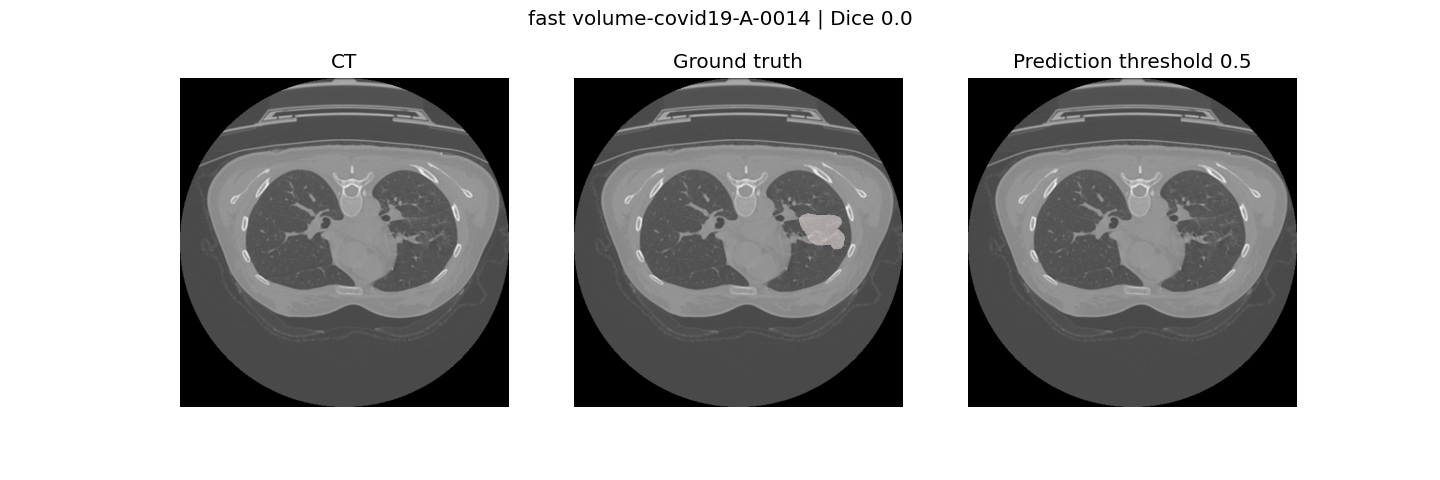

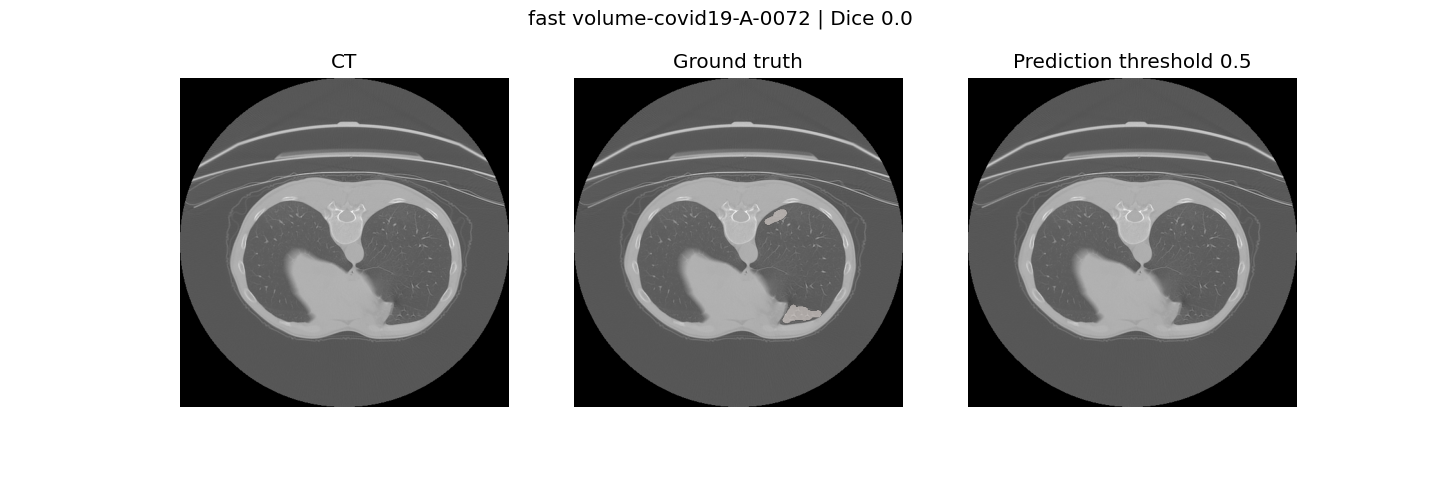

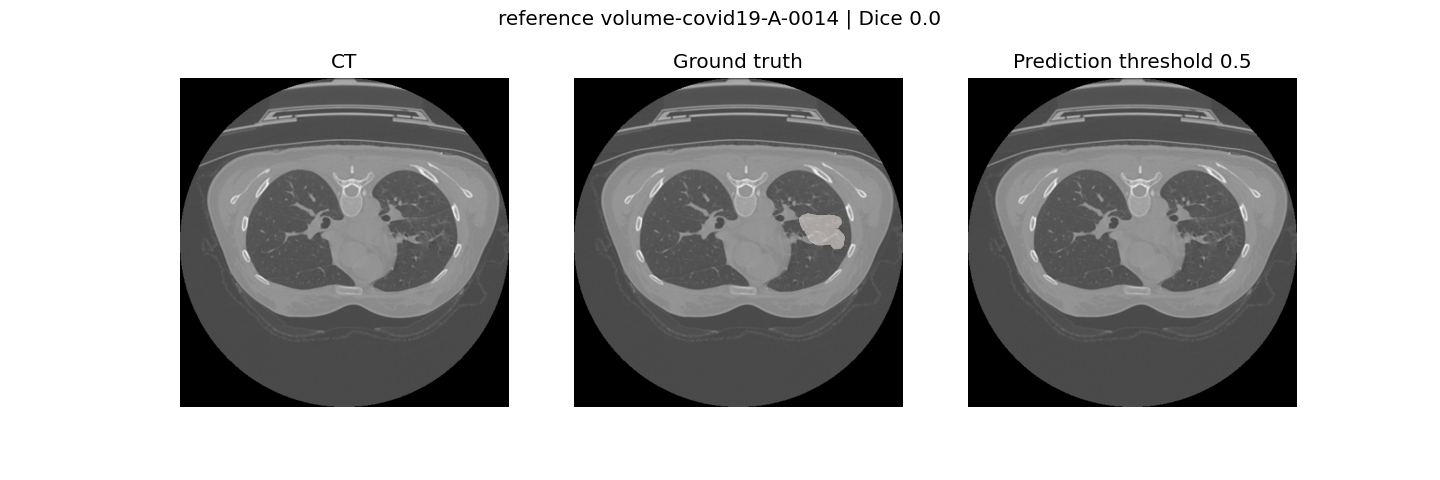

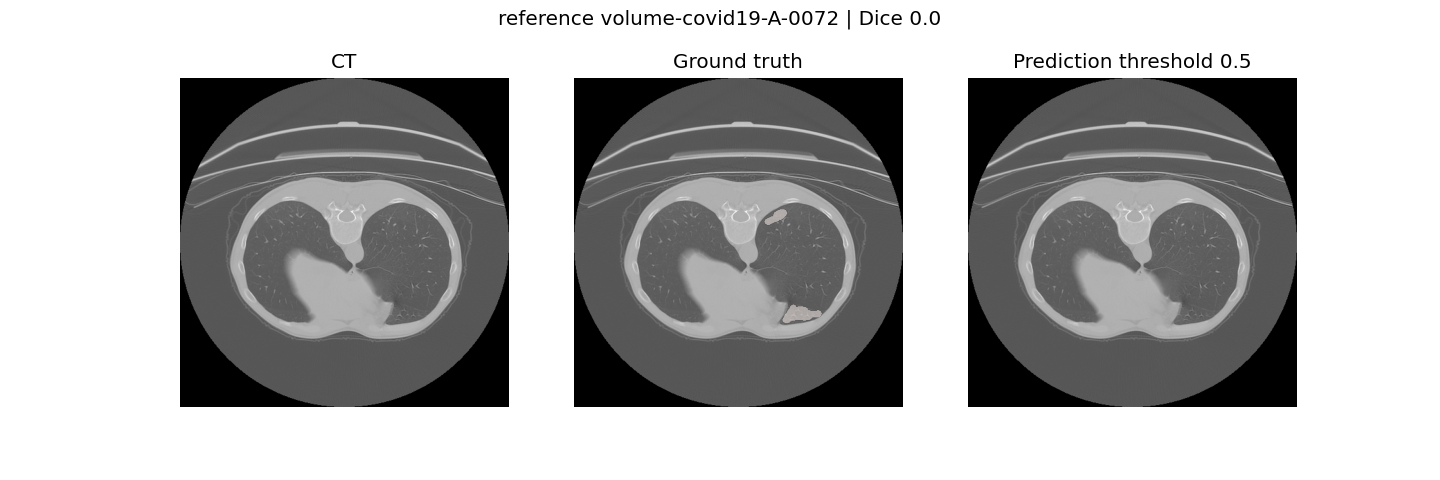

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
# MER_PAIRED_QUALITY_PILOT_V1
QUALITY_BOOTSTRAP = 'SOURCE_BUNDLE_B64 = \'...\'\nSOURCE_SHA256 = \'1e80327012a426cd4216b7bcec59877bafa72e25ac180bbe22927f50f5e1cf34\'\nSOURCE_COMMIT = \'bb8ffe75c2187a6d2346de190c55806040f37690\'\nCASE_SPECS = [{\'case_id\': \'volume-covid19-A-0025\', \'group_id\': \'volume-covid19-A-0025\', \'fold\': 0, \'ct_name\': \'volume-covid19-A-0025_ct.nii.gz\', \'gt_name\': \'volume-covid19-A-0025_seg.nii.gz\', \'shape_xyz\': [512, 512, 61], \'masters\': [30, 0], \'sha256\': {\'ct\': \'105b590753619c608e241001aee1ff5c1add4f432103930825d460bf8a2bb8b6\', \'gt\': \'bd90a1e4a856269b8e2fcc9da18f6eecbc834750db0ba0806796692bc7d4407c\'}, \'file_sizes\': {\'ct\': 16807949, \'gt\': 66366}, \'split_sha256_lf\': \'7b31f9e250e64826f1fff0d9fec4a4aba034252cec7d5123d5f0393ec665e54d\', \'manifest_fingerprint\': \'c1a313cd1e57a8e526108fd413ed052d00afab2b72ac9392595e603a742ffde0\'}, {\'case_id\': \'volume-covid19-A-0295\', \'group_id\': \'volume-covid19-A-0295\', \'fold\': 0, \'ct_name\': \'volume-covid19-A-0295_ct.nii.gz\', \'gt_name\': \'volume-covid19-A-0295_seg.nii.gz\', \'shape_xyz\': [512, 512, 48], \'masters\': [22, 0], \'sha256\': {\'ct\': \'a8c40c0bbb639b6ce1e52c19420285f0a37e0d4344f764343a77598698db58d1\', \'gt\': \'e802299984da902640ca3f4588d503f370acd01537d9599c336e9768915962e5\'}, \'file_sizes\': {\'ct\': 13405570, \'gt\': 29089}, \'split_sha256_lf\': \'7b31f9e250e64826f1fff0d9fec4a4aba034252cec7d5123d5f0393ec665e54d\', \'manifest_fingerprint\': \'c1a313cd1e57a8e526108fd413ed052d00afab2b72ac9392595e603a742ffde0\'}, {\'case_id\': \'volume-covid19-A-0387\', \'group_id\': \'volume-covid19-A-0387\', \'fold\': 0, \'ct_name\': \'volume-covid19-A-0387_ct.nii.gz\', \'gt_name\': \'volume-covid19-A-0387_seg.nii.gz\', \'shape_xyz\': [512, 512, 63], \'masters\': [31, 0], \'sha256\': {\'ct\': \'ef0155c46794e09e06b42c192abb421078abe54d3e8a266806a842cb544600f9\', \'gt\': \'d1c8b76c4b1604dc0ffd847fd72b895264a070cee154312ef2d955785f6f2638\'}, \'file_sizes\': {\'ct\': 17573063, \'gt\': 65329}, \'split_sha256_lf\': \'7b31f9e250e64826f1fff0d9fec4a4aba034252cec7d5123d5f0393ec665e54d\', \'manifest_fingerprint\': \'c1a313cd1e57a8e526108fd413ed052d00afab2b72ac9392595e603a742ffde0\'}]\nDATASET_REVISION = \'e6ce5e1c01f59b29843e6a969655a42d33a52729\'\nMEASURED_ROUNDS = 2  # 12 measured updates + 1 warmup per variant; max 3 rounds.\n\nimport base64, datetime, hashlib, io, json, os, subprocess, sys, uuid, zipfile\nfrom pathlib import Path\nBASE = Path(os.environ.get("MERIT_ATTENTION_HOME", "/content/merit-attention-pilot"))\nBASE.mkdir(parents=True, exist_ok=True)\nRUN = BASE / (datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%d_%H%M%S") + "_" + uuid.uuid4().hex[:8])\nRUN.mkdir()\nPROJECT = BASE / ("source_" + SOURCE_SHA256[:16])\nDATA = Path(os.environ.get("MERIT_ATTENTION_DATA", str(BASE / "data")))\nDATA.mkdir(parents=True, exist_ok=True)\nraw = base64.b64decode(SOURCE_BUNDLE_B64)\nassert hashlib.sha256(raw).hexdigest() == SOURCE_SHA256\nwith zipfile.ZipFile(io.BytesIO(raw)) as archive:\n    for name in archive.namelist():\n        target = (PROJECT / name).resolve()\n        if not target.is_relative_to(PROJECT.resolve()):\n            raise ValueError("Invalid archive path")\n    archive.extractall(PROJECT)\n    SOURCE_FILES = {name: hashlib.sha256(archive.read(name)).hexdigest() for name in archive.namelist()}\n(RUN / "case-specifications.json").write_text(json.dumps(CASE_SPECS, indent=2))\n(RUN / "source-provenance.json").write_text(json.dumps(dict(source_archive_sha256=SOURCE_SHA256,\n    git_commit=SOURCE_COMMIT, includes_local_changes=True, source_files=SOURCE_FILES), indent=2))\nENV = dict(os.environ, PYTHONPATH=os.pathsep.join([str(PROJECT / "src"), str(PROJECT)]),\n    CUBLAS_WORKSPACE_CONFIG=":4096:8", OMP_NUM_THREADS="2", OPENBLAS_NUM_THREADS="1",\n    PYTEST_DISABLE_PLUGIN_AUTOLOAD="1")\nPREPARATION_ERROR = None\nprint("Source:", SOURCE_SHA256)\nprint("Cases:", [s["case_id"] for s in CASE_SPECS])\nprint("Results:", RUN)'
QUALITY_PREPARATION = '# Cài phần còn thiếu; giữ nguyên Torch/CUDA của runtime Colab.\nimport importlib.metadata as metadata\nfrom packaging.specifiers import SpecifierSet\nrequirements = {"numpy": ">=1.24", "scipy": ">=1.10", "nibabel": ">=5",\n                "PyYAML": ">=6", "monai": "==1.5.2", "einops": "==0.8.2", "pytest": ">=7"}\ntry:\n    if metadata.version("torch") not in SpecifierSet(">=2.4.1"):\n        raise RuntimeError("Runtime cần Torch >=2.4.1; notebook không thay Torch/CUDA.")\n    missing = []\n    for package, version in requirements.items():\n        try:\n            installed = metadata.version(package)\n        except metadata.PackageNotFoundError:\n            installed = None\n        if installed is None or installed not in SpecifierSet(version):\n            missing.append(package + version)\n    if missing:\n        result = subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "--no-deps", *missing],\n            text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, env=ENV)\n        (RUN / "installation.log").write_text(result.stdout)\n        if result.returncode:\n            raise RuntimeError("Cài dependency thất bại; xem installation.log")\n    probe = subprocess.run([sys.executable, "-c", "import torch,json; print(json.dumps(dict(torch=torch.__version__, cuda=torch.version.cuda, available=torch.cuda.is_available(), gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else None)))"],\n        capture_output=True, text=True, env=ENV)\n    (RUN / "environment-probe.log").write_text(probe.stdout + probe.stderr)\n    if probe.returncode:\n        raise RuntimeError("Không khởi tạo được Torch/CUDA; xem environment-probe.log")\n    ENVIRONMENT = json.loads(probe.stdout.strip().splitlines()[-1])\n    if not ENVIRONMENT["available"]:\n        raise RuntimeError("Chưa có GPU. Chọn kernel/runtime Colab GPU rồi Run All lại.")\n    (RUN / "environment.json").write_text(json.dumps(ENVIRONMENT, indent=2))\n    print(ENVIRONMENT)\nexcept Exception as error:\n    PREPARATION_ERROR = str(error)\n    print("PREPARATION FAILED:", PREPARATION_ERROR)\n# Chỉ tải 3 ca; file cache chỉ dùng lại nếu đúng SHA-256.\nimport time, urllib.request\ndef digest(path):\n    value = hashlib.sha256()\n    with path.open("rb") as stream:\n        for block in iter(lambda: stream.read(1024 * 1024), b""):\n            value.update(block)\n    return value.hexdigest()\nif PREPARATION_ERROR is None:\n    try:\n        for spec in CASE_SPECS:\n            for kind, name in (("ct", spec["ct_name"]), ("gt", spec["gt_name"])):\n                target = DATA / name\n                if not target.is_file() or digest(target) != spec["sha256"][kind]:\n                    url = f"https://huggingface.co/datasets/MedOtter/COVID-19-20/resolve/{DATASET_REVISION}/Train/{name}"\n                    partial = target.with_suffix(target.suffix + ".partial")\n                    for attempt in range(3):\n                        try:\n                            with urllib.request.urlopen(url, timeout=60) as source, partial.open("wb") as sink:\n                                for block in iter(lambda: source.read(1024 * 1024), b""):\n                                    sink.write(block)\n                            if digest(partial) != spec["sha256"][kind]:\n                                raise ValueError("Downloaded data differs from your local CT/GT: " + name)\n                            partial.replace(target)\n                            break\n                        except Exception:\n                            if attempt == 2:\n                                raise\n                            time.sleep(2 * (attempt + 1))\n                print("Hash OK:", name)\n        (RUN / "preparation.json").write_text(json.dumps(dict(status="PASS", cases=len(CASE_SPECS), files=6)))\n    except Exception as error:\n        PREPARATION_ERROR = str(error)\nif PREPARATION_ERROR:\n    (RUN / "preparation.json").write_text(json.dumps(dict(status="FAIL", error=PREPARATION_ERROR)))\n    print("PREPARATION FAILED:", PREPARATION_ERROR)'
QUALITY_SPECS = {'train': [{'case_id': 'volume-covid19-A-0025', 'group_id': 'volume-covid19-A-0025', 'fold': 0, 'ct_name': 'volume-covid19-A-0025_ct.nii.gz', 'gt_name': 'volume-covid19-A-0025_seg.nii.gz', 'shape_xyz': [512, 512, 61], 'masters': [30, 0], 'sha256': {'ct': '105b590753619c608e241001aee1ff5c1add4f432103930825d460bf8a2bb8b6', 'gt': 'bd90a1e4a856269b8e2fcc9da18f6eecbc834750db0ba0806796692bc7d4407c'}, 'file_sizes': {'ct': 16807949, 'gt': 66366}, 'split_sha256_lf': '7b31f9e250e64826f1fff0d9fec4a4aba034252cec7d5123d5f0393ec665e54d', 'manifest_fingerprint': 'c1a313cd1e57a8e526108fd413ed052d00afab2b72ac9392595e603a742ffde0'}, {'case_id': 'volume-covid19-A-0295', 'group_id': 'volume-covid19-A-0295', 'fold': 0, 'ct_name': 'volume-covid19-A-0295_ct.nii.gz', 'gt_name': 'volume-covid19-A-0295_seg.nii.gz', 'shape_xyz': [512, 512, 48], 'masters': [22, 0], 'sha256': {'ct': 'a8c40c0bbb639b6ce1e52c19420285f0a37e0d4344f764343a77598698db58d1', 'gt': 'e802299984da902640ca3f4588d503f370acd01537d9599c336e9768915962e5'}, 'file_sizes': {'ct': 13405570, 'gt': 29089}, 'split_sha256_lf': '7b31f9e250e64826f1fff0d9fec4a4aba034252cec7d5123d5f0393ec665e54d', 'manifest_fingerprint': 'c1a313cd1e57a8e526108fd413ed052d00afab2b72ac9392595e603a742ffde0'}, {'case_id': 'volume-covid19-A-0387', 'group_id': 'volume-covid19-A-0387', 'fold': 0, 'ct_name': 'volume-covid19-A-0387_ct.nii.gz', 'gt_name': 'volume-covid19-A-0387_seg.nii.gz', 'shape_xyz': [512, 512, 63], 'masters': [31, 0], 'sha256': {'ct': 'ef0155c46794e09e06b42c192abb421078abe54d3e8a266806a842cb544600f9', 'gt': 'd1c8b76c4b1604dc0ffd847fd72b895264a070cee154312ef2d955785f6f2638'}, 'file_sizes': {'ct': 17573063, 'gt': 65329}, 'split_sha256_lf': '7b31f9e250e64826f1fff0d9fec4a4aba034252cec7d5123d5f0393ec665e54d', 'manifest_fingerprint': 'c1a313cd1e57a8e526108fd413ed052d00afab2b72ac9392595e603a742ffde0'}], 'validation': [{'case_id': 'volume-covid19-A-0014', 'group_id': 'volume-covid19-A-0014', 'ct_name': 'volume-covid19-A-0014_ct.nii.gz', 'gt_name': 'volume-covid19-A-0014_seg.nii.gz', 'sha256': {'ct': '7a52835fca6b7cb2bea209fa28c211f4236749dc9def90be16a41376586392fb', 'gt': '1028bcfdc9fc0732aac9036c424c0a4d72188c4bea6373e768e8659fa54a0f6e'}}, {'case_id': 'volume-covid19-A-0072', 'group_id': 'volume-covid19-A-0072', 'ct_name': 'volume-covid19-A-0072_ct.nii.gz', 'gt_name': 'volume-covid19-A-0072_seg.nii.gz', 'sha256': {'ct': '6dc2ab962cdebf5c2b88c8499bc1ee9c793a47c48d92862a197b15e65e017206', 'gt': 'a8cc2fc2b13da71d8e8d9e5d7a93bfbedbdd1df64cb17babbf8dc4a0bbd64793'}}], 'split_sha256_lf': '7b31f9e250e64826f1fff0d9fec4a4aba034252cec7d5123d5f0393ec665e54d'}
QUALITY_SOURCES = {'tools/merit_factorized_attention.py': '"""Diagnostic MER variant that factors squared XY bias into query/key.\n\nThis preserves the full-context softmax in exact arithmetic. CUDA reduced\nprecision can introduce different rounding; validate outputs and gradients.\n"""\nimport math\nimport types\n\nimport torch\nfrom torch.nn import functional as F\nfrom torch.utils.checkpoint import checkpoint\n\nfrom merit_covid.models.merit_unetrpp.modules import (\n    _attention_validity, _check_features, master_positions, relative_offsets, sinusoidal_encoding,\n)\n\n\ndef factorized_mer(self, features, master_index, z_offsets_mm=None, attention_valid=None):\n    _check_features(features, self.channels)\n    batch, channels, depth, height, width = features.shape\n    if depth < 2:\n        raise ValueError("MER needs at least one context slice")\n    master = master_positions(master_index, batch, depth, features.device)\n    rows = torch.arange(batch, device=features.device)\n    positions = torch.arange(depth, device=features.device).expand(batch, -1)\n    context_indices = positions[positions != master[:, None]].reshape(batch, depth - 1)\n    valid = _attention_validity(attention_valid, master, depth)\n    context_valid = None if valid is None else valid[rows[:, None], context_indices]\n    slices = features.permute(0, 2, 3, 4, 1).reshape(batch, depth, height * width, channels)\n    master_features = slices[rows, master]\n    context = slices[rows[:, None], context_indices]\n    offsets = relative_offsets(master, depth, mode=self.position_mode,\n        z_offsets_mm=z_offsets_mm, unit_mm=self.position_unit_mm)[rows[:, None], context_indices]\n    pe = sinusoidal_encoding(offsets, channels, dtype=context.dtype)[:, :, None]\n    query = self.query(master_features)\n    keys = self.key(context + self.position_scale * pe).flatten(1, 2)\n    values = self.value(context).flatten(1, 2)\n    coords = torch.stack(torch.meshgrid(torch.arange(height, device=features.device),\n        torch.arange(width, device=features.device), indexing="ij"), -1).reshape(-1, 2)\n    # ||x-y||²/(H²+W²): remove query-only term because softmax is invariant to it.\n    coords = coords.to(torch.float32) / math.sqrt(height ** 2 + width ** 2)\n    key_positions = coords.repeat(depth - 1, 1)\n    extra_keys = torch.cat((key_positions, key_positions.square().sum(-1, keepdim=True)), dim=-1)\n    padded_dim = ((self.attention_dim + 3 + 7) // 8) * 8\n    extra_padding = padded_dim - self.attention_dim - 3\n    keys = torch.cat((keys, F.pad(extra_keys.to(keys.dtype), (0, extra_padding))[None].expand(batch, -1, -1)), dim=-1)\n    mask = has_context = None\n    if context_valid is not None:\n        token_valid = context_valid.repeat_interleave(height * width, dim=1)\n        has_context = token_valid.any(dim=1)\n        safe_valid = token_valid.clone()\n        safe_valid[~has_context, 0] = True\n        mask = safe_valid[:, None, None, :]\n\n    def attention(block, all_keys, all_values, block_coords, scale_raw):\n        scale = F.softplus(scale_raw).float()\n        position = torch.cat((2 * scale * block_coords, -scale * torch.ones_like(block_coords[:, :1])), dim=-1)\n        # Keep the original 1/sqrt(d) attention scale explicitly: rescaling\n        # learned query channels under FP16 introduces avoidable rounding.\n        position = F.pad(position * math.sqrt(self.attention_dim), (0, extra_padding)).to(block.dtype)\n        padded_query = torch.cat((block, position[None].expand(batch, -1, -1)), dim=-1)\n        result = F.scaled_dot_product_attention(padded_query[:, None], all_keys[:, None], all_values[:, None],\n            attn_mask=mask, dropout_p=0.0, scale=1 / math.sqrt(self.attention_dim)).squeeze(1)\n        return result if has_context is None else result * has_context[:, None, None]\n\n    updates = []\n    for start in range(0, height * width, self.query_chunk_size):\n        stop = start + self.query_chunk_size\n        args = (query[:, start:stop], keys, values, coords[start:stop], self.distance_scale_raw)\n        result = (checkpoint(attention, *args, use_reentrant=False, preserve_rng_state=True)\n                  if self.training and torch.is_grad_enabled() else attention(*args))\n        updates.append(result)\n    evidence = self.output(torch.cat(updates, dim=1))\n    gate = self.gate(torch.cat((master_features, evidence), dim=-1))\n    updated = master_features + self.beta * gate * evidence\n    result = slices.clone()\n    result[rows, master] = updated\n    return result.reshape(batch, depth, height, width, channels).permute(0, 4, 1, 2, 3).contiguous()\n\n\ndef enable_factorized_mer(model):\n    if model.mer is None:\n        raise ValueError("Model needs MER")\n    model.mer.forward = types.MethodType(factorized_mer, model.mer)\n    return model\n', 'tools/merit_factorized_pilot.py': '"""Benchmark factorized MER on the same diagnostic as the original pilot."""\nimport argparse\nimport json\nfrom pathlib import Path\n\nfrom merit_covid.engine import activation_checkpointing as execution\nfrom tools.merit_factorized_attention import enable_factorized_mer\nfrom tools.merit_attention_pilot import run_pilot\n\n\ndef run_factorized(config, data_dir, specs, output, *, device="cuda", rounds=1):\n    original = execution.configure_model_execution\n    def candidate(model, settings):\n        return enable_factorized_mer(original(model, settings))\n    execution.configure_model_execution = candidate\n    try:\n        return run_pilot(config, data_dir, specs, output, variant="optimized", device=device, rounds=rounds)\n    finally:\n        execution.configure_model_execution = original\n\n\ndef main():\n    parser = argparse.ArgumentParser(description=__doc__)\n    for key in ("config", "data-dir", "specs", "output"):\n        parser.add_argument("--" + key, required=True, type=Path)\n    parser.add_argument("--rounds", type=int, default=1)\n    args = parser.parse_args()\n    result = run_factorized(args.config, args.data_dir, json.loads(args.specs.read_text()), args.output, rounds=args.rounds)\n    print("Factorized pilot:", result["status"], flush=True)\n    return 0 if result["status"] == "PASS" else 1\n\n\nif __name__ == "__main__":\n    raise SystemExit(main())\n', 'tests/test_mer_factorized_attention.py': '"""Full MER output and parameter gradients against original distance bias."""\nfrom copy import deepcopy\nimport types\n\nimport pytest\nimport torch\n\nfrom merit_covid.engine.activation_checkpointing import checkpointed_mer\nfrom merit_covid.models.merit_unetrpp import MasterEvidenceRouting\nfrom tools.merit_factorized_attention import factorized_mer\n\n\n@pytest.mark.parametrize("masked", [False, True])\n@pytest.mark.parametrize("training", [False, True])\n@pytest.mark.parametrize("position_mode", ["index", "physical_mm"])\ndef test_factorized_mer_matches_original_output_and_gradients(masked, training, position_mode):\n    torch.manual_seed(813)\n    reference = MasterEvidenceRouting(4, attention_dim=8, gate_hidden=3, query_chunk_size=5,\n                                      position_mode=position_mode)\n    candidate = deepcopy(reference)\n    reference.forward = types.MethodType(checkpointed_mer, reference)\n    candidate.forward = types.MethodType(factorized_mer, candidate)\n    reference.train(training)\n    candidate.train(training)\n    image = torch.randn(2, 4, 3, 4, 6)\n    offsets = torch.tensor([[0., 2.5, 7.], [-8., -3., 0.]])\n    mask = torch.tensor([[True, True, False], [False, False, True]]) if masked else None\n    tensors, outputs = [], []\n    for model in (reference, candidate):\n        x = image.clone().requires_grad_()\n        y = model(x, [0, 2], offsets, mask)\n        y.square().mean().backward()\n        tensors.append(x)\n        outputs.append(y)\n    torch.testing.assert_close(outputs[0], outputs[1], rtol=1e-5, atol=1e-6)\n    torch.testing.assert_close(tensors[0].grad, tensors[1].grad, rtol=1e-5, atol=1e-7)\n    for (name, a), (_, b) in zip(reference.named_parameters(), candidate.named_parameters()):\n        assert a.grad is not None and b.grad is not None\n        torch.testing.assert_close(a.grad, b.grad, rtol=1e-4, atol=1e-7, msg=name)\n    if masked:\n        torch.testing.assert_close(outputs[1][1, :, 2], image[1, :, 2], rtol=0, atol=0)\n\n\n@pytest.mark.skipif(not torch.cuda.is_available(), reason="CUDA required")\n@pytest.mark.parametrize("masked", [False, True])\n@pytest.mark.parametrize("amp", [False, True])\ndef test_factorized_mer_cuda_matches_original_output_and_gradients(masked, amp):\n    torch.manual_seed(813)\n    reference = MasterEvidenceRouting(4, attention_dim=8, gate_hidden=3, query_chunk_size=5,\n                                      position_mode="physical_mm").cuda().train()\n    candidate = deepcopy(reference)\n    reference.forward = types.MethodType(checkpointed_mer, reference)\n    candidate.forward = types.MethodType(factorized_mer, candidate)\n    image = torch.randn(2, 4, 3, 4, 6).cuda()\n    offsets = torch.tensor([[0., 2.5, 7.], [-8., -3., 0.]])\n    mask = torch.tensor([[True, True, False], [False, False, True]]) if masked else None\n    tensors, outputs = [], []\n    for model in (reference, candidate):\n        x = image.clone().requires_grad_()\n        with torch.autocast("cuda", dtype=torch.float16, enabled=amp):\n            y = model(x, [0, 2], offsets, mask)\n            loss = y.square().mean()\n        loss.backward()\n        tensors.append(x)\n        outputs.append(y)\n    rtol, atol = (5e-3, 2e-6) if amp else (1e-4, 1e-7)\n    torch.testing.assert_close(outputs[0], outputs[1], rtol=rtol, atol=atol)\n    torch.testing.assert_close(tensors[0].grad, tensors[1].grad, rtol=rtol, atol=atol)\n    for (name, a), (_, b) in zip(reference.named_parameters(), candidate.named_parameters()):\n        assert a.grad is not None and b.grad is not None\n        assert torch.isfinite(b.grad).all()\n        torch.testing.assert_close(a.grad, b.grad, rtol=rtol, atol=atol, msg=name)\n    assert candidate.distance_scale_raw.grad.abs() > 0\n    if masked:\n        torch.testing.assert_close(outputs[1][1, :, 2], image[1, :, 2], rtol=0, atol=0)\n', 'tools/merit_runtime_profile.py': '"""Four-step native-input diagnosis: actual SDPA kernels and CPU/GPU hotspots.\n\nDiagnostic execution only. An explicit efficient backend applies to MER alone,\ninside each attention call, so checkpoint recomputation uses the same backend.\n"""\nimport argparse\nfrom contextlib import nullcontext\nimport json\nfrom pathlib import Path\nimport statistics\nimport time\nimport traceback\nfrom unittest.mock import patch\nimport warnings\n\nimport torch\nfrom torch.nn.attention import SDPBackend, sdpa_kernel\n\nfrom merit_covid.data.pipeline.config import PreprocessConfig\nfrom merit_covid.data.pipeline.dataset import CTSlabDataset\nfrom merit_covid.data.pipeline.dataloader import collate_slabs\nfrom merit_covid.engine import activation_checkpointing as execution\nfrom merit_covid.engine.preflight import _setup, _sync, _state_hash, _memory\nfrom merit_covid.engine.training import load_experiment, validate_experiment\nfrom merit_covid.models.merit_unetrpp import MERITUNETRPP, MERITLoss, modules\nfrom tools.merit_real_case_trial import file_hash, verified_case\n\n\ndef event_row(event):\n    return dict(name=event.key, count=int(event.count),\n        self_cpu_ms=float(event.self_cpu_time_total) / 1000,\n        total_cpu_ms=float(event.cpu_time_total) / 1000,\n        self_device_ms=float(getattr(event, "self_device_time_total", 0)) / 1000,\n        total_device_ms=float(getattr(event, "device_time_total", 0)) / 1000)\n\n\ndef run_profile(config_path, data_dir, specs, output, *, backend="auto", device="cuda"):\n    output = Path(output)\n    if output.exists():\n        raise FileExistsError(output)\n    output.parent.mkdir(parents=True, exist_ok=True)\n    report = dict(status="NOT_RUN", backend=backend, batches=[], scope="one TRAIN case, one master, four updates",\n                  full_training=False, accuracy_evaluated=False)\n    case = before = None\n    try:\n        if backend not in ("auto", "efficient") or (backend == "efficient" and device != "cuda"):\n            raise ValueError("Efficient-backend diagnosis requires CUDA")\n        spec = specs[0]\n        config = load_experiment(config_path)\n        config["training"].update(device=device, batch_size=1, num_workers=0)\n        config = validate_experiment(config)\n        if (config["preprocess"]["size_hw"] is not None\n                or config["preprocess"]["intensity_encoding"] != "native"\n                or not config["training"]["activation_checkpointing"]):\n            raise ValueError("Requires native input and production checkpointing")\n        case, before, _ = verified_case(Path(data_dir) / spec["ct_name"], Path(data_dir) / spec["gt_name"],\n                                        config["data"]["split_path"], spec)\n        sample = CTSlabDataset([case], PreprocessConfig(**config["preprocess"]))[spec["masters"][0]]\n        if list(sample["image_slab"].shape) != [1, *config["model"]["img_size"]]:\n            raise ValueError("Unexpected native input shape")\n        batch = collate_slabs([sample])\n        resolved = _setup(config)\n        settings = config["training"]\n        amp = settings["amp"] and resolved.type == "cuda"\n        model = execution.configure_model_execution(MERITUNETRPP(**config["model"]).to(resolved), settings).train()\n        model.set_epoch(0, warmup_epochs=settings["warmup_epochs"])\n        report.update(case_id=case.case_id, master=spec["masters"][0], torch_version=torch.__version__,\n            hardware=torch.cuda.get_device_name(resolved) if resolved.type == "cuda" else "CPU",\n            initial_state_sha256=_state_hash(model), input_shape=list(batch["image_slab"].shape),\n            deterministic=torch.are_deterministic_algorithms_enabled())\n        optimizer = torch.optim.AdamW(model.parameters(), lr=settings["learning_rate"],\n                                     weight_decay=settings["weight_decay"])\n        scaler = torch.amp.GradScaler("cuda", enabled=amp, init_scale=settings["amp_init_scale"])\n        criterion = MERITLoss(**config["loss"])\n        image, truth, valid = (batch[k].to(resolved) for k in ("image_slab", "mask_slab", "valid_region"))\n        # Inputs stay on device; these timings diagnose compute, not data loading.\n        for name in ("unetr_pp_encoder", "tep", "mer", "encoder1", "decoder5", "decoder4", "decoder3", "decoder2", "pcg"):\n            module = getattr(model, name, None)\n            if module is None:\n                continue\n            original = module.forward\n            def stage(*args, _original=original, _name=name, **kwargs):\n                with torch.profiler.record_function("merit_stage::" + _name):\n                    return _original(*args, **kwargs)\n            module.forward = stage\n        original_attention = modules._mer_attention\n        calls = [0]\n        def attention(query, keys, values, bias):\n            calls[0] += 1\n            if "mer_first_call" not in report:\n                details = dict(query_shape=list(query.shape), key_shape=list(keys.shape),\n                    query_dtype=str(query.dtype), bias_dtype=str(bias.dtype), bias_requires_grad=bias.requires_grad,\n                    query_stride=list(query.stride()), key_stride=list(keys.stride()))\n                if resolved.type == "cuda":\n                    try:\n                        mask = bias.to(query.dtype)\n                        if mask.ndim == 3:\n                            mask = mask.unsqueeze(1)\n                        params = torch.backends.cuda.SDPAParams(query.unsqueeze(1), keys.unsqueeze(1),\n                            values.unsqueeze(1), mask, 0.0, False, False)\n                        with warnings.catch_warnings(record=True) as captured:\n                            warnings.simplefilter("always")\n                            details["efficient_eligible"] = torch.backends.cuda.can_use_efficient_attention(params, debug=True)\n                        details["eligibility_warnings"] = [str(w.message) for w in captured]\n                    except Exception as error:\n                        details["eligibility_probe_error"] = str(error)\n                report["mer_first_call"] = details\n            with torch.profiler.record_function("merit_stage::mer_sdpa_including_recompute"):\n                with sdpa_kernel(SDPBackend.EFFICIENT_ATTENTION) if backend == "efficient" else nullcontext():\n                    return original_attention(query, keys, values, bias)\n        activities = [torch.profiler.ProfilerActivity.CPU]\n        if resolved.type == "cuda":\n            activities.append(torch.profiler.ProfilerActivity.CUDA)\n            torch.cuda.reset_peak_memory_stats(resolved)\n        with patch.object(modules, "_mer_attention", attention), patch.object(execution, "_mer_attention", attention):\n            for index in range(4):\n                optimizer.zero_grad(set_to_none=True)\n                calls[0] = 0\n                profiler = torch.profiler.profile(activities=activities, record_shapes=False,\n                    profile_memory=False, with_stack=False) if index == 3 else None\n                with profiler if profiler is not None else nullcontext():\n                    _sync(resolved)\n                    started = time.perf_counter()\n                    with torch.profiler.record_function("merit_phase::forward_and_loss"):\n                        with torch.autocast(resolved.type, dtype=torch.float16, enabled=amp):\n                            prediction = model(image, batch["master_index"], batch["z_offsets_mm"], batch.get("attention_valid"))\n                            losses = criterion(prediction, truth, batch["master_index"], valid_region=valid,\n                                               z_offsets_mm=batch["z_offsets_mm"])\n                    if not all(torch.isfinite(loss).all() for loss in losses.values()):\n                        raise FloatingPointError("Nonfinite diagnostic loss")\n                    with torch.profiler.record_function("merit_phase::backward"):\n                        scaler.scale(losses["total"]).backward()\n                    with torch.profiler.record_function("merit_phase::optimizer"):\n                        scaler.unscale_(optimizer)\n                        norm = torch.nn.utils.clip_grad_norm_(model.parameters(), settings["gradient_clip"],\n                                                               error_if_nonfinite=not amp)\n                        previous = scaler.get_scale()\n                        scaler.step(optimizer)\n                        scaler.update()\n                    _sync(resolved)\n                    seconds = time.perf_counter() - started\n                finite = all(p.grad is not None for p in model.parameters()) and bool(torch.stack([\n                    torch.isfinite(p.grad).all() for p in model.parameters() if p.grad is not None]).all())\n                skipped = scaler.get_scale() < previous\n                report["batches"].append(dict(attempt=index + 1, warmup=index == 0, profiled=index == 3,\n                    seconds=seconds, gradients_finite=finite, amp_skipped=skipped, mer_calls=calls[0]))\n                print(f"Profile {backend} {index+1}/4: {seconds:.3f}s profiled={index == 3} skipped={skipped}", flush=True)\n                if not finite or skipped or not torch.isfinite(norm):\n                    raise FloatingPointError("Diagnostic optimizer update was not finite and effective")\n                del prediction, losses\n                if profiler is not None:\n                    events = [event_row(e) for e in profiler.key_averages()]\n                    report["attention_ops"] = [e for e in events if "scaled_dot_product" in e["name"]]\n                    report["stages"] = [e for e in events if e["name"].startswith("merit_")]\n                    report["top_self_cpu"] = sorted(events, key=lambda e: e["self_cpu_ms"], reverse=True)[:15]\n                    report["top_self_device"] = sorted(events, key=lambda e: e["self_device_ms"], reverse=True)[:15]\n                    report["cuda_timing_available"] = any(e["self_device_ms"] > 0 for e in events)\n        report.update(status="PASS", two_step_mean_seconds=statistics.mean(r["seconds"] for r in report["batches"]\n            if not r["warmup"] and not r["profiled"]), **_memory(resolved))\n        report["amp_fp32_retries"] = {n: m._fp32_retry_count for n, m in model.named_modules()\n                                     if getattr(m, "_fp32_retry_count", 0)}\n    except Exception as error:\n        report.update(status="FAIL", error=str(error), traceback=traceback.format_exc())\n        print(report["traceback"], flush=True)\n    finally:\n        if case is not None and before is not None:\n            report["source_files_unchanged"] = before == {"ct": file_hash(case.image), "gt": file_hash(case.mask)}\n            if not report["source_files_unchanged"]:\n                report.update(status="FAIL", error="Source data changed")\n        output.write_text(json.dumps(report, indent=2, allow_nan=False), encoding="utf-8")\n    return report\n\n\ndef main():\n    parser = argparse.ArgumentParser(description=__doc__)\n    for key in ("config", "data-dir", "specs", "output"):\n        parser.add_argument("--" + key, required=True, type=Path)\n    parser.add_argument("--backend", choices=("auto", "efficient"), default="auto")\n    args = parser.parse_args()\n    result = run_profile(args.config, args.data_dir, json.loads(args.specs.read_text()), args.output, backend=args.backend)\n    print("Runtime profile:", result["status"], flush=True)\n    return 0 if result["status"] == "PASS" else 1\n\n\nif __name__ == "__main__":\n    raise SystemExit(main())\n', 'tools/merit_execution_tuning.py': '"""Isolated full-context MER chunk/recomputation experiments, with no protocol edits."""\nimport argparse\nfrom contextlib import contextmanager, nullcontext\nfrom copy import deepcopy\nimport json\nfrom pathlib import Path\nimport types\nfrom unittest.mock import patch\n\nimport torch\n\nfrom merit_covid.engine import activation_checkpointing as execution\nfrom merit_covid.models.merit_unetrpp import MasterEvidenceRouting\nfrom tools import merit_factorized_attention as factor\n\n\n@contextmanager\ndef deterministic_mode(enabled):\n    previous = torch.are_deterministic_algorithms_enabled()\n    warn_only = torch.is_deterministic_algorithms_warn_only_enabled()\n    try:\n        torch.use_deterministic_algorithms(enabled)\n        yield\n    finally:\n        torch.use_deterministic_algorithms(previous, warn_only=warn_only)\n\n\n@contextmanager\ndef recomputation(enabled):\n    def direct(function, *args, **kwargs):\n        kwargs.pop("use_reentrant", None)\n        kwargs.pop("preserve_rng_state", None)\n        return function(*args, **kwargs)\n    with nullcontext() if enabled else patch.object(factor, "checkpoint", direct):\n        yield\n\n\ndef compare(chunk, recompute, *, native=False, amp=True, masked=False, device="cuda", fast_reductions=False):\n    """Check actual outputs and all gradients; native uses the real MER token grid."""\n    torch.manual_seed(842)\n    channels, depth, height, width = (16, 11, 128, 128) if native else (4, 3, 5, 6)\n    reference = MasterEvidenceRouting(channels, attention_dim=64 if native else 8,\n        gate_hidden=16 if native else 3, query_chunk_size=512 if native else 7,\n        position_mode="physical_mm").to(device).train()\n    candidate = deepcopy(reference)\n    candidate.query_chunk_size = chunk\n    for model in (reference, candidate):\n        model.forward = types.MethodType(factor.factorized_mer, model)\n    x = torch.randn(1, channels, depth, height, width, device=device)\n    offsets = (torch.arange(depth, dtype=torch.float32)[None] - depth // 2) * 2.5\n    mask = torch.ones(1, depth, dtype=torch.bool) if masked else None\n    if masked:\n        mask[:, :depth // 2] = False\n    results = []\n    for model, enabled in ((reference, True), (candidate, recompute)):\n        xi = x.detach().clone().requires_grad_()\n        # The reference retains deterministic reductions. The optional candidate\n        # permits parallel reductions; verify its numerical differences explicitly.\n        with recomputation(enabled), deterministic_mode(not fast_reductions or model is reference):\n            with torch.autocast(torch.device(device).type, dtype=torch.float16, enabled=amp):\n                output = model(xi, [depth // 2], offsets, mask)\n                loss = output.square().mean()\n            loss.backward()\n        results.append((output.detach().cpu(), xi.grad.detach().cpu(),\n            {n: p.grad.detach().cpu().clone() for n, p in model.named_parameters()}))\n    rtol, atol = (5e-3, 2e-6) if amp else (1e-4, 1e-7)\n    torch.testing.assert_close(results[0][0], results[1][0], rtol=rtol, atol=atol)\n    torch.testing.assert_close(results[0][1], results[1][1], rtol=rtol, atol=atol)\n    for name, value in results[0][2].items():\n        assert torch.isfinite(results[1][2][name]).all(), name\n        torch.testing.assert_close(value, results[1][2][name], rtol=rtol, atol=atol, msg=name)\n    return dict(status="PASS", chunk=chunk, recompute=recompute, native_token_grid=native,\n        amp=amp, masked=masked, fast_reductions=fast_reductions, rtol=rtol, atol=atol,\n        output_max_abs_diff=float((results[0][0]-results[1][0]).abs().max()),\n        input_grad_max_abs_diff=float((results[0][1]-results[1][1]).abs().max()))\n\n\ndef main():\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("--chunk", type=int, choices=(512, 1024, 4096, 16384), required=True)\n    parser.add_argument("--recompute", choices=("on", "off"), required=True)\n    parser.add_argument("--guard", action="store_true")\n    parser.add_argument("--fast-reductions", action="store_true")\n    for name in ("config", "data-dir", "specs"):\n        parser.add_argument("--"+name, type=Path)\n    parser.add_argument("--output", type=Path, required=True)\n    args = parser.parse_args()\n    if args.guard:\n        # Compare at the actual MER grid before a full-model native CT worker.\n        result = compare(args.chunk, args.recompute == "on", native=True, fast_reductions=args.fast_reductions)\n        args.output.write_text(json.dumps(result, indent=2), encoding="utf-8")\n        print("Native MER guard:", result, flush=True)\n        return\n    from tools import merit_attention_pilot as pilot\n    original_setup = pilot._setup\n    def setup(config):\n        if args.fast_reductions:\n            config["training"]["deterministic"] = False\n        return original_setup(config)\n    original = execution.configure_model_execution\n    def configure(model, settings):\n        model = factor.enable_factorized_mer(original(model, settings))\n        model.mer.query_chunk_size = args.chunk\n        return model\n    with patch.object(pilot, "_setup", setup), patch.object(execution, "configure_model_execution", configure), recomputation(args.recompute == "on"):\n        result = pilot.run_pilot(args.config, args.data_dir,\n            json.loads(args.specs.read_text(encoding="utf-8")), args.output,\n            variant="optimized", rounds=1)\n    print("Execution tuning:", args.chunk, args.recompute, result["status"], flush=True)\n    if result["status"] != "PASS":\n        raise SystemExit(1)\n\n\nif __name__ == "__main__":\n    main()\n', 'tests/test_mer_execution_tuning.py': '"""Compare recomputation changes, large chunks, masks and gradients."""\nimport pytest\nimport torch\n\nfrom tools.merit_execution_tuning import compare\n\n\n@pytest.mark.parametrize("recompute", [True, False])\n@pytest.mark.parametrize("masked", [True, False])\n@pytest.mark.parametrize("amp", [True, False])\ndef test_full_query_and_recomputation(recompute, masked, amp):\n    if amp and not torch.cuda.is_available():\n        pytest.skip("CUDA AMP required")\n    device = "cuda" if torch.cuda.is_available() else "cpu"\n    compare(16384, recompute, native=False, amp=amp, masked=masked, device=device)\n\n\n@pytest.mark.parametrize("masked", [True, False])\n@pytest.mark.parametrize("amp", [True, False])\ndef test_parallel_reductions_match_reference(masked, amp):\n    if amp and not torch.cuda.is_available():\n        pytest.skip("CUDA AMP required")\n    previous = torch.are_deterministic_algorithms_enabled()\n    device = "cuda" if torch.cuda.is_available() else "cpu"\n    compare(4096, True, native=False, amp=amp, masked=masked, device=device, fast_reductions=True)\n    assert torch.are_deterministic_algorithms_enabled() == previous\n\n\n@pytest.mark.parametrize("amp", [True, False])\ndef test_parallel_reductions_full_model(amp):\n    from copy import deepcopy\n    from merit_covid.models.merit_unetrpp import MERITUNETRPP, MERITLoss\n    from tools.merit_execution_tuning import deterministic_mode, execution, factor\n    if amp and not torch.cuda.is_available():\n        pytest.skip("CUDA AMP required")\n    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")\n    torch.manual_seed(925)\n    model = MERITUNETRPP(img_size=(11,32,32),feature_size=2,depths=(1,1,1,1),query_chunk_size=4096).to(device).train()\n    models = [model,deepcopy(model)]\n    for m in models:\n        factor.enable_factorized_mer(execution.configure_model_execution(m,{"activation_checkpointing":True,"amp":amp}))\n    x=torch.randn(1,1,11,32,32,device=device)\n    target=torch.zeros_like(x);target[:,:,:,6:9,8:12]=1\n    cpu_rng=torch.get_rng_state();gpu_rng=torch.cuda.get_rng_state_all() if device.type=="cuda" else None\n    results=[]\n    for m,deterministic in zip(models,(True,False)):\n        torch.set_rng_state(cpu_rng)\n        if gpu_rng is not None:torch.cuda.set_rng_state_all(gpu_rng)\n        xi=x.detach().clone().requires_grad_()\n        with deterministic_mode(deterministic):\n            with torch.autocast(device.type,dtype=torch.float16,enabled=amp):\n                prediction=m(xi,[5])\n                losses=MERITLoss()(prediction,target,[5])\n            losses["total"].backward()\n        results.append((prediction.logits.detach(),xi.grad.detach(),losses))\n    rtol,atol=(5e-3,2e-6) if amp else (1e-4,1e-7)\n    torch.testing.assert_close(results[0][0],results[1][0],rtol=rtol,atol=atol)\n    torch.testing.assert_close(results[0][1],results[1][1],rtol=rtol,atol=atol)\n    for key in results[0][2]:\n        torch.testing.assert_close(results[0][2][key],results[1][2][key],rtol=rtol,atol=atol,msg=key)\n    for (name,p),(_,q) in zip(models[0].named_parameters(),models[1].named_parameters()):\n        assert p.grad is not None and q.grad is not None,name\n        torch.testing.assert_close(p.grad,q.grad,rtol=rtol,atol=atol,msg=name)\n', 'tools/merit_quality_pilot.py': '"""Paired learning diagnostic on real TRAIN cases and fixed held-out volumes.\n\nStarts from random initialization. This is NOT an evaluation of the user\'s\nKaggle checkpoint or evidence of convergence after complete training.\n"""\nimport argparse\nfrom contextlib import ExitStack\nimport gc\nimport json\nfrom pathlib import Path\nimport time\nfrom unittest.mock import patch\n\nimport nibabel as nib\nimport numpy as np\nimport torch\n\nfrom merit_covid.data.pipeline.config import PreprocessConfig\nfrom merit_covid.data.pipeline.dataset import CTSlabDataset\nfrom merit_covid.data.pipeline.dataloader import collate_slabs\nfrom merit_covid.data.pipeline.metrics import volume_metrics, aggregate_results\nfrom merit_covid.engine.preflight import _setup, _state_hash, _sync, _memory\nfrom merit_covid.engine.slab_inference import predict_slab_case\nfrom merit_covid.engine.training import load_experiment, validate_experiment\nfrom merit_covid.engine import activation_checkpointing as execution\nfrom merit_covid.models.merit_unetrpp import MERITUNETRPP, MERITLoss\nfrom tools.merit_execution_tuning import recomputation\nfrom tools.merit_factorized_attention import enable_factorized_mer\nfrom tools.merit_real_case_trial import file_hash\n\n\ndef verify_cases(specs, data, split, partition):\n    from merit_covid.data.pipeline.cases import Case\n    allowed = split[\'folds\'][0][partition]\n    result = []\n    for spec in specs:\n        if spec[\'case_id\'] not in allowed[\'case_ids\'] or spec[\'group_id\'] not in allowed[\'group_ids\']:\n            raise ValueError(\'Case/group does not belong to \'+partition)\n        for other in (\'train\',\'validation\',\'test\'):\n            if other != partition and (spec[\'case_id\'] in split[\'folds\'][0][other][\'case_ids\'] or\n                                     spec[\'group_id\'] in split[\'folds\'][0][other][\'group_ids\']):\n                raise ValueError(\'Partition overlap\')\n        ct, gt = data/spec[\'ct_name\'], data/spec[\'gt_name\']\n        if {\'ct\':file_hash(ct),\'gt\':file_hash(gt)} != spec[\'sha256\']:\n            raise ValueError(\'Source bytes changed: \'+spec[\'case_id\'])\n        result.append(Case(spec[\'case_id\'],ct,gt,spec[\'group_id\']))\n    return result\n\n\ndef main():\n    parser=argparse.ArgumentParser(description=__doc__)\n    for name in (\'config\',\'data-dir\',\'specs\',\'output\',\'shared\'):\n        parser.add_argument(\'--\'+name,type=Path,required=True)\n    parser.add_argument(\'--variant\',choices=(\'reference\',\'fast\'),required=True)\n    args=parser.parse_args()\n    if args.output.exists(): raise FileExistsError(args.output)\n    args.output.parent.mkdir(parents=True,exist_ok=True)\n    args.shared.mkdir(parents=True,exist_ok=True)\n    report=dict(status=\'RUNNING\',variant=args.variant,\n        scope=\'24 diagnostic updates from random initialization on 3 TRAIN cases; 2 complete held-out validation volumes\',\n        kaggle_checkpoint_evaluated=False,full_training=False,steps=[])\n    phase_file=args.output.with_suffix(\'.progress.json\')\n    def phase(name, **details):\n        entry=dict(phase=name,time=time.time(),variant=args.variant,**details)\n        temp=phase_file.with_suffix(\'.tmp\')\n        temp.write_text(json.dumps(entry),encoding=\'utf-8\');temp.replace(phase_file)\n        print(\'PHASE\',args.variant,name,json.dumps(details),flush=True)\n    phase(\'setup\')\n    config=load_experiment(args.config)\n    fast=args.variant==\'fast\'\n    config[\'training\'].update(device=\'cuda\',deterministic=not fast)\n    config=validate_experiment(config)\n    specs=json.loads(args.specs.read_text(encoding=\'utf-8\'))\n    split_path=Path(config[\'data\'][\'split_path\'])\n    import hashlib\n    split_raw=split_path.read_bytes().replace(b\'\\r\\n\',b\'\\n\')\n    if hashlib.sha256(split_raw).hexdigest()!=specs[\'split_sha256_lf\']:\n        raise ValueError(\'Frozen split changed\')\n    split=json.loads(split_raw)\n    train=verify_cases(specs[\'train\'],args.data_dir,split,\'train\')\n    validation=verify_cases(specs[\'validation\'],args.data_dir,split,\'validation\')\n    preprocess=PreprocessConfig(**config[\'preprocess\'])\n    if preprocess.size_hw is not None or config[\'model\'][\'img_size\'] != [11,512,512]:\n        raise ValueError(\'Requires native 512 input\')\n    device=_setup(config)\n    model=execution.configure_model_execution(MERITUNETRPP(**config[\'model\']).to(device),config[\'training\'])\n    if fast:\n        enable_factorized_mer(model);model.mer.query_chunk_size=4096\n    else:\n        model.mer.query_chunk_size=128\n    report[\'initial_state_sha256\']=_state_hash(model)\n    report[\'effective_query_chunk_size\']=model.mer.query_chunk_size\n    report[\'mer_recomputation\']=not fast\n    report[\'threshold\']=0.5\n    model.train()\n    # Explicit stress diagnostic with active PCG, not pretending to be epoch 0.\n    model.set_epoch(config[\'training\'][\'warmup_epochs\'],warmup_epochs=config[\'training\'][\'warmup_epochs\'])\n    report[\'pcg_ramp\']=float(model.pcg_ramp)\n    report[\'config\']=config\n    optimizer=torch.optim.AdamW(model.parameters(),lr=config[\'training\'][\'learning_rate\'],weight_decay=config[\'training\'][\'weight_decay\'])\n    scaler=torch.amp.GradScaler(\'cuda\',init_scale=config[\'training\'][\'amp_init_scale\'])\n    criterion=MERITLoss(**config[\'loss\'])\n    datasets=[CTSlabDataset([case],preprocess) for case in train]\n    schedule=[(i,m) for i,spec in enumerate(specs[\'train\']) for m in spec[\'masters\']]*4\n    torch.cuda.reset_peak_memory_stats()\n    with recomputation(not fast):\n        for index,(i,master) in enumerate(schedule):\n            phase(\'load_batch\',step=index+1,case_id=train[i].case_id,master=master)\n            load_start=time.perf_counter()\n            batch=collate_slabs([datasets[i][master]])\n            load_seconds=time.perf_counter()-load_start\n            optimizer.zero_grad(set_to_none=True)\n            _sync(device);start=time.perf_counter()\n            phase(\'forward_loss\',step=index+1,load_seconds=load_seconds)\n            with torch.autocast(\'cuda\',dtype=torch.float16):\n                output=model(batch[\'image_slab\'].to(device),batch[\'master_index\'],batch[\'z_offsets_mm\'],batch.get(\'attention_valid\'))\n                losses=criterion(output,batch[\'mask_slab\'].to(device),batch[\'master_index\'],\n                    valid_region=batch[\'valid_region\'].to(device),z_offsets_mm=batch[\'z_offsets_mm\'])\n            if not all(torch.isfinite(v).all() for v in losses.values()):raise FloatingPointError(\'Nonfinite loss\')\n            phase(\'backward\',step=index+1)\n            scaler.scale(losses[\'total\']).backward();scaler.unscale_(optimizer)\n            phase(\'optimizer\',step=index+1)\n            norm=torch.nn.utils.clip_grad_norm_(model.parameters(),config[\'training\'][\'gradient_clip\'])\n            scale=scaler.get_scale();scaler.step(optimizer);scaler.update();_sync(device)\n            skipped=scaler.get_scale()<scale\n            if skipped or not torch.isfinite(norm):raise FloatingPointError(\'Skipped/nonfinite update\')\n            row=dict(step=index+1,case_id=train[i].case_id,master=master,\n                losses={k:float(v.detach()) for k,v in losses.items()},seconds=time.perf_counter()-start)\n            report[\'steps\'].append(row)\n            args.output.write_text(json.dumps(report,indent=2,allow_nan=False),encoding=\'utf-8\')\n            print(args.variant,\'TRAIN\',index+1,\'/24 loss\',row[\'losses\'][\'total\'],\'compute_seconds\',round(row[\'seconds\'],3),\'load_seconds\',round(load_seconds,3),flush=True)\n            del output,losses,batch\n    report.update(_memory(device))\n    del optimizer,scaler,datasets;gc.collect();torch.cuda.empty_cache()\n    model.eval();rows=[];differences=[]\n    gt_paths={case.mask.resolve() for case in train+validation}\n    original_nib_load=nib.load\n    def ct_only_load(filename,*positional,**kwargs):\n        if Path(filename).resolve() in gt_paths:\n            raise AssertionError(\'Prediction attempted to read a ground-truth mask\')\n        return original_nib_load(filename,*positional,**kwargs)\n    for case in validation:\n        phase(\'validation\',case_id=case.case_id)\n        print(args.variant,\'VALIDATION full volume\',case.case_id,flush=True)\n        from merit_covid.models.merit_unetrpp import MERITUNETRPPAdapter\n        original_predict=MERITUNETRPPAdapter.predict_logits\n        slices_done=[0]\n        def progress_predict(adapter,batch):\n            result=original_predict(adapter,batch)\n            slices_done[0]+=len(batch[\'image_slab\'])\n            if slices_done[0]==1 or slices_done[0]%10==0:\n                phase(\'validation\',case_id=case.case_id,slices_done=slices_done[0])\n            return result\n        with patch.object(nib,\'load\',ct_only_load),patch.object(MERITUNETRPPAdapter,\'predict_logits\',progress_predict),torch.autocast(\'cuda\',dtype=torch.float16):\n            prediction=predict_slab_case(model,case,preprocess)\n        native=prediction.to_original_xyz()\n        truth=nib.load(case.mask).get_fdata(dtype=np.float32)\n        row={\'case_id\':case.case_id,\'group_id\':case.group_id,\n             **volume_metrics(native,truth,0.5,prediction.metadata[\'original_affine_mm\'],False),\n             \'gt_voxels\':int((truth>0).sum()),\'predicted_voxels\':int((native>=0.5).sum())}\n        rows.append(row)\n        baseline=args.shared/(case.case_id+\'.npy\')\n        if not fast:\n            np.save(baseline,native)\n        else:\n            ref=np.load(baseline,mmap_mode=\'r\')\n            if ref.shape!=native.shape:raise ValueError(\'Reference prediction grid differs\')\n            delta_sum=0.;delta_max=0.;disagreements=0\n            for z in range(native.shape[2]):\n                diff=np.abs(ref[:,:,z]-native[:,:,z]);delta_sum+=float(diff.sum(dtype=np.float64));delta_max=max(delta_max,float(diff.max()))\n                disagreements+=int(((ref[:,:,z]>=0.5)!=(native[:,:,z]>=0.5)).sum())\n            differences.append(dict(case_id=case.case_id,probability_mean_abs_diff=delta_sum/native.size,\n                probability_max_abs_diff=delta_max,mask_disagreement_fraction=disagreements/native.size))\n            del ref\n        # Visualization may use labels after complete CT-only prediction.\n        import matplotlib\n        matplotlib.use(\'Agg\')\n        import matplotlib.pyplot as plt\n        ct=nib.load(case.image).get_fdata(dtype=np.float32)\n        z=int((truth>0).sum(axis=(0,1)).argmax())\n        fig,axes=plt.subplots(1,3,figsize=(12,4))\n        for ax in axes:ax.imshow(ct[:,:,z].T,cmap=\'gray\',origin=\'lower\');ax.axis(\'off\')\n        axes[0].set_title(\'CT\');axes[1].imshow(np.ma.masked_where(truth[:,:,z].T==0,truth[:,:,z].T),cmap=\'Reds\',alpha=.5,origin=\'lower\');axes[1].set_title(\'Ground truth\')\n        axes[2].imshow(np.ma.masked_where(native[:,:,z].T<.5,native[:,:,z].T),cmap=\'Blues\',alpha=.5,origin=\'lower\');axes[2].set_title(\'Prediction threshold 0.5\')\n        fig.suptitle(args.variant+\' \'+case.case_id+\' | Dice \'+str(round(row[\'dice\'],4)))\n        fig.savefig(args.output.parent/(args.variant+\'_\'+case.case_id+\'.png\'),dpi=120);plt.close(fig)\n        print(args.variant,\'METRICS\',json.dumps(row),flush=True)\n        del prediction,native,truth,ct\n    report[\'validation\']=aggregate_results(rows,split[\'identity\'])\n    report[\'prediction_differences\']=differences\n    report[\'final_state_sha256\']=_state_hash(model)\n    report[\'source_files_unchanged\']=all(file_hash(args.data_dir/s[k])==s[\'sha256\'][kind]\n        for s in specs[\'train\']+specs[\'validation\'] for kind,k in [(\'ct\',\'ct_name\'),(\'gt\',\'gt_name\')])\n    if not report[\'source_files_unchanged\']:raise ValueError(\'Source file changed\')\n    report[\'status\']=\'PASS\'\n    phase(\'complete\')\n    args.output.write_text(json.dumps(report,indent=2,allow_nan=False),encoding=\'utf-8\')\n    print(\'QUALITY WORKER PASS\',args.variant,flush=True)\n\n\nif __name__==\'__main__\':main()\n'}
QUALITY_HASHES = {'tools/merit_factorized_attention.py': '8b7fa74523ae186a2e934573c647dac9ac955bfcaa0ea5f8f241bec909be34f1', 'tools/merit_factorized_pilot.py': '5323174203161a61d12bd9919d7814363eaafb1b78a4739e95d1212a142bfaa6', 'tests/test_mer_factorized_attention.py': 'a36ddcf2ec133e14faaaf2ee7a6e3dfa1a666b113edac1574109c7f936d4951b', 'tools/merit_runtime_profile.py': '6313c4319e6f167fa7ddce0d822c3fc6f0b8d206dff3bb217c4caba93046bb8e', 'tools/merit_execution_tuning.py': '5959a21bc143f03393a7bbe0d0f41dd5570f4ce729303031f4dcdb9f5492dd61', 'tests/test_mer_execution_tuning.py': '00fa5fcde6270fc0fa6148751c31815d421022defdcce8ec73e75820ecffc249', 'tools/merit_quality_pilot.py': '557a371420e827936585110f75b9c59108da13777bce7c29e4360448cc0aa950'}

if not all(n in globals() for n in ("PROJECT","DATA","RUN","ENV","BASE","CASE_SPECS")):
    exec(QUALITY_BOOTSTRAP,globals())
# Use the existing hash-verified downloader for both TRAIN and validation cases.
saved_case_specs=CASE_SPECS
try:
    CASE_SPECS=QUALITY_SPECS["train"]+QUALITY_SPECS["validation"]
    PREPARATION_ERROR=None
    exec(QUALITY_PREPARATION,globals())
finally:
    CASE_SPECS=saved_case_specs
if PREPARATION_ERROR:raise RuntimeError(PREPARATION_ERROR)
import shutil, threading, time
QUALITY_RUN=BASE/("paired_quality_"+datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%d_%H%M%S")+"_"+uuid.uuid4().hex[:8])
QUALITY_RUN.mkdir()
QUALITY_PROJECT=QUALITY_RUN/"source"
shutil.copytree(PROJECT,QUALITY_PROJECT,ignore=shutil.ignore_patterns("__pycache__","*.pyc"))
for name,text in QUALITY_SOURCES.items():
    assert hashlib.sha256(text.encode()).hexdigest()==QUALITY_HASHES[name]
    f=QUALITY_PROJECT/name;f.parent.mkdir(parents=True,exist_ok=True);f.write_text(text,encoding="utf-8")
QUALITY_ENV=dict(ENV,PYTHONPATH=os.pathsep.join([str(QUALITY_PROJECT/"src"),str(QUALITY_PROJECT)]))
spec_path=QUALITY_RUN/"specifications.json";spec_path.write_text(json.dumps(QUALITY_SPECS,indent=2))
(QUALITY_RUN/"provenance.json").write_text(json.dumps(dict(base_source_sha256=SOURCE_SHA256,
    source_sha256=QUALITY_HASHES,environment=ENVIRONMENT,selection="First two validation IDs alphabetically, independent of labels",
    initialization="Same seeded random weights; not the trained Kaggle checkpoint",pcg_policy="Active ramp for both diagnostic branches"),indent=2))
reports={}
for variant in ("reference","fast"):
    destination=QUALITY_RUN/(variant+".json")
    command=[sys.executable,"-u","tools/merit_quality_pilot.py","--config",str(QUALITY_PROJECT/"configs/merit_native512.yaml"),
        "--data-dir",str(DATA),"--specs",str(spec_path),"--output",str(destination),"--shared",str(QUALITY_RUN/"prediction-reference"),"--variant",variant]
    print("QUALITY START",variant,flush=True)
    with (QUALITY_RUN/(variant+".log")).open("w",encoding="utf-8") as log:
        process=subprocess.Popen(command,cwd=QUALITY_PROJECT,env=QUALITY_ENV,text=True,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,bufsize=1)
        monitor_stop=threading.Event()
        def monitor_quality(child=process,progress=destination.with_suffix('.progress.json'),stop=monitor_stop):
            while not stop.wait(30):
                if child.poll() is not None:return
                details={"pid":child.pid}
                try:
                    entry=json.loads(progress.read_text());details.update(entry)
                    details["phase_age_seconds"]=round(time.time()-entry["time"],1)
                except Exception:pass
                try:
                    gpu=subprocess.run(["nvidia-smi","--query-gpu=utilization.gpu,memory.used,memory.total","--format=csv,noheader"],
                        text=True,capture_output=True,timeout=5)
                    details["gpu_util_and_memory"]=gpu.stdout.strip()
                except Exception:pass
                try:
                    memory=Path('/proc/meminfo').read_text().splitlines()
                    details["host_ram"]=[x for x in memory if x.startswith(('MemAvailable:','SwapFree:'))]
                except Exception:pass
                print("QUALITY HEARTBEAT",json.dumps(details),flush=True)
                if details.get("phase") in ("load_batch","forward_loss","backward","optimizer") and details.get("phase_age_seconds",0)>180:
                    print("QUALITY STOP: one stage exceeded 180 seconds; retaining partial metrics and diagnostics.",flush=True)
                    child.terminate()
                    try:child.wait(timeout=10)
                    except subprocess.TimeoutExpired:child.kill();child.wait()
                    return
        monitor=threading.Thread(target=monitor_quality,daemon=True);monitor.start()
        try:
            for line in process.stdout:print(line,end="",flush=True);log.write(line);log.flush()
            code=process.wait()
        except BaseException:
            process.terminate()
            try:process.wait(timeout=10)
            except subprocess.TimeoutExpired:process.kill();process.wait()
            raise
        finally:
            monitor_stop.set();monitor.join(timeout=10)
    report=json.loads(destination.read_text()) if destination.exists() else dict(status="FAIL",error="Worker failed; inspect log",exit_code=code)
    if code or report.get("status")!="PASS":report["status"]="FAIL"
    reports[variant]=report
    if report.get("status")!="PASS":break
same=(len(reports)==2 and reports["reference"].get("initial_state_sha256") is not None and
      reports["reference"].get("initial_state_sha256")==reports["fast"].get("initial_state_sha256"))
summary=dict(execution_status="PASS" if same and all(r.get("status")=="PASS" for r in reports.values()) else "FAIL",
    scope="Learning-parity pilot from random weights, 24 updates per branch, 2 full held-out volumes; not final model accuracy",
    same_initial_weights=same,metrics={})
for label,r in reports.items():
    summary["metrics"][label]=dict(status=r.get("status"),validation=r.get("validation"),pcg_ramp=r.get("pcg_ramp"),
        first_loss=r.get("steps",[{}])[0].get("losses"),last_loss=r.get("steps",[{}])[-1].get("losses"),
        prediction_differences=r.get("prediction_differences"),source_files_unchanged=r.get("source_files_unchanged"))
if summary["execution_status"]=="PASS":
    a=reports["reference"]["validation"]["macro"];b=reports["fast"]["validation"]["macro"]
    summary["fast_minus_reference"]={key:b[key]["mean"]-a[key]["mean"] for key in ("dice","iou","recall","precision") if a[key]["mean"] is not None and b[key]["mean"] is not None}
(QUALITY_RUN/"summary.json").write_text(json.dumps(summary,indent=2,allow_nan=False))
result_zip=QUALITY_RUN.with_suffix(".zip")
with zipfile.ZipFile(result_zip,"w",zipfile.ZIP_DEFLATED) as archive:
    for f in QUALITY_RUN.iterdir():
        if f.is_file() and f.suffix in (".json",".log",".png"):archive.write(f,f.name)
print("PAIRED QUALITY SUMMARY",json.dumps(summary,indent=2),flush=True)
print("RESULT ZIP:",result_zip,flush=True)
try:
    from IPython.display import display,Image
    for f in sorted(QUALITY_RUN.glob("*.png")):display(Image(filename=str(f)))
    from google.colab import files
    files.download(str(result_zip))
except Exception:print("Download result ZIP with Colab Explorer.")
